# FinRep: Transaction Representation Learning for New-to-Credit Risk Assessment

*by Prabhudatt Agrawal*  
November, 2026

## Project Overview

New-to-Credit (NTC) applicants often have no meaningful credit bureau history, so conventional bureau-based scoring is weakly informative. Their transaction records may still reveal income patterns, spending behaviour, obligations and liquidity.

This project asks whether self-supervised learning can convert transaction sequences into applicant-level representations, **FinRep**, that improve default prediction beyond engineered cash-flow features. A Transformer encoder is pretrained on masked transaction-category prediction, and the resulting embeddings are combined with cash-flow features in supervised credit-risk models.

The question is deliberately narrow: do learned representations add discriminative value over a strong cash-flow baseline, rather than assuming that richer models perform better?

All records are synthetically generated. Findings describe this simulation and are not evidence about real NTC applicants.


## Research Framework

The study runs in four parts, in order.

| Part | Purpose | Sections |
|---|---|---|
| **A** | Synthetic population, cash-flow features, chronological split | A.1 Data generation · A.2 EDA and features |
| **B** | Pretrain the Transformer encoder, extract applicant embeddings | B.1 Pretraining · B.2 Embeddings |
| **C** | Baseline and hybrid models, label efficiency, score stability | C.1 Modelling · C.2 Experiments |
| **D** | Five-seed robustness, random-embedding control,<br>tuned benchmark, paired intervals,<br>conclusions | D.1 Robustness · D.2 Comparison · D.3 References |

**Workflow:** synthetic data → cash-flow features → self-supervised pretraining → embeddings → supervised modelling → robustness → conclusions.


## Evaluation Approach

Every model is scored on the same untouched test cohort:

- **ROC-AUC** — ranking quality across all thresholds.
- **PR-AUC** — ranking quality under class imbalance.
- **KS** — separation between default and non-default score distributions.
- **Brier score** — accuracy of predicted probabilities.
- **PSI** — score stability between validation and test.
- **Paired bootstrap intervals** — uncertainty around differences between models, computed on identical resamples.

## Scope and Contribution

**Contribution.** A reproducible, leakage-controlled benchmark in which the generator injects a signal visible only in transaction timing, so the experiment can measure whether an encoder recovers information that monthly cash-flow features cannot.

**Limitations.** The simulator encodes one specific, deliberately learnable signal. Results are conditional on a single synthetic dataset, a single pretrained encoder and one tuned benchmark, and they do not establish real-world credit-risk uplift.


---

# Part A: Data Generation and Exploratory Analysis

## Part A.1: Data Generation

### Objective
Create a reproducible synthetic applicant population and configured pre-application transaction histories. The data are deliberately synthetic so that we can develop and test the modelling pipeline without using customer information.

**Outputs**
- `data/generated/applicants.parquet`
- `data/generated/transactions.parquet`

The target is `default_12m`. It is a simulated outcome, not an observed default.

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import sys
import yaml
import json
import torch
import lightgbm
import secrets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from matplotlib.ticker import PercentFormatter

pd.set_option('display.max_columns', 150)
pd.set_option('display.max_rows', 150)

In [3]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

CONFIG_PATH = PROJECT_ROOT / "config.yaml"
cfg = yaml.safe_load(CONFIG_PATH.read_text())
DATA_DIR = PROJECT_ROOT / cfg["data"]["output_dir"]
ARTIFACT_DIR = PROJECT_ROOT / cfg["experiment"]["output_dir"]
DATA_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

seed_choices = [int(seed) for seed in cfg.get("seed_choices", [cfg["seed"]])]
if not seed_choices:
    raise ValueError("config.yaml seed_choices must contain at least one seed.")
# Keep the five-seed comparison aligned with config.yaml rather than a second
# hard-coded list that can drift.
SEED_LIST = list(seed_choices)

# This final report is pinned to seed 42 so every generated dataset, model and
# artifact in the notebook corresponds to the same data-generation seed.
SEED = 42

if SEED not in SEED_LIST:
    raise ValueError("config.yaml seed_choices must include the pinned SEED=42.")
np.random.seed(SEED)
(ARTIFACT_DIR / "generation_seed.json").write_text(json.dumps({
    "seed": SEED,
    "seed_choices": seed_choices
}, indent=2))

print("Project root:", PROJECT_ROOT)
print("Selected seed:", SEED)
print("Candidate seeds:", seed_choices)


Project root: /Users/prabhudattagrawal/Personal Projects/NTC Transaction Nov26/github_upload
Selected seed: 42
Candidate seeds: [42, 123, 1331, 2023, 2027]


### A.1.1: Generate the data

The generator creates application dates, applicant profiles, income and expense transactions, account balances, and a simulated 12-month default indicator. It also checks that every transaction is dated before the corresponding application date.

In [4]:
from src.data.generate_data import generate_data

applicants, transactions = generate_data(
    n_applicants=int(cfg["data"]["n_applicants"]),
    months_history = int(cfg["data"]["months_history"]),
    start_application_date = cfg["data"]["start_application_date"],
    end_application_date = cfg["data"]["end_application_date"],
    seed = SEED,
    variable_history = bool(cfg["data"].get("variable_history", False)),
    min_history_months = cfg["data"].get("min_history_months"),
    maturity_gap_months = int(cfg["data"].get("maturity_gap_months", 0)),
    drift_start_application_date = cfg["data"].get("drift_start_application_date"),
    drift_income_multiplier = float(cfg["data"].get("drift_income_multiplier", 1.0)),
    drift_obligation_delta = float(cfg["data"].get("drift_obligation_delta", 0.0)),
    base_default_logit = float(cfg["data"].get("base_default_logit", -2.47))
)

applicants["application_date"] = pd.to_datetime(applicants["application_date"])
transactions["transaction_date"] = pd.to_datetime(transactions["transaction_date"])

print(f"Applicants: {len(applicants):,}")
print(f"Transactions: {len(transactions):,}")
print(f"Transactions per applicant: {len(transactions) / len(applicants):.1f}")

Applicants: 48,000
Transactions: 4,744,595
Transactions per applicant: 98.8


### A.1.2: Inspect the generated tables

**applicants** is one row per applicant. **transactions** is one row per transaction. **amount** is signed: positive values are credits and negative values are debits.

In [5]:
display(applicants.head(2))
display(transactions.head(2))
display(applicants.dtypes)
display(transactions.dtypes)

,applicant_id,application_date,account_open_date,account_tenure_months,account_type,housing_status,housing_cost,profile,base_income,default_12m,default_probability,p_default_conditional,p_default_realized,obligation_latent,income_cv_latent,initial_balance_ratio_latent,sequence_stress_latent,payment_risk_latent,income_timing_risk_latent,spending_tempo_risk_latent,transfer_reliance_risk_latent
0,0,2026-09-01,2020-02-01,79,CHECKING,OWNED_OUTRIGHT,0.0,SALARIED_STABLE,89821.145187,0,0.020480,0.033045,0.020480,0.19731,0.06,0.896529,0.182886,0.626862,0.589364,0.472604,0.184379
1,1,2026-11-01,2023-01-01,46,SAVINGS,FAMILY,0.0,SELF_EMPLOYED,55902.113418,0,0.042834,0.037718,0.042834,0.19055,0.38,0.841011,-0.003423,0.438485,0.323272,0.430571,0.439149


,applicant_id,transaction_date,amount,category,is_credit,balance_after,housing_payment_type,account_type,account_open_date
0,0,2025-09-05,-212.863045,MEDICAL,0,80315.330663,NaN,CHECKING,2020-02-01
1,0,2025-09-07,-867.479968,ONLINE_SHOPPING,0,79447.850695,NaN,CHECKING,2020-02-01


applicant_id                              int64
application_date                 datetime64[us]
account_open_date                datetime64[us]
account_tenure_months                     int64
account_type                                str
housing_status                              str
housing_cost                            float64
profile                                     str
base_income                             float64
default_12m                               int64
default_probability                     float64
p_default_conditional                   float64
p_default_realized                      float64
obligation_latent                       float64
income_cv_latent                        float64
initial_balance_ratio_latent            float64
sequence_stress_latent                  float64
payment_risk_latent                     float64
income_timing_risk_latent               float64
spending_tempo_risk_latent              float64
transfer_reliance_risk_latent           

applicant_id                     int64
transaction_date        datetime64[us]
amount                         float64
category                           str
is_credit                        int64
balance_after                  float64
housing_payment_type               str
account_type                       str
account_open_date       datetime64[us]
dtype: object

Column definitions. Eight of the applicant columns are generator latents. They describe the simulation rather than applicant behaviour, are listed in GENERATOR_ONLY_COLUMNS, and are dropped before modelling.

*Cash-flow drivers* — recoverable from monthly aggregates:

| Column | Meaning | Range |
|---|---|---|
| obligation_latent | Share of income committed to fixed costs; band set by profile | 0.18–0.72 |
| income_cv_latent | Monthly income volatility used when drawing income | 0.06–0.38 |
| initial_balance_ratio_latent | Opening balance divided by base_income | 0.03–0.90 |
| housing_cost | Monthly housing payment; zero for owned outright and family | 0–69,529 |

*Sequence-stress drivers* — each drawn from Beta(2, 3), mean 0.40, independent of profile. They change when transactions occur, not their monthly totals:

| Column | Behaviour it moves |
|---|---|
| payment_risk_latent | Lateness of housing and utility payments |
| income_timing_risk_latent | Day of the month on which income arrives |
| spending_tempo_risk_latent | How front-loaded non-housing spending is |
| transfer_reliance_risk_latent | Transfer frequency and size — noise, not part of the default signal |

Transactions in the final three months before application use a recency factor of 1.35. Earlier transactions use 1.0. The factor changes payment timing, income timing and how late in the month spending can occur.

$$
\begin{aligned}
\text{payment delay} &= \operatorname{round}(15 \times \text{payment risk} \times \text{recency}) \\
\end{aligned}
$$

$$
\begin{aligned}
\text{income day shift} &= \operatorname{round}(16 \times \text{income timing risk} \times \text{recency}) \\
\end{aligned}
$$

$$
\begin{aligned}
\text{spending end day} &= \max\left(8, \operatorname{round}(28 - 17 \times \text{spending tempo risk} \times \text{recency})\right)
\end{aligned}
$$

The timing risks are combined into a sequence signal. Each risk is centered at *0.40*:

$$
\begin{aligned}
\text{sequence stress} = 0.45(\text{payment risk}-0.40)
+ 0.35(\text{income timing risk}-0.40)
+ 0.20(\text{spending tempo risk}-0.40)
\end{aligned}
$$

The latent signal combines cash-flow measures with sequence stress. The balance term is 1 when the initial balance ratio is below 0.25, and 0 otherwise:

$$
\begin{aligned}
\text{latent signal} = 1.45(\text{obligation}-0.32)
+ 1.25(\text{income CV}-0.12)
+ 0.55\,\mathbb{1}(\text{initial balance ratio}<0.25)
+ 1.80(\text{sequence stress})
\end{aligned}
$$

The conditional probability does not include noise. The realized probability includes a noise draw, $\epsilon \sim \mathcal{N}(0, 0.42)$, and is used to generate the default outcome:

$$
\begin{aligned}
p_{\text{conditional}} &= \operatorname{sigmoid}(-2.47 + 2.5 \times \text{latent signal}) \\
p_{\text{realized}} &= \operatorname{sigmoid}(-2.47 + 2.5 \times (\text{latent signal}+\epsilon)) \\
\text{default}_{12m} &\sim \operatorname{Bernoulli}(p_{\text{realized}})
\end{aligned}
$$

p_default_conditional is the noise-free simulator oracle and defines the ceiling any model can reach. p_default_realized adds the unobservable noise draw and is what actually generates default_12m; default_probability is a duplicate of it kept for backward compatibility.

Because the timing latents shift payment and spending dates without changing monthly amounts, **sequence_stress** is visible in the transaction sequence but not in the pre-specified monthly cash-flow features.

### A.1.3: Basic data-quality and leakage checks

We check uniqueness, missing values, target prevalence and the chronology constraint. These checks should pass before continuing.

In [6]:
assert applicants["applicant_id"].is_unique
assert applicants["default_12m"].isin([0, 1]).all()
assert transactions["applicant_id"].isin(applicants["applicant_id"]).all()

date_check = transactions.merge(
    applicants[["applicant_id", "application_date"]],
    on="applicant_id",
    how="left",
    validate="many_to_one"
)
assert (date_check["transaction_date"] < date_check["application_date"]).all()

print("Default rate:", round(applicants["default_12m"].mean(), 4))
print("Applicant missing values:\n", applicants.isna().sum())
print("Transaction missing values:\n", transactions.isna().sum())
print("Chronology check: PASSED")

Default rate: 0.1192
Applicant missing values:
 applicant_id                     0
application_date                 0
account_open_date                0
account_tenure_months            0
account_type                     0
housing_status                   0
housing_cost                     0
profile                          0
base_income                      0
default_12m                      0
default_probability              0
p_default_conditional            0
p_default_realized               0
obligation_latent                0
income_cv_latent                 0
initial_balance_ratio_latent     0
sequence_stress_latent           0
payment_risk_latent              0
income_timing_risk_latent        0
spending_tempo_risk_latent       0
transfer_reliance_risk_latent    0
dtype: int64
Transaction missing values:
 applicant_id                  0
transaction_date              0
amount                        0
category                      0
is_credit                     0
balance_after  

### A.1.4: Initial distribution checks

These plots are descriptive checks of the synthetic data, not evidence about a real customer population.

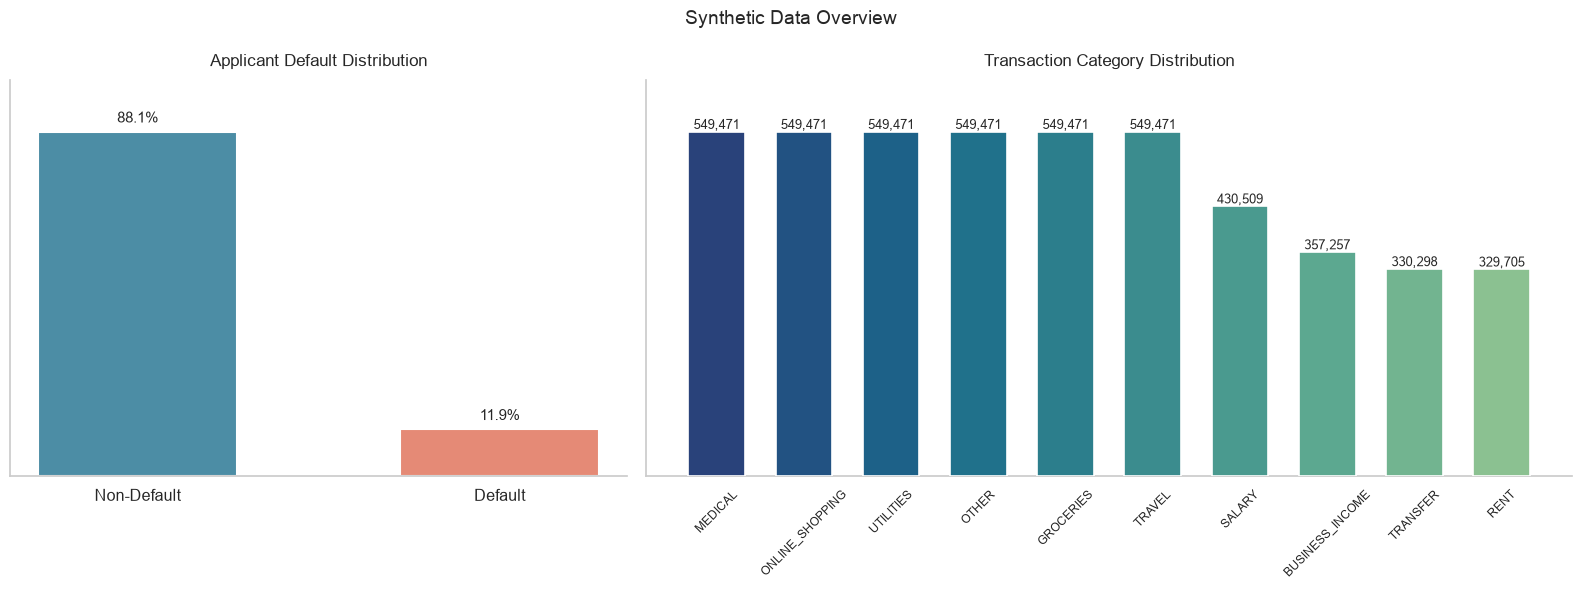

In [7]:
# Plot styling
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    gridspec_kw={"width_ratios": [1, 1.5]}
)

fig.suptitle("Synthetic Data Overview", fontsize=14, y=0.98)

# 1. Default distribution
default_dist = (
    applicants["default_12m"].value_counts(normalize=True).sort_index()
)

bars = axes[0].bar(
    ["Non-Default", "Default"],
    default_dist.values,
    color=["#4C8DA5", "#E58A76"],
    width=0.55,
    edgecolor="white",
    linewidth=1.5
)

axes[0].set_title("Applicant Default Distribution", fontsize=12, fontweight="normal", pad=10)

max_count = default_dist.max()
axes[0].set_ylim(0, max_count * 1.15)
axes[0].set_yticks([])

for bar, value in zip(bars, default_dist.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{value:.1%}",
        ha="center",
        va="bottom",
        fontsize=11
    )


# 2. Transaction category counts
category_counts = transactions["category"].value_counts()

bars = axes[1].bar(
    category_counts.index,
    category_counts.values,
    color=sns.color_palette("crest_r", len(category_counts)),
    width=0.65,
    edgecolor="white",
    linewidth=1.2,
    zorder=3
)

axes[1].set_title("Transaction Category Distribution", fontsize=12, fontweight="normal", pad=10)
axes[1].tick_params(axis="x", labelsize=8.5, rotation=45)

max_perc = category_counts.max()
axes[1].set_ylim(0, max_perc * 1.15)
axes[1].set_yticks([])

# Add count labels
for bar in bars:
    height = bar.get_height()

    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        height + max_count * 0.015,
        f"{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Final formatting
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

sns.despine()

# Adjust spacing manually
fig.subplots_adjust(
    top=0.85,
    bottom=0.18,
    left=0.06,
    right=0.98,
    wspace=0.22
)

plt.tight_layout()
plt.show()

### A.1.5: Save the raw synthetic data

Parquet files are saved so later notebooks can be run in a fresh kernel without regenerating the population. Keep the seed and configuration alongside any experiment results.

In [8]:
DATA_DIR.mkdir(parents=True, exist_ok=True)
applicants.to_parquet(DATA_DIR / "applicants.parquet", index=False)
transactions.to_parquet(DATA_DIR / "transactions.parquet", index=False)

print("Saved:", DATA_DIR / "applicants.parquet")
print("Saved:", DATA_DIR / "transactions.parquet")

Saved: /Users/prabhudattagrawal/Personal Projects/NTC Transaction Nov26/github_upload/data/generated/applicants.parquet
Saved: /Users/prabhudattagrawal/Personal Projects/NTC Transaction Nov26/github_upload/data/generated/transactions.parquet


## Part A.2: Exploratory data analysis and cash-flow features

### Objective
Understand the generated transaction population and construct interpretable cash-flow features using only pre-application transactions.

**Outputs**
- *data/generated/cashflow_features.parquet*
- *data/generated/applicant_modeling.parquet*
- *data/generated/split_assignments.parquet* with train, validation, calibration, and test vintages

The target and simulation-only columns are retained only where required for analysis; generator-only columns are excluded from modelling inputs.

### A.2.1: Explore application vintages and transaction behaviour

Look for data coverage, transaction volume, category mix and broad cash-flow characteristics. Since this is synthetic data, these patterns reflect the generator design.

In [9]:
applicants = pd.read_parquet(DATA_DIR / "applicants.parquet")
transactions = pd.read_parquet(DATA_DIR / "transactions.parquet")

print("Applicants:", applicants.shape, "| columns:", applicants.shape[1])
print("Transactions:", transactions.shape, "| columns:", transactions.shape[1])

Applicants: (48000, 21) | columns: 21
Transactions: (4744595, 9) | columns: 9


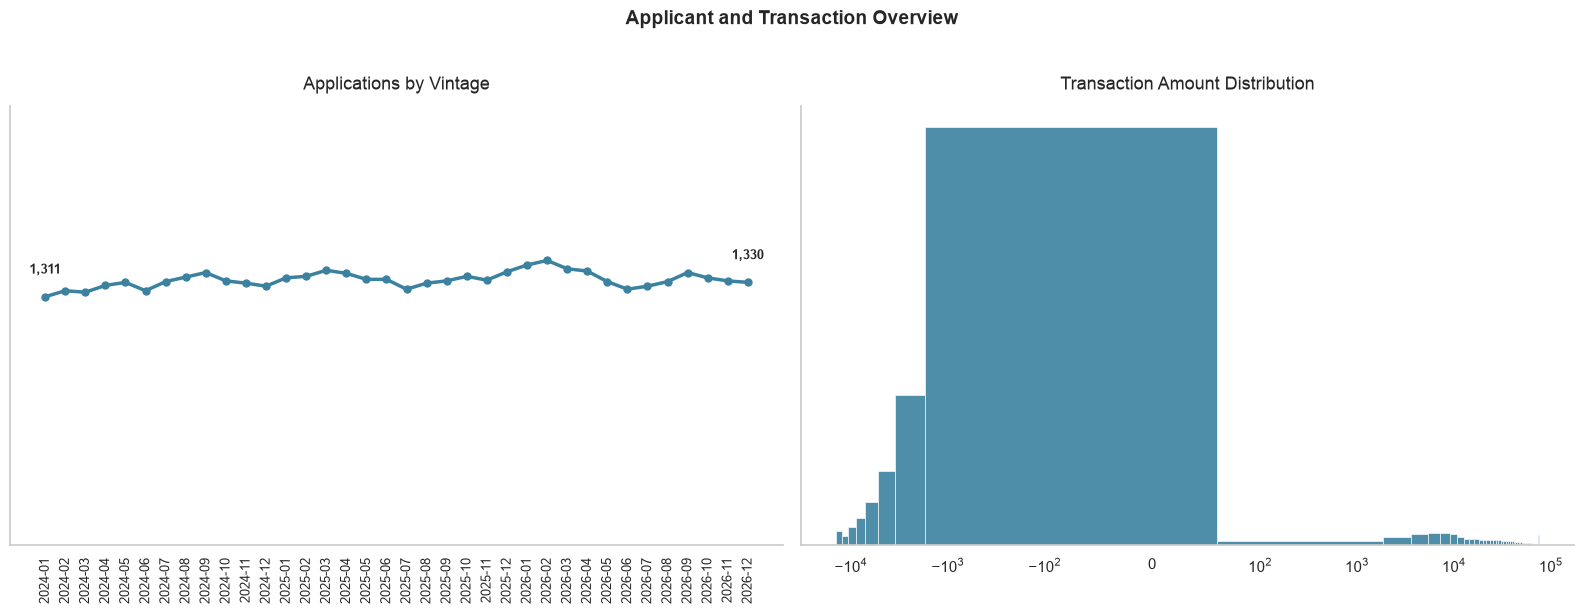

In [10]:
# Plot styling
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)

# Monthly application distribution
monthly_applications = applicants.groupby(
    applicants["application_date"].dt.to_period("M")
).size()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fig.suptitle(
    "Applicant and Transaction Overview",
    fontsize=14,
    fontweight="bold",
    y=1.02
)

# 1. Applications by vintage
monthly_applications.index = monthly_applications.index.astype(str)

axes[0].plot(
    monthly_applications.index,
    monthly_applications.values,
    color="#3B82A0",
    linewidth=2.5,
    marker="o",
    markersize=5
)

# Add data labels only for first and last month
first_idx = monthly_applications.index[0]
last_idx = monthly_applications.index[-1]
for x, y in [(first_idx, monthly_applications.iloc[0]), (last_idx, monthly_applications.iloc[-1])]:
    axes[0].text(
        x, y + monthly_applications.max() * 0.02,
        f"{y:,}",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

axes[0].set_title(
    "Applications by Vintage",
    fontsize=13,
    fontweight="normal",
    pad=12
)

axes[0].set_xlabel("")
axes[0].set_ylabel("")
axes[0].set_ylim(monthly_applications.min() * 0.75, monthly_applications.max() * 1.15)
axes[0].set_yticks([])
axes[0].tick_params(axis="x", rotation=90, labelsize=9)


# 2. Transaction amount distribution
amount_clipped = transactions["amount"].clip(
    lower=transactions["amount"].quantile(0.01),
    upper=transactions["amount"].quantile(0.99)
)

axes[1].hist(
    amount_clipped,
    bins=50,
    color="#3B82A0",
    edgecolor="white",
    linewidth=0.5,
    alpha=0.9
)

axes[1].set_xscale("symlog", linthresh=100)

axes[1].set_title(
    "Transaction Amount Distribution",
    fontsize=13,
    fontweight="normal",
    pad=12
)

axes[1].set_xlabel("")
axes[1].set_ylabel("")
axes[1].set_yticks([])


# Final formatting
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

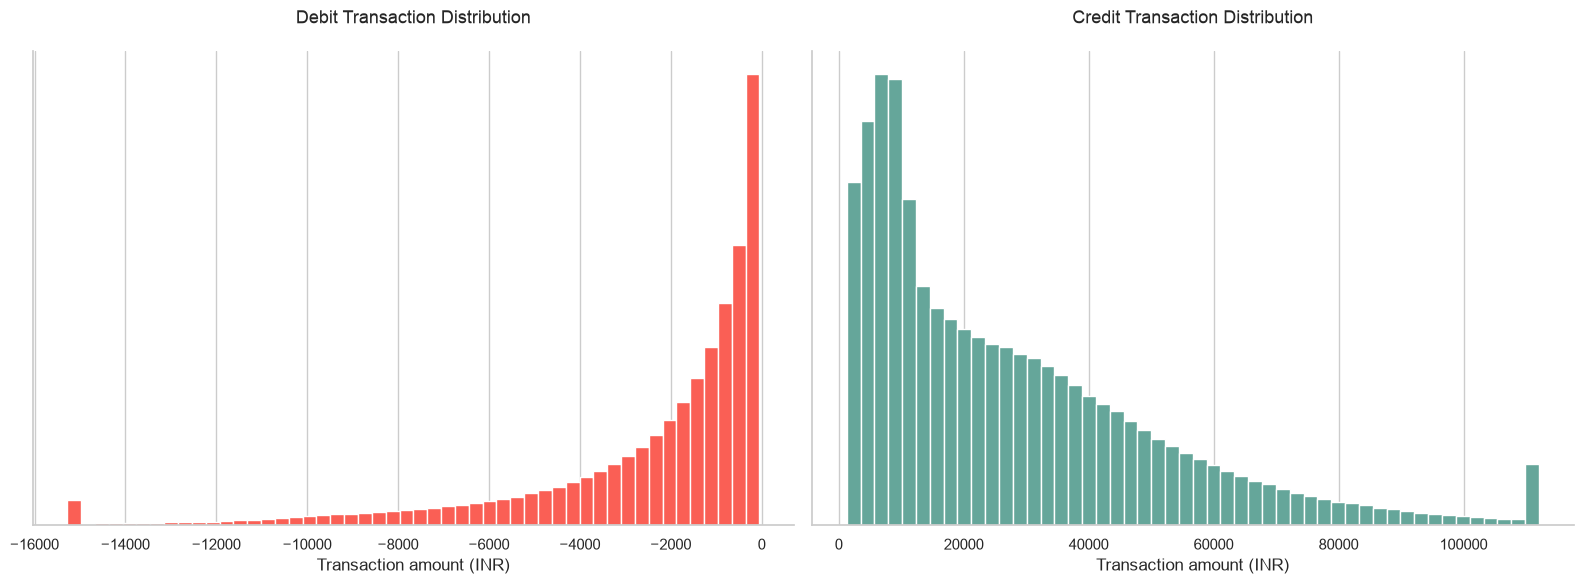

In [11]:
# Plot styling
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0,
)

transactions["transaction_type"] = np.where(
    transactions["amount"] > 0, "Credit", "Debit"
)

transactions.groupby("transaction_type")["amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, transaction_type in zip(
    axes, ["Debit", "Credit"]
):
    data = transactions.loc[
        transactions["transaction_type"] == transaction_type,
        "amount"
    ]

    ax.hist(
        data.clip(
            lower=data.quantile(0.01),
            upper=data.quantile(0.99)
        ),
        bins=50,
        color="#FA5F55" if transaction_type == "Debit" else "#65A69A",
        edgecolor="white"
    )

    ax.set_title(
        f"{transaction_type} Transaction Distribution",
        fontsize=13,
        fontweight="normal",
        pad=20
    )
    ax.set_xlabel("Transaction amount (INR)")
    ax.set_ylabel("")
    ax.set_yticks([])

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

### A.2.2: Build cash-flow features

The feature module:
- Filters transactions to `transaction_date < application_date`.
- Separates positive credits and negative debits.
- Aggregates monthly credits, debits, balances and transaction counts.
- Uses salary and business-income credits as the income proxy; transfers are not treated as income.
- Computes income-only volatility, non-transfer expense ratios, liquidity, transfer-reliance and income-frequency measures.

The feature calculations are intentionally transparent and interpretable. They do not use generator latents or post-application data.


In [12]:
from src.features.cashflow_features import build_cashflow_features, feature_columns

cashflow_features = build_cashflow_features(applicants, transactions)
print("Feature matrix shape:", cashflow_features.shape)
display(cashflow_features.head())

Feature matrix shape: (48000, 30)


,applicant_id,avg_monthly_credits,std_monthly_credits,avg_monthly_debits,avg_closing_balance,min_closing_balance,avg_tx_count,observed_months,opening_balance,spend_housing_share,spend_groceries_share,spend_utilities_share,spend_transport_share,spend_shopping_share,spend_medical_share,spend_other_share,transfer_in_ratio,transfer_out_ratio,income_cv,balance_cv,expense_to_income_ratio,opening_balance_ratio,liquidity_months_proxy,income_event_frequency,account_tenure_months,account_type_checking_share,account_type_savings_share,account_type_wallet_share,has_housing_payment,avg_monthly_housing_payment
0,0,86354.646006,6801.987098,16838.358745,544587.607005,154929.985711,7.666667,12,80528.193707,0.000000,0.124491,0.004612,0.019802,0.012500,0.002305,0.017413,0.015366,0.085392,0.065438,0.458552,0.181121,0.947071,10.059414,1.000000,79,1.0,0.0,0.0,0,0.000000
1,1,59151.250349,25712.598680,12954.626819,370635.990576,71972.198672,9.916667,12,47015.127372,0.000000,0.098585,0.026301,0.007195,0.016404,0.023392,0.000851,0.006282,0.216279,0.441093,0.500201,0.172723,0.799840,7.088203,3.333333,46,0.0,1.0,0.0,0,0.000000
2,2,110519.041292,48218.122084,42045.523291,473428.166338,116260.654669,9.500000,12,76893.255893,0.000000,0.113313,0.096589,0.031821,0.044028,0.021485,0.061606,0.006135,0.036426,0.435015,0.540225,0.368838,0.700035,2.869573,3.083333,97,0.0,0.0,1.0,0,0.000000
3,3,34298.086668,16981.204732,9675.570828,151784.988965,48934.428519,9.750000,12,7785.074109,0.000000,0.103937,0.005460,0.057676,0.012866,0.031065,0.005964,0.095847,0.304601,0.496614,0.560483,0.216962,0.251037,7.271781,2.916667,43,1.0,0.0,0.0,0,0.000000
4,4,25715.520553,3995.148788,13682.454323,91135.700212,27421.054622,8.500000,12,8599.891121,0.160145,0.082608,0.122552,0.020487,0.022228,0.036485,0.083556,0.083224,0.090132,0.137003,0.469232,0.528038,0.364768,2.202456,1.000000,106,1.0,0.0,0.0,1,3775.480042


In [13]:
feature_cols = [
    col for col in feature_columns(cashflow_features)
    if col not in [
        "observed_months",
        "account_tenure_months",
        "account_type_checking_share",
        "account_type_savings_share",
        "account_type_wallet_share",
        "has_housing_payment",
    ]
]
display(cashflow_features[feature_cols].describe().round(2).T)

,count,mean,std,min,25%,50%,75%,max
avg_monthly_credits,48000.0,47143.26,23684.06,7280.74,30725.38,42069.54,57782.38,341946.15
std_monthly_credits,48000.0,9281.00,8127.62,0.00,4051.63,6349.65,11962.76,130162.76
avg_monthly_debits,48000.0,18204.21,10558.34,1756.72,11019.82,15583.44,22306.92,151182.57
avg_closing_balance,48000.0,201272.45,121896.14,-3541.34,116895.74,175610.64,255854.03,1992591.74
min_closing_balance,48000.0,49275.85,32298.23,-19459.73,27050.35,41892.52,63000.80,513473.89
avg_tx_count,48000.0,8.63,0.98,7.00,7.75,8.58,8.83,12.00
opening_balance,48000.0,19358.89,16377.86,330.36,7555.77,14755.16,26372.11,221868.93
spend_housing_share,48000.0,0.09,0.09,0.00,0.00,0.09,0.15,0.47
spend_groceries_share,48000.0,0.09,0.06,0.00,0.05,0.07,0.11,0.50
spend_utilities_share,48000.0,0.05,0.04,0.00,0.02,0.04,0.07,0.49


### A.2.3: Outlier review

Train-fitted IQR bounds are shown for diagnostics. Applicants are **not** removed: using training-derived bounds to drop test applicants would change the evaluation cohort and break the chronological split.


### A.2.4: Review feature distributions and relationships

The correlation matrix is a diagnostic tool. It is not a variable-selection procedure and does not establish causality.

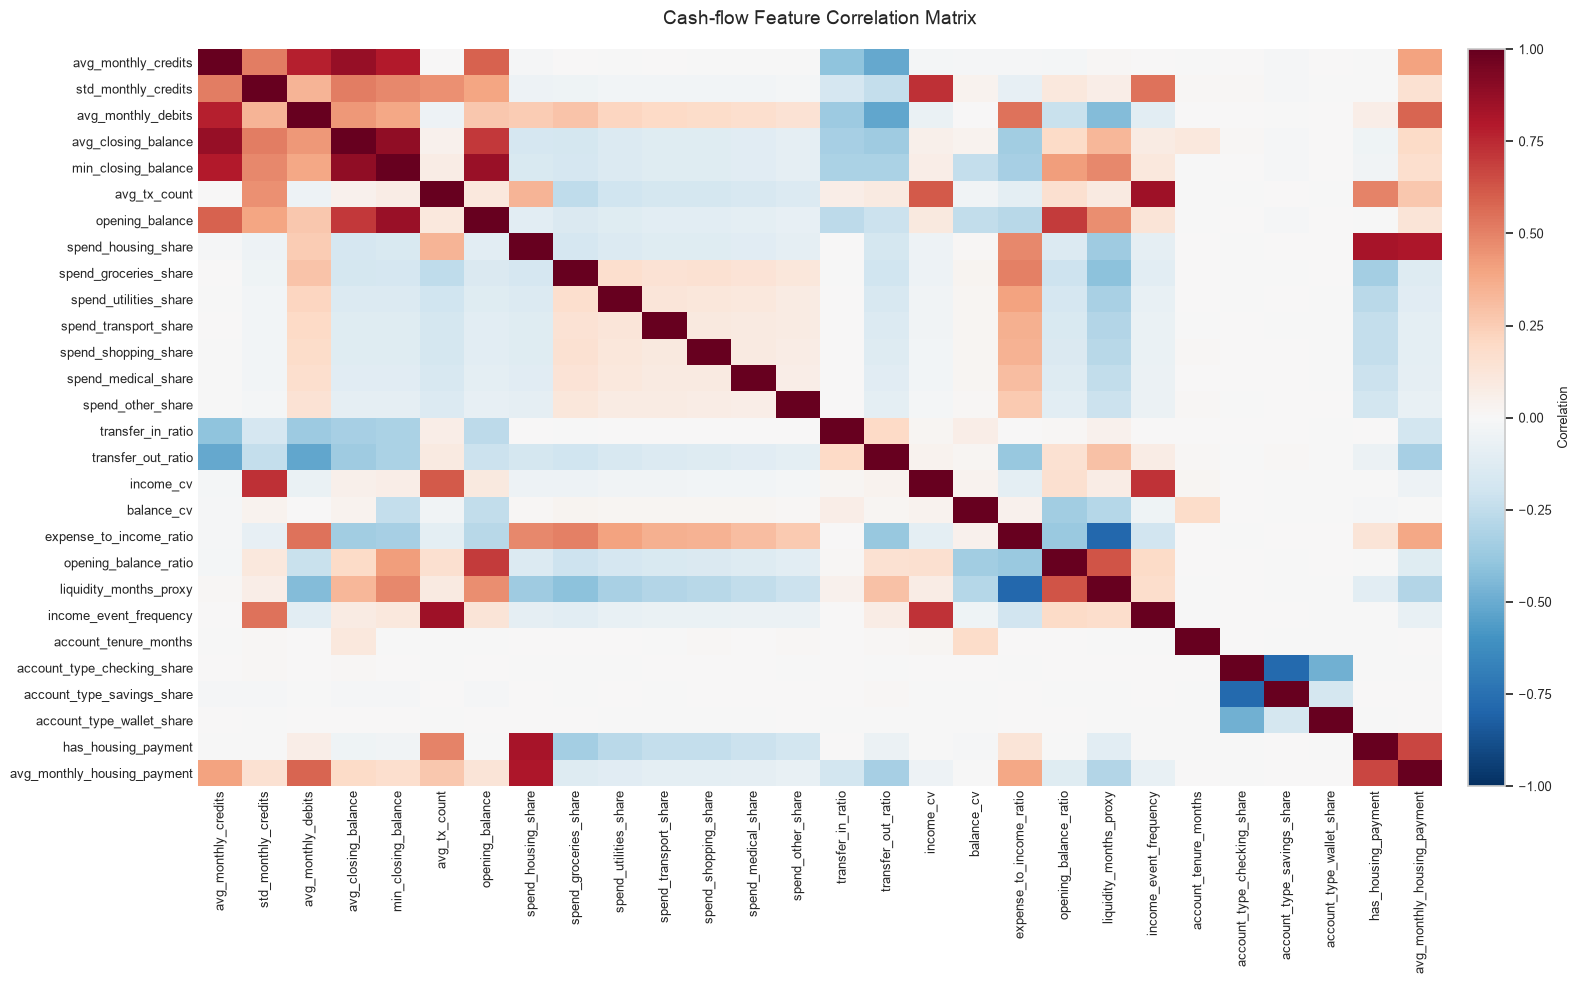

In [14]:
# Feature correlation matrix
feature_cols = [
    col for col in feature_columns(cashflow_features)
    if col != "observed_months"
]
corr = cashflow_features[feature_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(16, 10))

# Correlation heatmap
im = ax.imshow(
    corr, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest"
)

# Axis labels
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, fontsize=9, rotation=90)

ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index, fontsize=9)

# Remove distracting tick marks and gridlines
ax.tick_params(axis="both", length=0)
ax.grid(False)

# Remove plot borders
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    "Cash-flow Feature Correlation Matrix",
    fontsize=14, fontweight="normal", pad=18
)

# Colourbar
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("Correlation", fontsize=9)
cbar.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()


### A.2.5: Create chronological train, validation and test cohorts

Unlike a random train-test split, applicants are assigned to cohorts based on their application dates. This ensures that the model is trained on historical applicants and evaluated on progressively later applicants, simulating a real-world banking scenario in which a credit-risk model is developed using past applications and subsequently applied to new applicants.

The earliest application-month vintages are allocated to the training cohort, followed by validation, while the latest vintages are reserved for testing. Applicants from the same application month remain within the same cohort, preserving the chronological sequence.

This approach follows an out-of-time (OOT) validation design, providing a more realistic assessment of how well the model generalises to future applicant populations. It also allows us to evaluate whether changes in applicant characteristics, transaction behaviour and underlying credit risk over time affect model performance.

In [15]:
# Drop duplicate columns from cashflow_features that already exist in applicants
# (e.g., account_tenure_months is in both)
applicant_cols = set(applicants.columns)
cashflow_cols_to_use = [c for c in cashflow_features.columns if c not in applicant_cols or c == "applicant_id"]

applicant_modeling = applicants.merge(
    cashflow_features[cashflow_cols_to_use], on="applicant_id", how="left", validate="one_to_one"
)
print(applicant_modeling.shape)
display(applicant_modeling.head())

(48000, 49)


,applicant_id,application_date,account_open_date,account_tenure_months,account_type,housing_status,housing_cost,profile,base_income,default_12m,default_probability,p_default_conditional,p_default_realized,obligation_latent,income_cv_latent,initial_balance_ratio_latent,sequence_stress_latent,payment_risk_latent,income_timing_risk_latent,spending_tempo_risk_latent,transfer_reliance_risk_latent,avg_monthly_credits,std_monthly_credits,avg_monthly_debits,avg_closing_balance,min_closing_balance,avg_tx_count,observed_months,opening_balance,spend_housing_share,spend_groceries_share,spend_utilities_share,spend_transport_share,spend_shopping_share,spend_medical_share,spend_other_share,transfer_in_ratio,transfer_out_ratio,income_cv,balance_cv,expense_to_income_ratio,opening_balance_ratio,liquidity_months_proxy,income_event_frequency,account_type_checking_share,account_type_savings_share,account_type_wallet_share,has_housing_payment,avg_monthly_housing_payment
0,0,2026-09-01,2020-02-01,79,CHECKING,OWNED_OUTRIGHT,0.000000,SALARIED_STABLE,89821.145187,0,0.020480,0.033045,0.020480,0.197310,0.06,0.896529,0.182886,0.626862,0.589364,0.472604,0.184379,86354.646006,6801.987098,16838.358745,544587.607005,154929.985711,7.666667,12,80528.193707,0.000000,0.124491,0.004612,0.019802,0.012500,0.002305,0.017413,0.015366,0.085392,0.065438,0.458552,0.181121,0.947071,10.059414,1.000000,1.0,0.0,0.0,0,0.000000
1,1,2026-11-01,2023-01-01,46,SAVINGS,FAMILY,0.000000,SELF_EMPLOYED,55902.113418,0,0.042834,0.037718,0.042834,0.190550,0.38,0.841011,-0.003423,0.438485,0.323272,0.430571,0.439149,59151.250349,25712.598680,12954.626819,370635.990576,71972.198672,9.916667,12,47015.127372,0.000000,0.098585,0.026301,0.007195,0.016404,0.023392,0.000851,0.006282,0.216279,0.441093,0.500201,0.172723,0.799840,7.088203,3.333333,0.0,1.0,0.0,0,0.000000
2,2,2026-03-01,2018-02-01,97,WALLET,FAMILY,0.000000,SELF_EMPLOYED,98898.732905,1,0.142920,0.170726,0.142920,0.394289,0.38,0.777487,0.201047,0.717904,0.552892,0.422391,0.200291,110519.041292,48218.122084,42045.523291,473428.166338,116260.654669,9.500000,12,76893.255893,0.000000,0.113313,0.096589,0.031821,0.044028,0.021485,0.061606,0.006135,0.036426,0.435015,0.540225,0.368838,0.700035,2.869573,3.083333,0.0,0.0,1.0,0,0.000000
3,3,2025-06-01,2021-11-01,43,CHECKING,FAMILY,0.000000,SELF_EMPLOYED,30369.476308,0,0.035171,0.060321,0.035171,0.227467,0.38,0.256337,0.076461,0.449096,0.538404,0.429634,0.719689,34298.086668,16981.204732,9675.570828,151784.988965,48934.428519,9.750000,12,7785.074109,0.000000,0.103937,0.005460,0.057676,0.012866,0.031065,0.005964,0.095847,0.304601,0.496614,0.560483,0.216962,0.251037,7.271781,2.916667,1.0,0.0,0.0,0,0.000000
4,4,2025-07-01,2016-09-01,106,CHECKING,RENTING,3826.388313,HIGH_OBLIGATION,24960.578274,0,0.048214,0.065284,0.048214,0.521618,0.12,0.344525,0.038810,0.145005,0.865514,0.353139,0.252566,25715.520553,3995.148788,13682.454323,91135.700212,27421.054622,8.500000,12,8599.891121,0.160145,0.082608,0.122552,0.020487,0.022228,0.036485,0.083556,0.083224,0.090132,0.137003,0.469232,0.528038,0.364768,2.202456,1.000000,1.0,0.0,0.0,1,3775.480042


In [16]:
applicant_modeling.to_parquet(DATA_DIR / "applicant_modeling.parquet", index=False)


In [17]:
applicant_modeling = pd.read_parquet(DATA_DIR / "applicant_modeling.parquet")
print("Reloaded applicant_modeling:", applicant_modeling.shape)

Reloaded applicant_modeling: (48000, 49)


In [18]:
from src.data.dataset import temporal_split_with_calibration
from src.data.generate_data import GENERATOR_ONLY_COLUMNS

# Exclude every simulation-only field from the modelling dataset. The shared
# list is the same one used by src/experiment.py.
applicant_modeling = applicant_modeling.drop(
    columns=[c for c in GENERATOR_ONLY_COLUMNS if c in applicant_modeling.columns]
)

train, valid, calibration, test = temporal_split_with_calibration(
    applicant_modeling,
    valid_fraction=float(cfg["experiment"]["validation_fraction_by_time"]),
    calibration_fraction=float(cfg["experiment"]["calibration_fraction_by_time"]),
    test_fraction=float(cfg["experiment"]["test_fraction_by_time"])
)

split_rows = pd.concat([
    train[["applicant_id"]].assign(split="train"),
    valid[["applicant_id"]].assign(split="validation"),
    calibration[["applicant_id"]].assign(split="calibration"),
    test[["applicant_id"]].assign(split="test")
], ignore_index=True)


assert train.application_date.max() < valid.application_date.min()
assert valid.application_date.max() < calibration.application_date.min()
assert calibration.application_date.max() < test.application_date.min()
assert split_rows["applicant_id"].is_unique


In [19]:
print("Train:", len(train), train["application_date"].min(), "to", train["application_date"].max().date())
print("Validation:", len(valid), valid["application_date"].min(), "to", valid["application_date"].max().date())
print("Calibration:", len(calibration), calibration["application_date"].min(), "to", calibration["application_date"].max().date())
print("Test:", len(test), test["application_date"].min(), "to", test["application_date"].max().date())
print("Default rates:")
print(f"  train:        {train.default_12m.mean():.4f}")
print(f"  validation:   {valid.default_12m.mean():.4f}")
print(f"  calibration:  {calibration.default_12m.mean():.4f}")
print(f"  test:         {test.default_12m.mean():.4f}")

Train: 29269 2024-01-01 00:00:00 to 2025-10-01
Validation: 6737 2025-11-01 00:00:00 to 2026-03-01
Calibration: 2676 2026-04-01 00:00:00 to 2026-05-01
Test: 9318 2026-06-01 00:00:00 to 2026-12-01
Default rates:
  train:        0.1209
  validation:   0.1204
  calibration:  0.1132
  test:         0.1146


In [20]:
[name for name in globals() if any(
    word in name.lower()
    for word in ["split", "train", "valid", "test"]
)]

['temporal_split_with_calibration', 'train', 'valid', 'test', 'split_rows']

In [21]:
# List of applicant IDs for the training cohort.
train_ids = train["applicant_id"].unique()


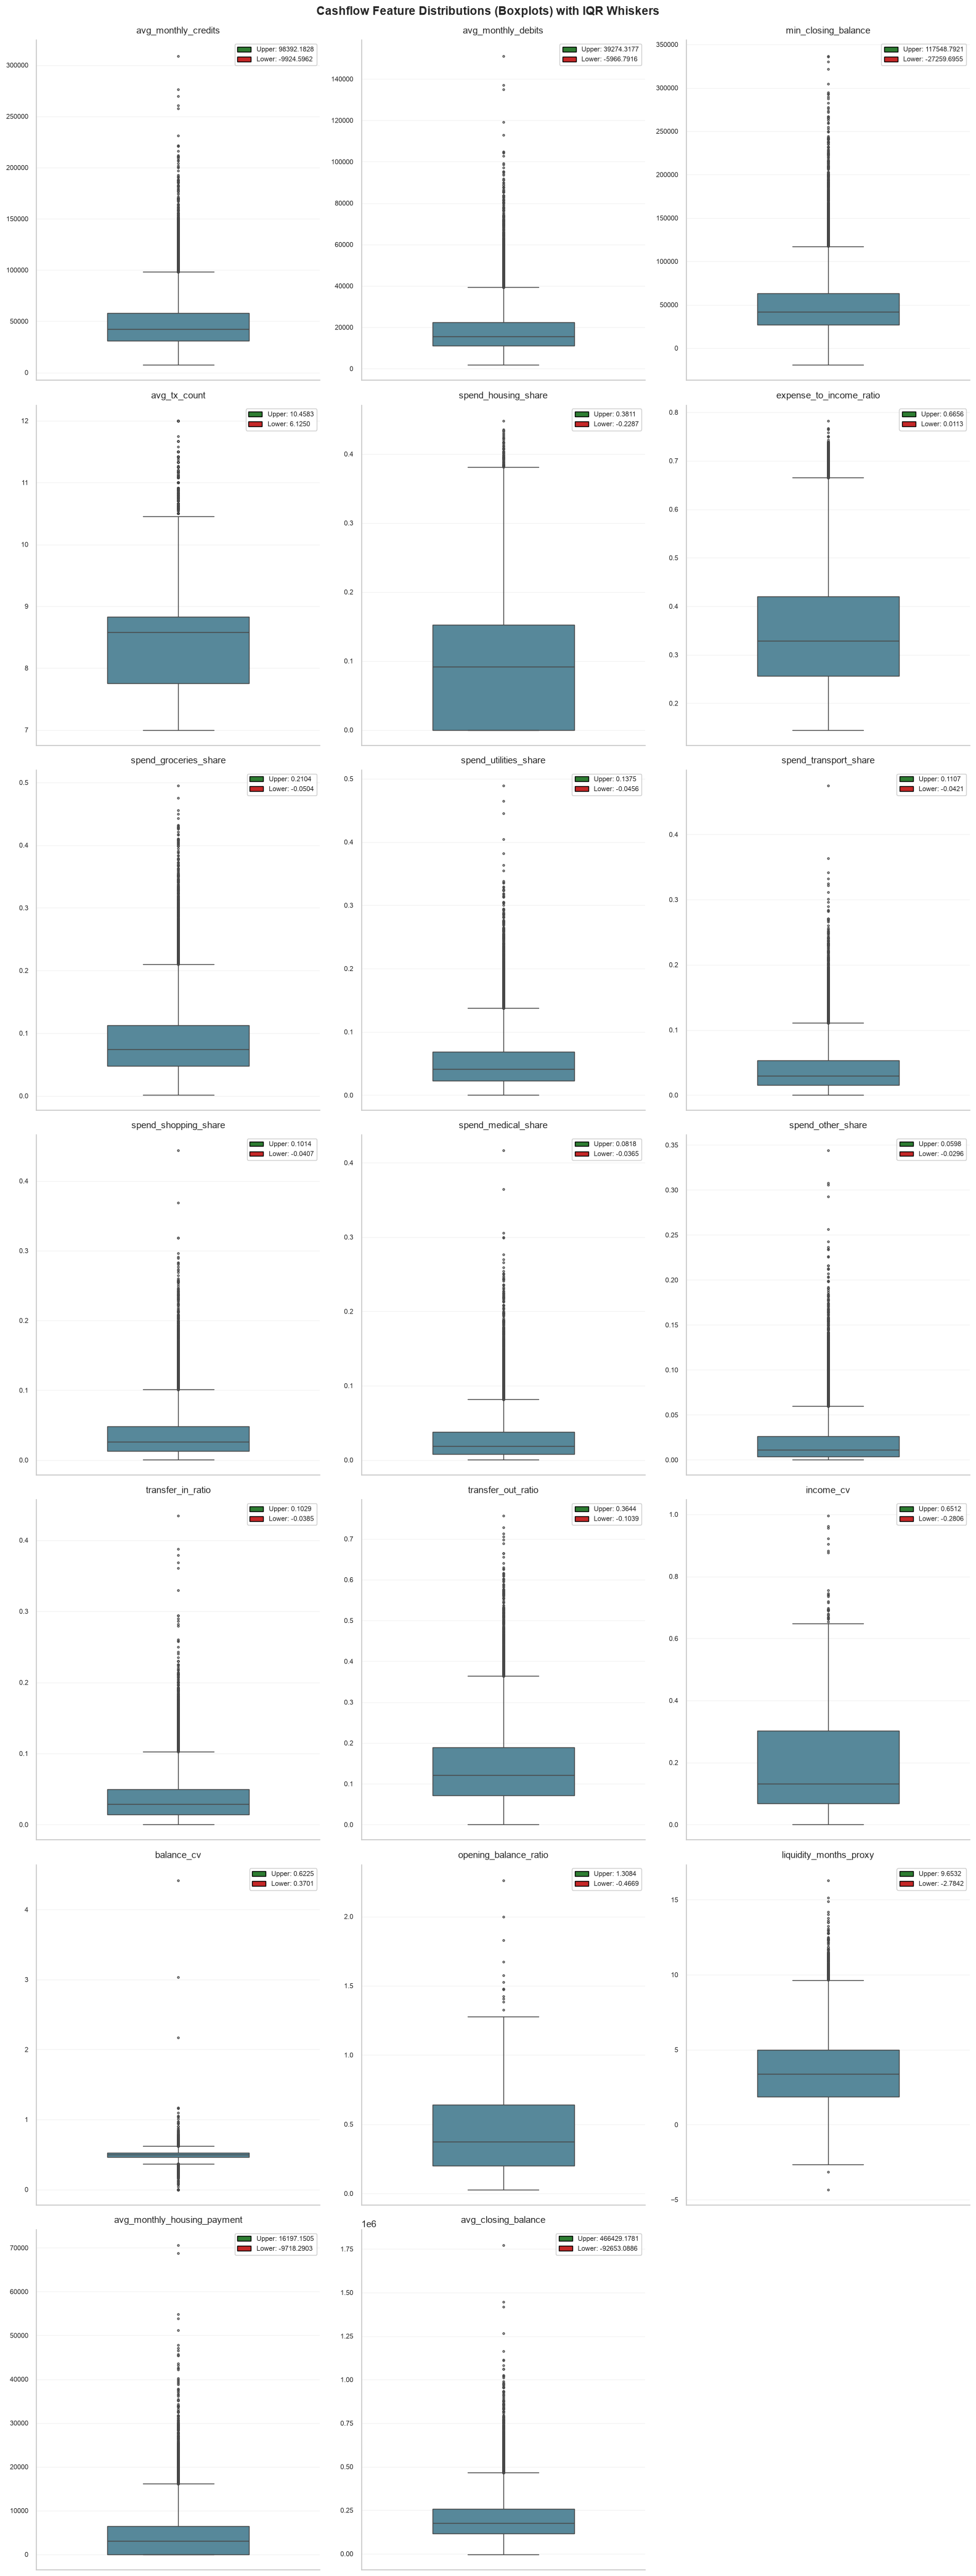

In [22]:
# Boxplots for cashflow features to visualize distributions and identify outliers
cashflow_features_train = cashflow_features[cashflow_features["applicant_id"].isin(train_ids)]

feature_cols = [
    col for col in feature_columns(cashflow_features_train)
    if col != "observed_months"
]

# Select key features for boxplot visualization
key_features = [
    "avg_monthly_credits", "avg_monthly_debits",
    "min_closing_balance", "avg_tx_count",
    "spend_housing_share", "expense_to_income_ratio",
    "spend_groceries_share", "spend_utilities_share",
    "spend_transport_share", "spend_shopping_share",
    "spend_medical_share", "spend_other_share",
    "transfer_in_ratio", "transfer_out_ratio",
    "income_cv", "balance_cv",
    "opening_balance_ratio", "liquidity_months_proxy",
    "avg_monthly_housing_payment", "avg_closing_balance",
]

# Filter to only features that exist
key_features = [f for f in key_features if f in cashflow_features_train.columns]

n_features = len(key_features)
n_cols = 3
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 6 * n_rows))
axes = axes.flatten()

for i, feature in enumerate(key_features):
    ax = axes[i]
    # Compute IQR bounds for annotation from TRAINING data only
    q1 = cashflow_features_train[feature].quantile(0.25)
    q3 = cashflow_features_train[feature].quantile(0.75)
    iqr = q3 - q1
    lower_whisker = q1 - 1.5 * iqr
    upper_whisker = q3 + 1.5 * iqr

    sns.boxplot(
        y=cashflow_features_train[feature],
        ax=ax,
        color="#4C8DA5",
        width=0.5,
        fliersize=2,
        linewidth=1
    )
    ax.set_title(f"{feature}", fontsize=11, fontweight="normal", pad=8)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Add whisker values as a legend box in top right
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor="#2E7D32", edgecolor="black", label=f"Upper: {upper_whisker:.4f}"),
        Patch(facecolor="#C62828", edgecolor="black", label=f"Lower: {lower_whisker:.4f}"),
    ]
    ax.legend(handles=legend_elements, loc="upper right", fontsize=8, framealpha=0.9)

# Hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Cashflow Feature Distributions (Boxplots) with IQR Whiskers", fontsize=14, fontweight="bold", y=0.995)

plt.tight_layout()
plt.show()


In [23]:
from src.features.cashflow_features import winsorize_extreme_features

# Review train-fitted IQR bounds. We do not drop applicants: removing test
# applicants using train-derived bounds would change the evaluation cohort.
review_columns = ["balance_cv", "income_cv"]
_, outlier_bounds, outlier_counts = winsorize_extreme_features(
    features=cashflow_features,
    train_ids=train_ids,
    columns=review_columns,
)

print("Applicants outside train IQR bounds (retained):")
print(pd.Series(outlier_counts, name="n_outside"))
print("\nOutlier thresholds in each dimension:")
print(pd.DataFrame(outlier_bounds).T)


Applicants outside train IQR bounds (retained):
balance_cv    2054
income_cv       51
Name: n_outside, dtype: int64

Outlier thresholds in each dimension:
               lower     upper
balance_cv  0.370092  0.622473
income_cv  -0.280553  0.651199


- All applicants are retained. The IQR review is diagnostic only, so the test cohort is not selected using training-derived bounds. Default rates for each cohort are printed above.


### A.2.6: Persist feature data and split assignments

The split file is the authoritative applicant-to-cohort mapping for the remaining notebooks. Do not recreate a different split in later steps.

In [24]:
# All applicants are retained. The IQR review above is diagnostic only, so the
# modelling table, feature table and split assignments stay aligned.
remaining_ids = set(cashflow_features["applicant_id"])
applicant_modeling = applicant_modeling[
    applicant_modeling["applicant_id"].isin(remaining_ids)
].copy()
split_rows = split_rows[
    split_rows["applicant_id"].isin(remaining_ids)
].copy()

# Recreate cohorts from the original temporal assignments.
train = split_rows[split_rows["split"] == "train"].copy()
valid = split_rows[split_rows["split"] == "validation"].copy()
calibration = split_rows[split_rows["split"] == "calibration"].copy()
test = split_rows[split_rows["split"] == "test"].copy()


In [25]:
assert set(cashflow_features["applicant_id"]) == set(applicant_modeling["applicant_id"])
assert set(cashflow_features["applicant_id"]) == set(split_rows["applicant_id"])
assert split_rows["applicant_id"].is_unique

In [26]:
cashflow_features.to_parquet(DATA_DIR / "cashflow_features.parquet", index=False)
applicant_modeling.to_parquet(DATA_DIR / "applicant_modeling.parquet", index=False)
split_rows.to_parquet(DATA_DIR / "split_assignments.parquet", index=False)

print("Saved Parquet cash-flow features, modelling table and split assignments.")

Saved Parquet cash-flow features, modelling table and split assignments.


# Part B: Transaction Representation Learning

## Part B.1: Self-Supervised Transaction Pretraining

### Objective
Train a small Transformer to predict masked transaction categories from the surrounding transaction sequence. This is a self-supervised task: it does not use the default label.

**Critical leakage control:** the encoder is pretrained only on applicants in the training vintage. Validation and test applicants are not used to fit the encoder.

**Output:** `artifacts/transaction_encoder.pt` and `artifacts/pretraining_history.csv`.

### B.1.1: Load transactions and the fixed cohort assignments

In [27]:
from src.data.sequences import encode_sequences, to_tensors
from src.models.pretrain import pretrain, select_device

applicants = pd.read_parquet(DATA_DIR / "applicant_modeling.parquet")
transactions = pd.read_parquet(DATA_DIR / "transactions.parquet")
splits = pd.read_parquet(DATA_DIR / "split_assignments.parquet")

train_ids = splits.loc[splits["split"] == "train", "applicant_id"].astype(int).tolist()
valid_ids = splits.loc[splits["split"] == "validation", "applicant_id"].astype(int).tolist()
test_ids = splits.loc[splits["split"] == "test", "applicant_id"].astype(int).tolist()

print("Train applicants:", len(train_ids))
print("Validation applicants:", len(valid_ids))
print("Test applicants:", len(test_ids))
print("Training device:", select_device())

Train applicants: 29269
Validation applicants: 6737
Test applicants: 9318
Training device: mps


### B.1.2: Encode training applicants' transaction sequences

Each transaction is represented by:
- Category ID
- Unsaturated `log1p` absolute amount
- `log1p` amount relative to the applicant's median transaction amount
- Calendar-time bucket
- Credit/debit direction
- Padding mask

The category vocabulary and calendar-time buckets are fixed in the source code. Each applicant sequence is sorted chronologically, truncated to the configured 272-transaction window, and right-padded.

In [28]:
from sklearn.model_selection import train_test_split

max_length = int(cfg["model"]["max_sequence_length"])

train_applicants = applicants[
    applicants["applicant_id"].isin(train_ids)
].copy()

train_sequences = encode_sequences(
    train_applicants, transactions, max_length=max_length
)
pretrain_fit_ids, pretraining_validation_ids = train_test_split(
    train_ids,
    test_size=float(cfg["model"]["pretraining_validation_fraction"]),
    random_state=SEED
)
train_tensors = to_tensors(train_sequences, pretrain_fit_ids, max_length=max_length)
pretraining_validation_tensors = to_tensors(
    train_sequences, pretraining_validation_ids, max_length=max_length
)

for key, tensor in train_tensors.items():
    print(f"{key:16s} shape={tuple(tensor.shape)} dtype={tensor.dtype}")

assert train_tensors["category"].shape[0] == len(pretrain_fit_ids)
assert set(pretrain_fit_ids).isdisjoint(pretraining_validation_ids)
assert set(pretrain_fit_ids + pretraining_validation_ids).issubset(set(train_ids))

category         shape=(26342, 272) dtype=torch.int64
amount           shape=(26342, 272) dtype=torch.float32
relative_amount  shape=(26342, 272) dtype=torch.float32
time             shape=(26342, 272) dtype=torch.int64
direction        shape=(26342, 272) dtype=torch.int64
padding          shape=(26342, 272) dtype=torch.bool


### B.1.3: Pretrain the Transformer

#### B.1.3.1: Objective of Transaction Encoder Pretraining

In a traditional credit-risk modelling framework, applicant risk is generally assessed using structured variables such as income, employment details, credit bureau attributes, existing liabilities and repayment history. However, New-to-Credit (NTC) applicants often have limited or no formal credit bureau history, making it difficult to assess their repayment capacity and financial behaviour using conventional credit-risk variables alone.

To address this limitation, we use transaction-level financial information to learn representations of an applicant's financial behaviour. Instead of relying exclusively on manually engineered summary variables, we introduce a **Transformer-based transaction encoder** that can learn patterns and relationships directly from sequences of financial transactions.

The objective of pretraining is to teach the encoder to extract meaningful behavioural representations from transaction data before using these representations in the downstream credit-risk prediction task.

This is a **self-supervised learning approach**: the encoder learns from the structure and characteristics of transaction data without requiring default labels during the pretraining stage. This is particularly relevant for NTC modelling, where labelled credit-performance information may be limited or unavailable for certain applicant segments.

#### B.1.3.2: Why a Transformer-Based Encoder?

Financial transactions are not independent observations. Their sequence, frequency, timing, value and relationship with other transactions can reveal important information about an applicant's financial behaviour.

For example, consider the following transaction patterns:

- **Income regularity:** Recurring salary credits may indicate a relatively stable source of income.
- **Spending behaviour:** Regular rent, utility and other essential payments can help characterise an applicant's financial commitments.
- **Cash-flow volatility:** Significant fluctuations in account balances or transaction amounts may indicate inconsistent financial activity.
- **Credit and debit patterns:** The relationship between incoming and outgoing funds can provide insights into an applicant's cash-flow position.
- **Behavioural changes:** Changes in transaction frequency, spending patterns or incoming funds over time may reveal changes in financial circumstances.

A conventional tabular model generally relies on these patterns being summarised into predefined features. A Transformer, on the other hand, uses an attention mechanism to learn relationships between different transactions within an applicant's transaction sequence.

The **self-attention mechanism** allows the model to assign different levels of importance to transactions based on their relevance to other transactions and the representation being learned. Multiple attention heads can learn different relationships in parallel, while stacked Transformer layers progressively process these relationships into richer representations.

This makes the architecture suitable for learning complex temporal and behavioural patterns from transaction-level financial data.

#### B.1.3.3: What Does the Transaction Encoder Learn?

The transaction encoder processes an applicant's transaction sequence and converts it into a numerical representation known as an **embedding**.

Conceptually, the process involves three stages:

1. **Transaction representation:** Individual transactions are represented numerically using the input features prepared during the data-processing and feature-engineering stages.
2. **Sequence learning:** The Transformer processes these transaction representations and learns relationships across the applicant's transaction history through its attention and feed-forward layers.
3. **Embedding generation:** The learned information is converted into a fixed-dimensional numerical representation that captures relevant characteristics of the applicant's financial behaviour.

For example, two applicants may have similar monthly transaction volumes but very different underlying financial behaviours. One may receive a consistent salary and maintain regular spending patterns, while another may have irregular credits and highly volatile outflows.

A well-trained encoder should be capable of learning useful distinctions between such transaction patterns, rather than relying only on aggregate transaction volumes.

The resulting embeddings act as **learned behavioural features** that can complement conventional applicant-level and cash-flow features in the downstream credit-risk model.


#### B.1.3.4: Pretraining Configuration

The encoder is pretrained using the training cohort's transaction tensors (`train_tensors`). The model architecture and optimisation parameters are controlled through the project configuration file.

| Parameter | Description | Modelling significance |
|---|---|---|
| **embedding_dim** | Dimensionality of the learned representation | Controls the capacity of the transaction representation |
| **attention_heads** | Number of attention heads | Allows the model to learn multiple relationships within transaction sequences |
| **transformer_layers** | Number of stacked Transformer layers | Controls the depth of sequence processing |
| **epochs** | Number of complete training iterations over the dataset | Determines how many times the model processes the training data |
| **batch_size** | Number of training examples processed per batch | Influences computational efficiency and optimisation behaviour |
| **learning_rate** | Optimisation step size | Controls how quickly model parameters are updated |
| **seed** | Random seed | Supports reproducibility across experiments |

These parameters are configurable, allowing the encoder architecture and training process to be adjusted without modifying the underlying implementation.

In [29]:
encoder, history = pretrain(
    tensors=train_tensors,
    output_path=ARTIFACT_DIR / "transaction_encoder.pt",
    embedding_dim=int(cfg["model"]["embedding_dim"]),
    heads=int(cfg["model"]["attention_heads"]),
    layers=int(cfg["model"]["transformer_layers"]),
    epochs=int(cfg["model"]["epochs"]),
    batch_size=int(cfg["model"]["batch_size"]),
    learning_rate=float(cfg["model"]["learning_rate"]),
    seed=SEED,
    validation_tensors=pretraining_validation_tensors,
    early_stopping_patience=int(cfg["model"]["early_stopping_patience"]),
    max_length=int(cfg["model"]["max_sequence_length"])
)

pretrain epoch 01/20: loss=1.5967, validation_loss=1.3756
pretrain epoch 02/20: loss=1.3387, validation_loss=1.2653
pretrain epoch 03/20: loss=1.2524, validation_loss=1.1973
pretrain epoch 04/20: loss=1.1975, validation_loss=1.1460
pretrain epoch 05/20: loss=1.1615, validation_loss=1.1021
pretrain epoch 06/20: loss=1.1099, validation_loss=1.0399
pretrain epoch 07/20: loss=1.0319, validation_loss=0.9548
pretrain epoch 08/20: loss=0.9692, validation_loss=0.9078
pretrain epoch 09/20: loss=0.9310, validation_loss=0.8678
pretrain epoch 10/20: loss=0.9042, validation_loss=0.8377
pretrain epoch 11/20: loss=0.8751, validation_loss=0.8233
pretrain epoch 12/20: loss=0.8529, validation_loss=0.7956
pretrain epoch 13/20: loss=0.8330, validation_loss=0.7668
pretrain epoch 14/20: loss=0.8132, validation_loss=0.7431
pretrain epoch 15/20: loss=0.7904, validation_loss=0.7250
pretrain epoch 16/20: loss=0.7722, validation_loss=0.7046
pretrain epoch 17/20: loss=0.7540, validation_loss=0.6876
pretrain epoch

#### B.1.3.5: Training the Encoder

The custom `pretrain()` function implements the Transformer-based self-supervised training pipeline. It takes the preprocessed transaction tensors as input, initialises the encoder architecture, and optimises its parameters using the configured training objective.

During training, the model processes batches of applicant transaction sequences, calculates the pretraining loss based on its learning objective, and updates its parameters through backpropagation and the configured optimiser.

The process is repeated over the specified number of epochs, allowing the encoder to progressively learn representations from the transaction data.

Importantly, the encoder is pretrained using only the training cohort. Validation and test transaction data are kept outside the pretraining process to preserve the integrity of the out-of-time evaluation framework.

The pretraining objective is independent of the downstream default prediction target. The `default_12m` label is not used to train the encoder; it is reserved for the subsequent supervised credit-risk modelling stage.

In [30]:
history_df = pd.DataFrame(history)
history_df.to_csv(ARTIFACT_DIR / "pretraining_history.csv", index=False)
display(history_df)

,epoch,loss,validation_loss
0,1,1.596654,1.375611
1,2,1.338716,1.265336
2,3,1.252408,1.197261
3,4,1.197472,1.145967
4,5,1.161518,1.102091
5,6,1.109882,1.039901
6,7,1.031914,0.954778
7,8,0.969230,0.907807
8,9,0.930983,0.867799
9,10,0.904172,0.837692


#### B.1.3.6: Saving the Encoder and Training History

Once pretraining is complete, the trained encoder is saved as a PyTorch model artefact (`transaction_encoder.pt`). This allows the learned representations to be reused in subsequent stages without having to repeat the entire pretraining process.

The training history is also exported to `pretraining_history.csv`. It records the metrics generated during training and provides a basis for evaluating convergence and comparing different model configurations.

The training loss should be monitored across epochs to assess whether the optimisation process is progressing as expected. A declining training loss generally indicates that the model is learning to optimise its pretraining objective; however, it does not by itself establish that the learned embeddings are useful for credit-risk prediction.

#### B.1.3.7: Role in the Downstream NTC Credit-Risk Model

The pretrained transaction encoder forms the representation-learning component of the overall NTC modelling framework.

Its purpose is to convert raw transaction sequences into learned behavioural representations that can be combined with engineered cash-flow features and other eligible applicant-level information.

These representations can then be supplied to a supervised credit-risk model trained to predict the applicant's 12-month default outcome (`default_12m`).

The overall modelling approach therefore combines:

- **Engineered features:** Explicit measures of income, expenditure, cash-flow patterns and transaction behaviour.
- **Learned embeddings:** Latent behavioural representations extracted by the Transformer encoder.
- **Supervised risk modelling:** A downstream model that uses the available applicant information to estimate default risk.

This approach aims to extract additional predictive information from transaction behaviour, particularly for applicants with limited or absent formal credit bureau history.

The ultimate effectiveness of the encoder will be assessed through downstream validation and out-of-time test performance, rather than pretraining loss alone.

### B.1.4: Plot the pretraining objective

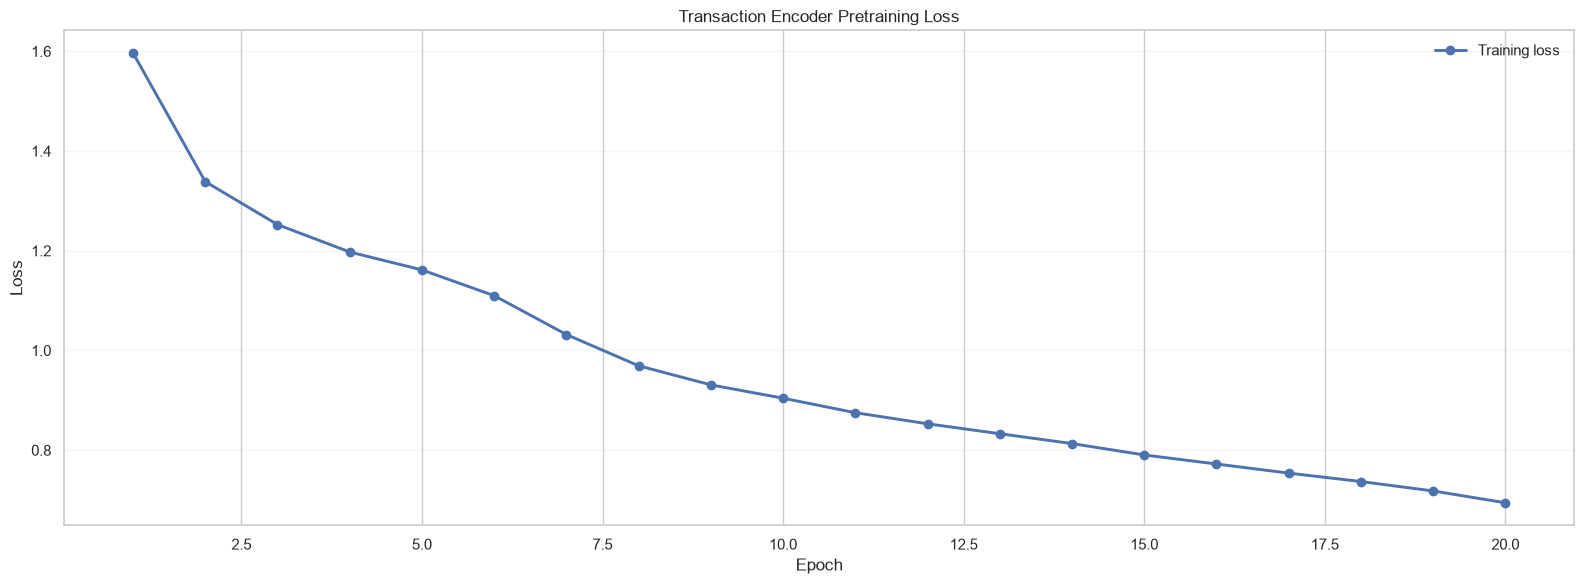

In [31]:
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(history_df["epoch"], history_df["loss"], linewidth=2.1, marker="o", label="Training loss")

ax.set_title("Transaction Encoder Pretraining Loss", fontweight="normal")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

### B.1.5: Record the pretraining scope

This small audit record makes the training population explicit. It is important to preserve it with the model artefact.

In [32]:
pretraining_audit = pd.DataFrame([{
    "pretraining_applicants": len(train_ids),
    "validation_applicants_used": 0,
    "test_applicants_used": 0,
    "max_sequence_length": max_length,
    "epochs": int(cfg["model"]["epochs"]),
    "seed": SEED,
    "device": str(select_device())
}])
pretraining_audit.to_csv(ARTIFACT_DIR / "pretraining_audit.csv", index=False)
display(pretraining_audit)

print("Encoder saved to:", ARTIFACT_DIR / "transaction_encoder.pt")

,pretraining_applicants,validation_applicants_used,test_applicants_used,max_sequence_length,epochs,seed,device
0,29269,0,0,272,20,42,mps


Encoder saved to: /Users/prabhudattagrawal/Personal Projects/NTC Transaction Nov26/github_upload/artifacts/transaction_encoder.pt


#### Interpretation
- Training loss measures the masked-category prediction task only.
- It is not a PD metric, default prediction metric or proof of business value.
- The next part uses the trained encoder to generate applicant-level embeddings for all cohorts without further fitting.

## Part B.2: Applicant Embedding Extraction

### Objective
Use the training-only pretrained Transformer to convert each applicant's transaction sequence into a fixed-length numerical representation.

The encoder is frozen: this notebook performs inference only. Validation, calibration, and test applicants are transformed but do not update model weights.

**Output:** `data/generated/finrep_embeddings.parquet`.

### B.2.1: Load applicant data, transactions and cohort assignments

In [33]:
from src.data.sequences import encode_sequences, to_tensors
from src.models.transaction_encoder import TransactionEncoder
from src.models.pretrain import extract_embeddings

applicants = pd.read_parquet(DATA_DIR / "applicant_modeling.parquet")
transactions = pd.read_parquet(DATA_DIR / "transactions.parquet")
splits = pd.read_parquet(DATA_DIR / "split_assignments.parquet")

# Applicant data, embeddings and splits share the same retained applicant IDs.
applicants = applicants.sort_values("applicant_id").reset_index(drop=True)
applicant_ids = applicants["applicant_id"].astype(int).tolist()

print("Applicants to embed:", len(applicant_ids))


Applicants to embed: 48000


### B.2.2: Recreate the model architecture and load the saved weights

The architecture parameters must match the configuration used during pretraining. The checkpoint contains the state dictionary and architecture metadata.

In [34]:
checkpoint_path = ARTIFACT_DIR / "transaction_encoder.pt"
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)

encoder = TransactionEncoder(
    embedding_dim=int(checkpoint["embedding_dim"]),
    attention_heads=int(checkpoint["heads"]),
    layers=int(checkpoint["layers"]),
    max_length=int(cfg["model"]["max_sequence_length"])
)
encoder.load_state_dict(checkpoint["state_dict"])
encoder.eval()

print("Loaded encoder checkpoint:", checkpoint_path)
print("Embedding dimension:", checkpoint["embedding_dim"])

Loaded encoder checkpoint: /Users/prabhudattagrawal/Personal Projects/NTC Transaction Nov26/github_upload/artifacts/transaction_encoder.pt
Embedding dimension: 32


### B.2.3: Encode all applicant sequences and extract embeddings

The encoder uses the same fixed category/time vocabularies, unsaturated absolute and applicant-relative amount inputs, and chronological ordering used during pretraining. The resulting applicant embedding is the mean of non-padding Transformer token outputs.

In [35]:
max_length = int(cfg["model"]["max_sequence_length"])

# Encode transaction sequences
all_sequences = encode_sequences(
    applicants,
    transactions,
    max_length=max_length
)

# Convert sequences to tensors
all_tensors = to_tensors(
    all_sequences,
    applicant_ids,
    max_length=max_length
)

# Extract embeddings as a NumPy array
embeddings = extract_embeddings(
    model=encoder,
    tensors=all_tensors,
    batch_size=int(cfg["model"]["batch_size"]) * 2
)

# Applicants were filtered before saving, so embeddings stay in applicant order.
embedding_columns = [
    f"finrep_{i:03d}"
    for i in range(embeddings.shape[1])
]

embedding_df = pd.DataFrame(
    embeddings,
    columns=embedding_columns
)

embedding_df.insert(
    0,
    "applicant_id",
    applicant_ids
)

print("Embedding matrix:", embeddings.shape)
print("Retained applicants:", len(applicant_ids))

display(embedding_df.head())

Embedding matrix: (48000, 32)
Retained applicants: 48000


,applicant_id,finrep_000,finrep_001,finrep_002,finrep_003,finrep_004,finrep_005,finrep_006,finrep_007,finrep_008,finrep_009,finrep_010,finrep_011,finrep_012,finrep_013,finrep_014,finrep_015,finrep_016,finrep_017,finrep_018,finrep_019,finrep_020,finrep_021,finrep_022,finrep_023,finrep_024,finrep_025,finrep_026,finrep_027,finrep_028,finrep_029,finrep_030,finrep_031
0,0,-0.544003,-0.778949,-0.523332,-0.773722,0.451610,2.020133,-0.683473,-1.057759,0.767255,0.578580,0.463684,0.173283,0.196852,-0.038652,0.032084,-0.808713,0.668612,0.423740,0.224593,-0.079819,-1.098825,0.434092,-0.067865,-0.263480,0.044419,0.321747,-0.550302,-0.718918,0.110994,0.476205,1.046626,-1.244118
1,1,-0.576786,0.427170,-0.625684,-0.322583,0.397325,1.476745,-0.661887,0.223705,0.812626,0.521036,1.103872,-0.372081,0.088398,0.615495,-0.763559,-0.910929,-0.502436,-0.131124,-0.551110,0.369127,-0.677785,-0.753543,-0.634309,-0.213307,-0.794234,1.042754,0.148901,-0.289876,-0.028090,1.219878,0.536006,-0.786902
2,2,-0.606211,0.636176,-0.559500,-0.571995,0.631479,1.624565,-1.158446,-0.023542,0.326168,0.580114,1.251827,-0.139393,0.346139,-0.692807,-0.485359,-0.876226,-0.365843,0.263133,-0.343197,0.702865,-0.751525,-0.818653,-1.145878,-0.051589,-0.501035,1.183139,-0.332175,-0.791864,0.265461,1.167115,1.057129,-0.579102
3,3,-0.809717,0.364875,-0.617268,-0.283734,0.358350,1.390508,-0.850616,0.292619,0.653250,0.644596,1.013409,-0.285643,0.200432,0.904585,-0.767748,-0.730021,-0.214145,-0.195451,-0.456436,0.326631,-0.689583,-0.966033,-0.789131,-0.004282,-0.692822,1.363575,-0.093042,-1.023368,0.195698,1.096267,0.613906,-0.544970
4,4,-0.428765,-0.315363,-0.616763,-1.100431,0.997425,0.849673,-0.441682,-0.208655,0.861762,0.224755,0.427553,0.271140,-0.398682,-0.599938,0.087502,-0.452258,-0.399956,0.379283,0.690863,-0.548194,-0.998430,-0.073322,0.491424,-0.118020,-0.179448,1.140058,-1.021697,-1.634285,0.322701,1.026982,1.647351,-1.094174


### B.2.4: Check embedding quality and save

In [36]:
assert embedding_df["applicant_id"].is_unique
assert embedding_df[embedding_columns].notna().all().all()
assert np.isfinite(embedding_df[embedding_columns].to_numpy()).all()

embedding_df.to_parquet(DATA_DIR / "finrep_embeddings.parquet", index=False)
print("Saved:", DATA_DIR / "finrep_embeddings.parquet")

display(embedding_df[embedding_columns].describe().round(4).T.head(2))

Saved: /Users/prabhudattagrawal/Personal Projects/NTC Transaction Nov26/github_upload/data/generated/finrep_embeddings.parquet


,count,mean,std,min,25%,50%,75%,max
finrep_000,48000.0,-0.5082,0.2045,-1.5970,-0.6429,-0.5079,-0.3796,0.9115
finrep_001,48000.0,-0.2766,0.4133,-1.8964,-0.5704,-0.3660,-0.0487,0.9666


### B.2.5: Optional visual diagnostic: PCA projection

PCA reduces the learned representation to two dimensions for visual inspection. It is not used to train the risk model and should not be interpreted as proof of meaningful clusters.

In [37]:
from sklearn.decomposition import PCA

# Identify FinRep embedding columns
embedding_cols = [
    col for col in embedding_df.columns
    if col.startswith("finrep_")
]

# Join the target so the projection can be read against default outcomes.
pca_input = embedding_df.merge(
    applicants[["applicant_id", "default_12m"]],
    on="applicant_id",
    how="inner",
    validate="one_to_one"
)

# Fit the projection once. The next cells reuse pca, X_pca and pca_input so the
# same components drive the scatter plot, the quartile table and the heatmap.
X = pca_input[embedding_cols].values
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X)

print("PCA input shape:", X.shape)
print("Explained variance:", pca.explained_variance_ratio_.round(4))
print("Combined explained variance:",
      round(float(pca.explained_variance_ratio_.sum()), 4))


PCA input shape: (48000, 32)
Explained variance: [0.4652 0.1724]
Combined explained variance: 0.6377


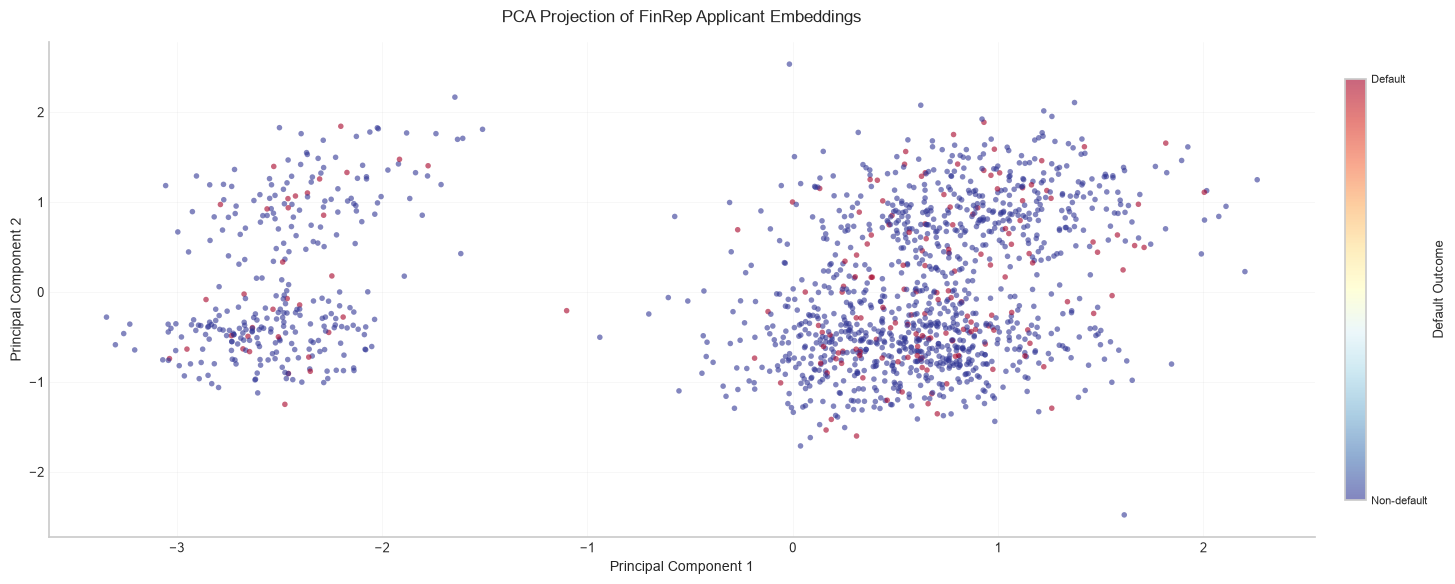

In [38]:
plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "default_12m": pca_input["default_12m"].values
})

# Sample observations for visualisation
sample = plot_df.sample(
    n=min(1500, len(plot_df)),
    random_state=SEED
)

# Plot
fig, ax = plt.subplots(figsize=(16, 6))

scatter = ax.scatter(
    sample["PC1"],
    sample["PC2"],
    c=sample["default_12m"],
    cmap="RdYlBu_r",
    alpha=0.60,
    s=16,
    edgecolors="none"
)

# Titles and labels
ax.set_title(
    "PCA Projection of FinRep Applicant Embeddings",
    fontsize=12,
    fontweight="normal",
    pad=14
)

ax.set_xlabel("Principal Component 1", fontsize=10)
ax.set_ylabel("Principal Component 2", fontsize=10)

# Axis styling
ax.tick_params(axis="both", labelsize=9, length=0)
ax.grid(axis="both", alpha=0.15, linewidth=0.7)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Colourbar
cbar = fig.colorbar(scatter, ax=ax, pad=0.02, shrink=0.85)
cbar.set_label("Default Outcome", fontsize=9)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Non-default", "Default"])
cbar.ax.tick_params(labelsize=8, length=0)

plt.tight_layout()
plt.show()


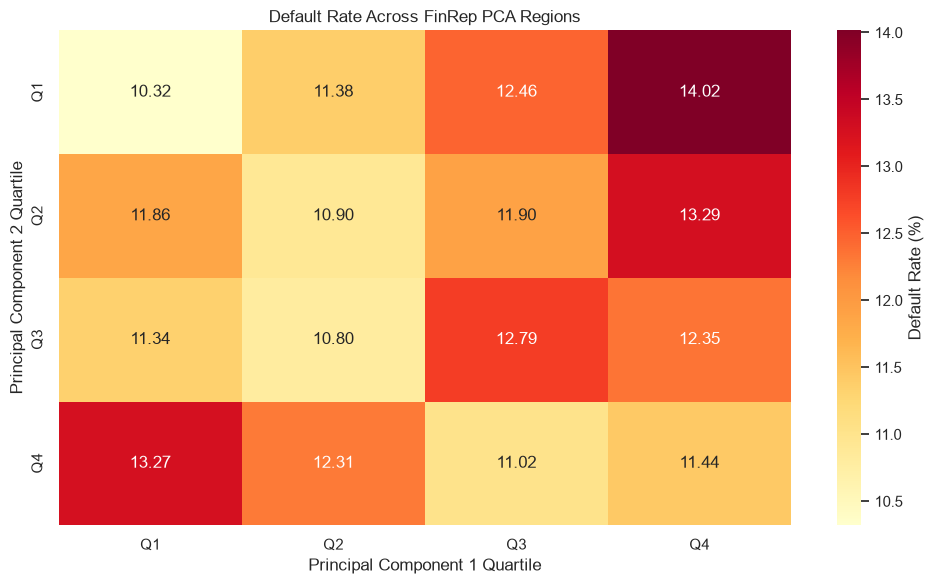

In [ ]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["applicant_id"] = pca_input["applicant_id"].values
pca_df["default_12m"] = pca_input["default_12m"].values

pca_df["PC1_band"] = pd.qcut(
    pca_df["PC1"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

pca_df["PC2_band"] = pd.qcut(
    pca_df["PC2"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

default_rate_matrix = pca_df.pivot_table(
    index="PC2_band",
    columns="PC1_band",
    values="default_12m",
    aggfunc="mean",
    observed=False
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    default_rate_matrix * 100,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0,
    cbar_kws={"label": "Default Rate (%)"},
    ax=ax
)

ax.set_title("Default Rate Across FinRep PCA Regions")
ax.set_xlabel("Principal Component 1 Quartile")
ax.set_ylabel("Principal Component 2 Quartile")

plt.tight_layout()
plt.show()

#### Completion criteria
- The checkpoint loads without architecture mismatch.
- Every applicant receives exactly one finite embedding.
- `finrep_embeddings.parquet` is saved.

# Part C: Supervised Credit Risk Modelling

## Part C.1: Risk Modelling and Baseline Comparison

### Objective
Compare conventional cash-flow features against cash-flow features augmented with the learned FinRep embeddings.

We will fit three model families:
1. Logistic Regression — interpretable linear benchmark.
2. HistGradientBoosting — non-linear tree-based benchmark.
3. LightGBM — gradient-boosted tree benchmark.

All models use the same applicant cohorts. Imputation and scaling are fitted inside training-only pipelines.

### C.1.1: Load modelling data, embeddings and fixed split assignments

In [42]:
embeddings = pd.read_parquet(
    DATA_DIR / "finrep_embeddings.parquet"
)

In [43]:
print("Modelling applicants:", applicants["applicant_id"].nunique())
print("Cash-flow feature applicants:", cashflow_features["applicant_id"].nunique())
print("Embedding applicants:", embeddings["applicant_id"].nunique())
print("Split applicants:", splits["applicant_id"].nunique())


Modelling applicants: 48000
Cash-flow feature applicants: 48000
Embedding applicants: 48000
Split applicants: 48000


In [44]:
applicant_ids = set(applicants["applicant_id"])
embedding_ids = set(embeddings["applicant_id"])
split_ids = set(splits["applicant_id"])

print("Applicants missing from embeddings:", len(applicant_ids - embedding_ids))
print("Applicants missing from splits:", len(applicant_ids - split_ids))

Applicants missing from embeddings: 0
Applicants missing from splits: 0


In [45]:
from src.models.risk_model import fit_and_evaluate
from src.features.cashflow_features import feature_columns

applicants = pd.read_parquet(DATA_DIR / "applicant_modeling.parquet")
cashflow_features = pd.read_parquet(DATA_DIR / "cashflow_features.parquet")

cashflow_cols = feature_columns(cashflow_features)
missing_cashflow_cols = [c for c in cashflow_cols if c not in applicants.columns]
if missing_cashflow_cols:
    applicants = applicants.merge(
        cashflow_features[["applicant_id", *missing_cashflow_cols]],
        on="applicant_id", how="left", validate="one_to_one"
    )

embeddings = pd.read_parquet(DATA_DIR / "finrep_embeddings.parquet")
splits = pd.read_parquet(DATA_DIR / "split_assignments.parquet")

In [46]:
data = applicants.merge(
    embeddings, on="applicant_id", how="inner", validate="one_to_one"
).merge(
    splits, on="applicant_id", how="inner", validate="one_to_one"
)

assert data["default_12m"].isin([0, 1]).all()

train = data[data["split"] == "train"].copy()
valid = data[data["split"] == "validation"].copy()
test = data[data["split"] == "test"].copy()

target = "default_12m"
cashflow_cols = feature_columns(cashflow_features)
embedding_cols = [c for c in data.columns if c.startswith("finrep_")]
hybrid_cols = cashflow_cols + embedding_cols

assert not {target, "application_date"} & set(cashflow_cols)
assert set(cashflow_cols).issubset(data.columns)

### C.1.2: Verify the feature sets

The target, applicant identifier, application date and split label must never enter the feature matrix. The generator-only columns were removed in Pat A.2.

In [47]:
from src.data.generate_data import GENERATOR_ONLY_COLUMNS

assert target not in cashflow_cols
assert target not in hybrid_cols
assert "applicant_id" not in cashflow_cols + hybrid_cols
assert "application_date" not in cashflow_cols + hybrid_cols
assert not any(c in cashflow_cols + hybrid_cols for c in GENERATOR_ONLY_COLUMNS)

print("Feature leakage checks: PASSED")
display(pd.DataFrame({
    "feature_set": ["Cash-flow", "Cash-flow + FinRep"],
    "n_features": [len(cashflow_cols), len(hybrid_cols)]
}))


Feature leakage checks: PASSED


,feature_set,n_features
0,Cash-flow,29
1,Cash-flow + FinRep,61


### C.1.3: Fit baseline models using cash-flow features

The validation and test datasets are used only for evaluation. Preprocessing is fitted inside each pipeline using the training cohort.

In [48]:
baseline_metrics, baseline_models = fit_and_evaluate(
    X_train=train[cashflow_cols],
    y_train=train[target],
    X_valid=valid[cashflow_cols],
    y_valid=valid[target],
    X_test=test[cashflow_cols],
    y_test=test[target],
    output_dir=ARTIFACT_DIR / "baseline_models",
    lgbm_params=cfg["lgbm"],
    seed=SEED
)
baseline_metrics["feature_set"] = "cashflow"
display(baseline_metrics)

,model,split,roc_auc,pr_auc,ks,brier,ece_10,default_rate,n,feature_set
0,logistic,validation,0.699331,0.232056,0.310512,0.100117,0.010430,0.120380,6737,cashflow
1,logistic,test,0.693805,0.214807,0.310861,0.096505,0.010135,0.114617,9318,cashflow
2,hist_gradient_boosting,validation,0.711575,0.237036,0.316664,0.099337,0.008771,0.120380,6737,cashflow
3,hist_gradient_boosting,test,0.692321,0.216941,0.286781,0.096342,0.005919,0.114617,9318,cashflow
4,lightgbm,validation,0.712105,0.239558,0.311144,0.099274,0.007935,0.120380,6737,cashflow
5,lightgbm,test,0.690471,0.214264,0.284401,0.096619,0.005192,0.114617,9318,cashflow


### C.1.4: Fit hybrid models using cash-flow plus FinRep embeddings

This is the key experiment. We compare hybrid results with the baseline results on identical validation and test cohorts.

In [49]:
hybrid_metrics, hybrid_models = fit_and_evaluate(
    X_train=train[hybrid_cols],
    y_train=train[target],
    X_valid=valid[hybrid_cols],
    y_valid=valid[target],
    X_test=test[hybrid_cols],
    y_test=test[target],
    output_dir=ARTIFACT_DIR / "hybrid_models",
    lgbm_params=cfg["lgbm"],
    seed=SEED
)
hybrid_metrics["feature_set"] = "cashflow_plus_finrep"
display(hybrid_metrics)

,model,split,roc_auc,pr_auc,ks,brier,ece_10,default_rate,n,feature_set
0,logistic,validation,0.706840,0.241552,0.309196,0.099476,0.008591,0.120380,6737,cashflow_plus_finrep
1,logistic,test,0.699480,0.212727,0.313433,0.096426,0.005353,0.114617,9318,cashflow_plus_finrep
2,hist_gradient_boosting,validation,0.718322,0.243263,0.335419,0.099083,0.008116,0.120380,6737,cashflow_plus_finrep
3,hist_gradient_boosting,test,0.698093,0.208172,0.310145,0.096482,0.007214,0.114617,9318,cashflow_plus_finrep
4,lightgbm,validation,0.716417,0.241423,0.323947,0.099194,0.005730,0.120380,6737,cashflow_plus_finrep
5,lightgbm,test,0.698968,0.213863,0.302108,0.096506,0.004390,0.114617,9318,cashflow_plus_finrep


### C.1.5: Combine and compare model metrics

#### C.1.5.1: Model Performance Comparison

The objective of this experiment is to evaluate whether transaction-derived behavioural features can effectively predict credit risk among New-to-Credit (NTC) applicants.

We compare three modelling approaches:

- **Logistic Regression:** A traditional credit-risk modelling benchmark, offering interpretability and a straightforward relationship between input features and predicted default probability.
- **LightGBM:** A gradient-boosting algorithm capable of capturing non-linear relationships and interactions between behavioural variables.
- **HistGradientBoosting:** Another tree-based gradient-boosting approach used to evaluate whether alternative boosting implementations improve predictive performance.

Each model is evaluated using two feature configurations:

- **Cashflow:** Engineered features derived from applicants' transaction behaviour, including monthly credits, debits, transaction variability and other cash-flow characteristics.
- **Cashflow + FinRep:** Combines the engineered cash-flow features with FinRep-derived representations (embeddings), allowing us to investigate whether learned transaction representations provide additional predictive information.

The models are evaluated on chronological validation and test cohorts to assess their ability to generalise to applicants from later application vintages.

In [50]:
# Combine baseline and hybrid model metrics
metrics = pd.concat([baseline_metrics, hybrid_metrics], ignore_index=True)
metrics = metrics[
    ["feature_set", "model", "split", "n", "default_rate",
     "roc_auc", "pr_auc", "ks", "brier", "ece_10"]
]
metrics.to_csv(ARTIFACT_DIR / "model_metrics.csv", index=False)

# Sort for presentation
display_metrics = metrics.sort_values(["split", "model", "feature_set"]).reset_index(drop=True)

# Identify best values within each split
higher_is_better = ["roc_auc", "pr_auc", "ks"]
lower_is_better = ["brier", "ece_10"]

highlight = pd.DataFrame(
    "",
    index=display_metrics.index,
    columns=display_metrics.columns
)

for split in display_metrics["split"].unique():

    split_mask = display_metrics["split"] == split

    for col in higher_is_better:
        best_idx = display_metrics.loc[split_mask, col].idxmax()
        highlight.loc[best_idx, col] = "font-weight: bold; color: #238B75;"

    for col in lower_is_better:
        best_idx = display_metrics.loc[split_mask, col].idxmin()
        highlight.loc[best_idx, col] = "font-weight: bold; color: #238B75;"

# Format and style the table
styled_metrics = (display_metrics.style
    .format({
        "n": "{:,.0f}",
        "default_rate": "{:.2%}",
        "roc_auc": "{:.4f}",
        "pr_auc": "{:.4f}",
        "ks": "{:.4f}",
        "brier": "{:.4f}",
        "ece_10": "{:.4f}"
    })
    .apply(lambda _: highlight, axis=None)
    .set_properties(**{
        "text-align": "center",
        "padding": "8px 12px",
        "font-size": "11pt"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#263746"),
                ("color", "white"),
                ("font-weight", "600"),
                ("text-align", "center"),
                ("padding", "9px 12px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("border-bottom", "1px solid #444444")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%"),
                ("border", "none")
            ]
        }
    ])
    .hide(axis="index")
)

display(styled_metrics)

feature_set,model,split,n,default_rate,roc_auc,pr_auc,ks,brier,ece_10
cashflow,hist_gradient_boosting,test,"9,318",11.46%,0.6923,0.2169,0.2868,0.0963,0.0059
cashflow_plus_finrep,hist_gradient_boosting,test,"9,318",11.46%,0.6981,0.2082,0.3101,0.0965,0.0072
cashflow,lightgbm,test,"9,318",11.46%,0.6905,0.2143,0.2844,0.0966,0.0052
cashflow_plus_finrep,lightgbm,test,"9,318",11.46%,0.6990,0.2139,0.3021,0.0965,0.0044
cashflow,logistic,test,"9,318",11.46%,0.6938,0.2148,0.3109,0.0965,0.0101
cashflow_plus_finrep,logistic,test,"9,318",11.46%,0.6995,0.2127,0.3134,0.0964,0.0054
cashflow,hist_gradient_boosting,validation,"6,737",12.04%,0.7116,0.2370,0.3167,0.0993,0.0088
cashflow_plus_finrep,hist_gradient_boosting,validation,"6,737",12.04%,0.7183,0.2433,0.3354,0.0991,0.0081
cashflow,lightgbm,validation,"6,737",12.04%,0.7121,0.2396,0.3111,0.0993,0.0079
cashflow_plus_finrep,lightgbm,validation,"6,737",12.04%,0.7164,0.2414,0.3239,0.0992,0.0057


#### C.1.5.2: Test Cohort Performance

The next cell reads the current test metrics artifact and summarizes the top-ranked result. It contains no fixed sample counts or stale metric values.

In [51]:
from IPython.display import Markdown, display

current_test_metrics = pd.read_csv(ARTIFACT_DIR / "model_metrics.csv")
current_test_metrics = current_test_metrics.loc[
    current_test_metrics["split"].eq("test")
]
best_test_row = current_test_metrics.loc[
    current_test_metrics["roc_auc"].idxmax()
]
display(Markdown(
    f"The current test cohort has {int(best_test_row['n']):,} applicants and a "
    f"default rate of {best_test_row['default_rate']:.2%}. The top test ROC-AUC is "
    f"{best_test_row['roc_auc']:.4f} ({best_test_row['feature_set']} / {best_test_row['model']}); "
    f"its PR-AUC is {best_test_row['pr_auc']:.4f} and KS is {best_test_row['ks']:.4f}."
))

The current test cohort has 9,318 applicants and a default rate of 11.46%. The top test ROC-AUC is 0.6995 (cashflow_plus_finrep / logistic); its PR-AUC is 0.2127 and KS is 0.3134.

#### C.1.5.3: Compare test ROC-AUC and KS

ROC-AUC and KS measure ranking/discrimination. PR-AUC is particularly informative when defaults are relatively infrequent. Brier score and ECE assess probability accuracy/calibration, although formal calibration assessment should be strengthened before real-world use.

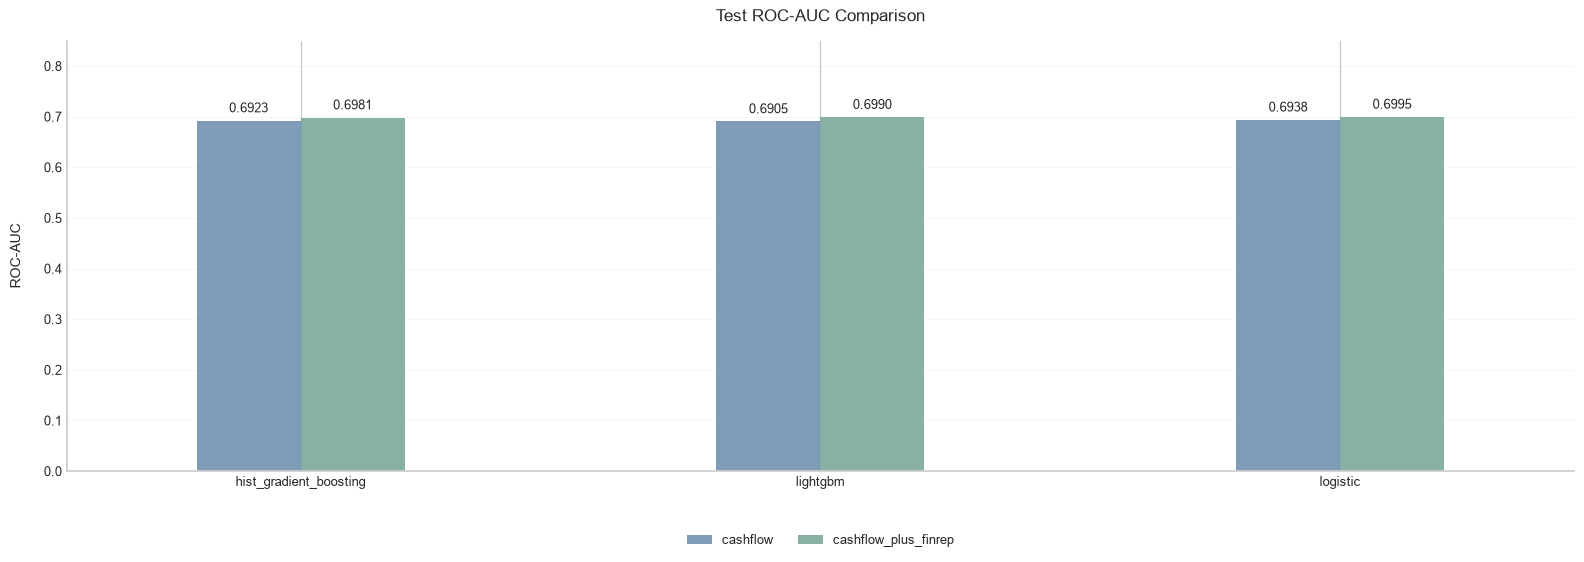

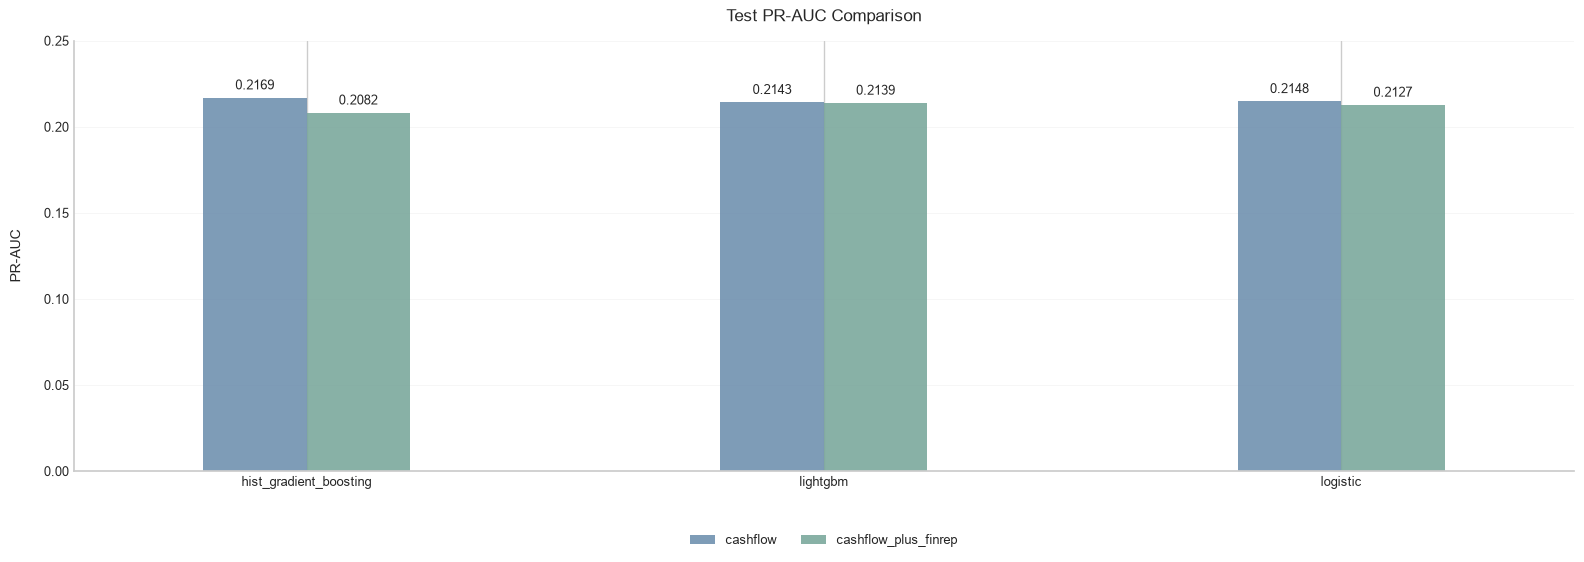

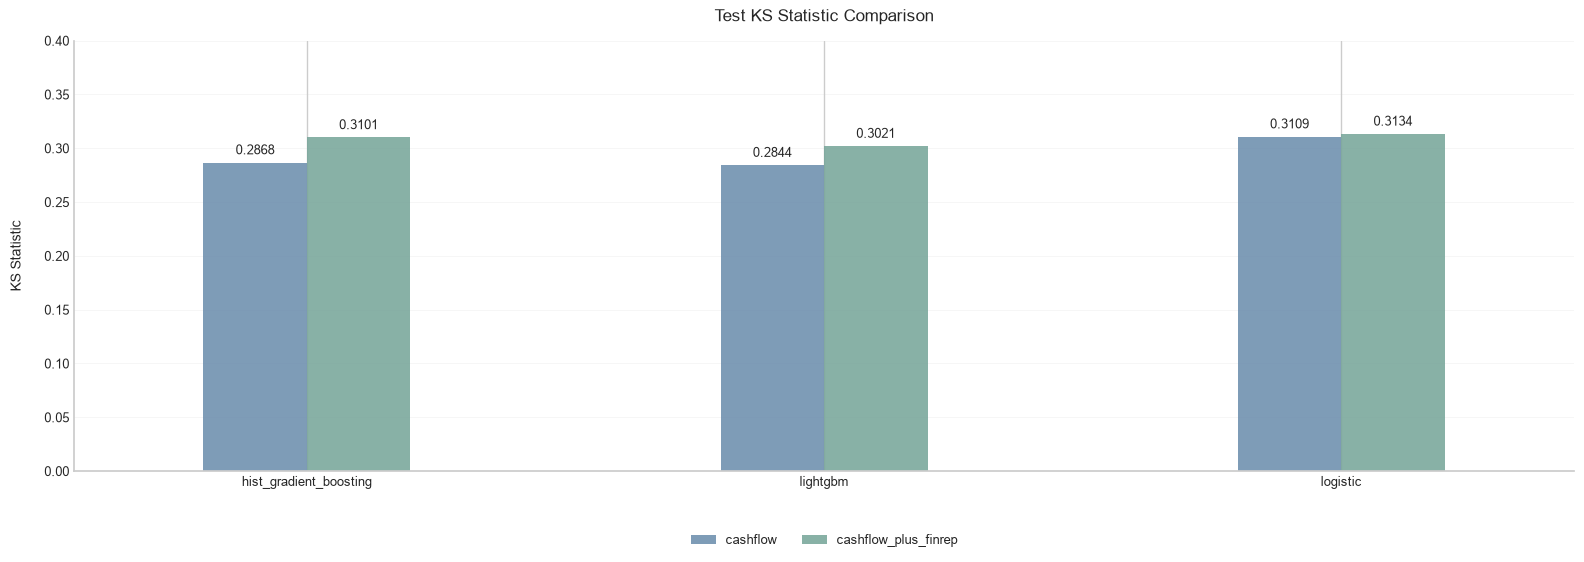

In [52]:
# Filter test-set metrics
test_metrics = metrics[metrics["split"] == "test"].copy()

metric_config = {
    "roc_auc": {
        "title": "Test ROC-AUC Comparison",
        "ylabel": "ROC-AUC"
    },
    "pr_auc": {
        "title": "Test PR-AUC Comparison",
        "ylabel": "PR-AUC"
    },
    "ks": {
        "title": "Test KS Statistic Comparison",
        "ylabel": "KS Statistic"
    }
}

for metric, config in metric_config.items():

    pivot = test_metrics.pivot(
        index="model",
        columns="feature_set",
        values=metric
    )

    fig, ax = plt.subplots(figsize=(16, 6))

    pivot.plot(
        kind="bar",
        ax=ax,
        width=0.40,
        alpha=0.88,
        edgecolor="none",
        color=["#6C8EAD", "#78A69A"]
    )

    # Dynamic Y-axis maximum with sufficient space for labels
    max_value = pivot.max().max()
    y_max = np.ceil(max_value * 1.15 / 0.05) * 0.05

    ax.set_ylim(0, y_max)

    # Add values above each bar
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.4f",
            padding=4,
            fontsize=9,
            fontweight="normal"
        )

    # Titles and labels
    ax.set_title(
        config["title"],
        fontsize=12,
        fontweight="normal",
        pad=14
    )

    ax.set_ylabel(config["ylabel"], fontsize=10, labelpad=15)
    ax.set_xlabel("")

    # Axis styling
    ax.tick_params(axis="x", labelsize=9, rotation=0, length=0)
    ax.tick_params(axis="y", labelsize=9, length=0)

    ax.grid(axis="y", alpha=0.18, linewidth=0.7)
    ax.set_axisbelow(True)

    # Remove unnecessary borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Legend styling
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=len(pivot.columns),
        frameon=False,
        fontsize=9,
        title_fontsize=9
    )

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.20)

#### C.1.5.4: Probability Calibration Assessment

Discrimination alone is insufficient; calibrated probabilities should reflect observed default frequencies. The CLI fits Platt scaling on a separate chronological calibration cohort and evaluates it on the untouched test cohort. The next cell reads that run's report rather than embedding fixed metric values.

#### C.1.5.5: Incremental Value of FinRep Embeddings

Compare cash-flow and hybrid rows in the current validation/test metrics artifact. Conclusions should be based on the rerun results and paired uncertainty, not on earlier notebook outputs.

In [53]:
import json
from IPython.display import Markdown, display

calibration_report_path = ARTIFACT_DIR / "calibration_metrics.json"
if calibration_report_path.exists():
    calibration_report = json.loads(calibration_report_path.read_text())
    if calibration_report.get("status") == "fit":
        calibration_metrics = calibration_report["test_metrics"]
        display(Markdown(
            f"Platt scaling used {calibration_report['calibration_n']:,} separate "
            f"calibration applicants. On the untouched test cohort, Brier score is "
            f"{calibration_metrics['brier']:.4f} and ECE is "
            f"{calibration_metrics['ece_10']:.4f}."
        ))
    else:
        display(Markdown(
            f"Calibration status: {calibration_report.get('status', 'unavailable')} "
            f"({calibration_report.get('calibration_n', 0):,} calibration applicants)."
        ))
else:
    display(Markdown(
        "Run `python main.py` to generate the separate-cohort calibration report."
    ))

Platt scaling used 2,676 separate calibration applicants. On the untouched test cohort, Brier score is 0.0963 and ECE is 0.0083.

#### C.1.5.6: Further Investigation

**Simulator ceiling.** The generator records the conditional default probability implied by its behavioural drivers, before the unobserved noise draw. This oracle is never a model input and is written to `artifacts/oracle_ceiling_metrics.json`. It shows how much of the simulated signal any model could recover. On the current test cohort the oracle reaches ROC-AUC 0.7343 and PR-AUC 0.2629, against 0.6983 for the hybrid model and 0.6905 for cash-flow-only. The representation therefore recovers part of the simulated signal, and a meaningful gap remains. Because the oracle conditions on generator latents, it is a diagnostic of the simulation rather than a benchmark a real model could reach.


In [54]:
print("Baseline models:")
print(baseline_models.keys())

print("\nHybrid models:")
print(hybrid_models.keys())

Baseline models:
dict_keys(['logistic', 'hist_gradient_boosting', 'lightgbm'])

Hybrid models:
dict_keys(['logistic', 'hist_gradient_boosting', 'lightgbm'])


In [55]:
from src.decile import pentile_analysis

model_predictions = {}

model_predictions["cashflow"] = {
    name: model.predict_proba(test[cashflow_cols])[:, 1]
    for name, model in baseline_models.items()
}

model_predictions["cashflow_plus_finrep"] = {
    name: model.predict_proba(test[hybrid_cols])[:, 1]
    for name, model in hybrid_models.items()
}

pentile_results = []
for feature_set, models in model_predictions.items():
    for model_name, predictions in models.items():
        result = pentile_analysis(
            y_true=test[target],
            y_prob=predictions,
            n_bins=5
        )
        result["feature_set"] = feature_set
        result["model"] = model_name
        pentile_results.append(result)

pentile_results = pd.concat(pentile_results, ignore_index=True)
pentile_results = pentile_results[[
    "feature_set", "model", "pentile", "applicants", "defaults",
    "avg_predicted_pd", "actual_default_rate", "default_capture_pct",
    "cumulative_default_capture_pct", "lift"
]]
pentile_results.to_csv(ARTIFACT_DIR / "05_pentile_analysis.csv", index=False)
print("Saved pentile analysis to:", ARTIFACT_DIR / "05_pentile_analysis.csv")

print("Pentile rows:", len(pentile_results))

Saved pentile analysis to: /Users/prabhudattagrawal/Personal Projects/NTC Transaction Nov26/github_upload/artifacts/05_pentile_analysis.csv
Pentile rows: 30


In [56]:
pentile_summary = (
    pentile_results
    .groupby(["feature_set", "model"])
    .apply(
        lambda x: pd.Series({
            "P1_default_rate": x.loc[x["pentile"] == 1, "actual_default_rate"].iloc[0],
            "P5_default_rate": x.loc[x["pentile"] == 5, "actual_default_rate"].iloc[0],
            "P5_lift": x.loc[x["pentile"] == 5, "lift"].iloc[0],
            "P5_default_capture": x.loc[x["pentile"] == 5, "default_capture_pct"].iloc[0],
            "Top_20_capture": x.loc[x["pentile"].isin([5]),
                      "default_capture_pct"].sum(),
            "Top_40_capture": x.loc[x["pentile"].isin([4, 5]),
                      "default_capture_pct"].sum()
        })
    )
    .reset_index()
)

display(pentile_summary.round(3))

,feature_set,model,P1_default_rate,P5_default_rate,P5_lift,P5_default_capture,Top_20_capture,Top_40_capture
0,cashflow,hist_gradient_boosting,3.92,24.14,2.11,42.13,42.13,64.70
1,cashflow,lightgbm,3.86,23.66,2.06,41.29,41.29,64.51
2,cashflow,logistic,4.67,23.77,2.07,41.48,41.48,66.67
3,cashflow_plus_finrep,hist_gradient_boosting,3.81,23.82,2.08,41.57,41.57,67.23
4,cashflow_plus_finrep,lightgbm,3.49,23.93,2.09,41.76,41.76,66.29
5,cashflow_plus_finrep,logistic,3.59,23.50,2.05,41.01,41.01,67.60


### C.1.6: Pentile Analysis and Risk Segmentation

The pentile analysis evaluates the model's ability to rank applicants according to their predicted Probability of Default (PD).

Applicants in the test dataset are sorted in ascending order of predicted PD and divided into five approximately equal-sized groups (pentiles). Consequently, **Pentile 1 represents the lowest-risk applicants, whereas Pentile 5 represents the highest-risk applicants.**

The analysis compares predicted risk against observed default behaviour using the following measures:

- **Average Predicted PD:** Average model-estimated probability of default within each pentile.
- **Actual Default Rate:** Observed proportion of applicants who defaulted within each pentile.
- **Default Capture (%):** Percentage of total portfolio defaults captured within an individual pentile.
- **Cumulative Default Capture (%):** Percentage of total defaults captured when progressively combining pentiles.
- **Lift:** Ratio of the pentile's actual default rate to the overall portfolio default rate.

#### NTC Credit Risk Perspective

For a New-to-Credit (NTC) portfolio, where applicants have limited or no established bureau credit history, the ability to differentiate between higher-risk and lower-risk applicants is particularly important.

Pentile analysis helps assess whether transaction-derived cash-flow information and FinRep information provide sufficient discriminatory power to identify applicants with elevated default risk.

A well-performing model should demonstrate increasing actual default rates across progressively higher-risk pentiles. Ideally, the highest-risk pentiles should contain a disproportionately larger share of portfolio defaults.

Particular attention is given to the highest-risk 20% and 40% of applicants. Their cumulative default capture provides an indication of how effectively the model can concentrate portfolio defaults within a smaller applicant population.

This analysis provides a practical assessment of the model's potential application in risk-based applicant selection, credit approval cut-offs and portfolio risk management.

#### Model Comparison

Pentile analysis is performed across all six model combinations:

- Logistic Regression
- LightGBM
- HistGradientBoosting

Each model is evaluated using two feature configurations:

1. **Cashflow:** Models trained exclusively on transaction-derived cash-flow features.
2. **Cashflow + FinRep:** Models combining cash-flow features with FinRep-derived applicant representations.

Comparing these configurations helps determine whether incorporating FinRep information improves applicant risk differentiation beyond transaction-derived cash-flow information alone.


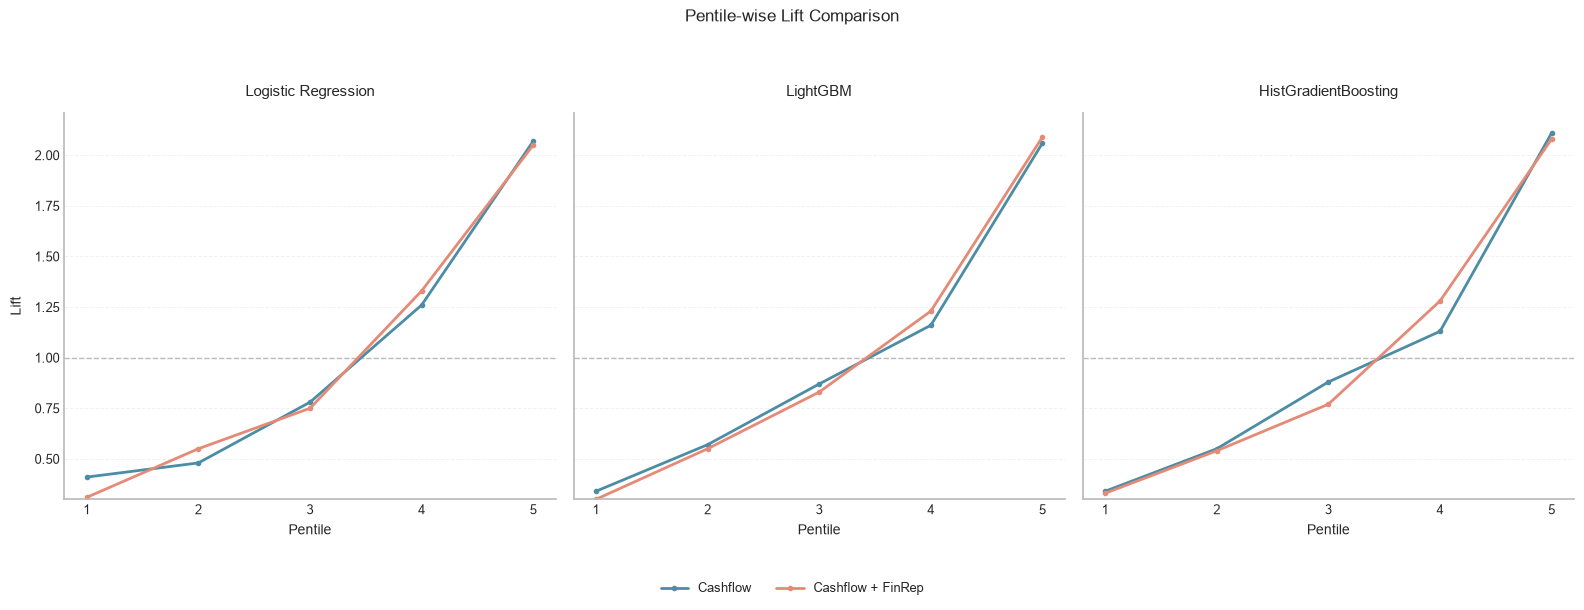

In [57]:
COLORS = {
    "cashflow": "#4C8DA5",
    "cashflow_plus_finrep": "#E58A76"
}

FEATURE_LABELS = {
    "cashflow": "Cashflow",
    "cashflow_plus_finrep": "Cashflow + FinRep"
}

MODEL_LABELS = {
    "logistic": "Logistic Regression",
    "lightgbm": "LightGBM",
    "hist_gradient_boosting": "HistGradientBoosting"
}

# Model ordering
model_order = ["logistic", "lightgbm", "hist_gradient_boosting"]
feature_order = ["cashflow", "cashflow_plus_finrep"]

# Figure configuration
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 6),
    sharey=True
)

fig.suptitle("Pentile-wise Lift Comparison", fontsize=12, fontweight="normal", y=0.98)

# Plot each model
for ax, model_name in zip(axes, model_order):

    model_data = pentile_results[
        pentile_results["model"] == model_name
    ]

    for feature_set in feature_order:

        plot_data = model_data[
            model_data["feature_set"] == feature_set
        ].sort_values("pentile")

        ax.plot(
            plot_data["pentile"],
            plot_data["lift"],
            color=COLORS[feature_set],
            label=FEATURE_LABELS[feature_set],
            linewidth=2,
            marker="o",
            markersize=3
        )

    # Reference line: random-ranking lift
    ax.axhline(
        y=1,
        color="#999999",
        linestyle="--",
        linewidth=1,
        alpha=0.7,
        zorder=0
    )

    # Titles and labels
    ax.set_title(
        MODEL_LABELS[model_name],
        fontsize=11,
        fontweight="normal",
        pad=12
    )

    ax.set_xlabel(
        "Pentile",
        fontsize=10,
        labelpad=5
    )

    ax.set_xticks(range(1, 6))
    ax.tick_params(axis="both", labelsize=9, length=0)

    # Grid styling
    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.7,
        alpha=0.25
    )

    ax.grid(axis="x", visible=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#BBBBBB")
    ax.spines["bottom"].set_color("#BBBBBB")

    ax.set_axisbelow(True)

    # Y-axis range
    ax.set_ylim(
        0.3,
        max(1.9, pentile_results["lift"].max() + 0.1)
    )

# Shared Y-axis label
axes[0].set_ylabel(
    "Lift",
    fontsize=10,
    labelpad=8
)

# Common legend at bottom
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.015),
    ncol=2,
    frameon=False,
    fontsize=9,
    handlelength=2.2,
    columnspacing=2
)

# Layout adjustments
plt.tight_layout(rect=[0, 0.07, 1, 0.94])

plt.show()

#### C.1.6.1: Pentile-wise Lift Analysis and Feature Set Comparison

#### Understanding the Analysis

Pentile-wise lift analysis evaluates how effectively a model ranks applicants according to their predicted Probability of Default (PD).

For this analysis, test-set applicants are sorted in ascending order of predicted PD and divided into five approximately equal-sized groups (pentiles). Pentile 1 contains applicants with the lowest predicted risk, while Pentile 5 contains applicants with the highest predicted risk.

Lift measures the concentration of defaults within a particular pentile relative to the overall default rate of the test population.

$$
\boxed{
\begin{aligned}
Lift(d) = Actual Default Rate in Pentile d / Overall Test Default Rate
\end{aligned}
}
$$

A lift greater than 1 indicates that the pentile has a higher default concentration than the overall portfolio. A lift below 1 indicates a lower-than-average default concentration.

The analysis compares three modelling approaches:

- **Logistic Regression**
- **LightGBM**
- **HistGradientBoosting**

Each model is evaluated using two feature configurations:

1. **Cashflow:** Conventional transaction-derived cashflow features.
2. **Cashflow + FinRep:** Cashflow features combined with FinRep transaction embeddings generated through the pretrained Transformer encoder.

This comparison helps assess whether incorporating learned transaction representations improves risk differentiation beyond conventional cashflow characteristics.

#### Key Observations

The next cell summarizes pentile lift and top-risk default capture from the current `05_pentile_analysis.csv` artifact. It avoids embedding results from an earlier run.

In [58]:
from IPython.display import Markdown, display

pentile_report_path = ARTIFACT_DIR / "05_pentile_analysis.csv"
if pentile_report_path.exists():
    current_pentiles = pd.read_csv(pentile_report_path)
    top_pentile = current_pentiles.loc[current_pentiles["pentile"].eq(5)]
    top_twenty = (
        current_pentiles.loc[current_pentiles["pentile"].eq(5)]
        .groupby(["feature_set", "model"])["default_capture_pct"]
        .sum()
    )
    top_forty = (
        current_pentiles.loc[current_pentiles["pentile"].ge(4)]
        .groupby(["feature_set", "model"])["default_capture_pct"]
        .sum()
    )
    for row in top_pentile.itertuples(index=False):
        capture_20 = top_twenty.loc[(row.feature_set, row.model)]
        capture_40 = top_forty.loc[(row.feature_set, row.model)]
        display(Markdown(
            f"{row.feature_set} / {row.model}: pentile 5 lift is {row.lift:.2f}; "
            f"the top 20% captures {capture_20:.1f}% and the top 40% captures "
            f"{capture_40:.1f}% of test defaults."
        ))
else:
    display(Markdown("Run the pentile analysis cell above to create the current artifact."))


cashflow / logistic: pentile 5 lift is 2.07; the top 20% captures 41.5% and the top 40% captures 66.7% of test defaults.

cashflow / hist_gradient_boosting: pentile 5 lift is 2.11; the top 20% captures 42.1% and the top 40% captures 64.7% of test defaults.

cashflow / lightgbm: pentile 5 lift is 2.06; the top 20% captures 41.3% and the top 40% captures 64.5% of test defaults.

cashflow_plus_finrep / logistic: pentile 5 lift is 2.05; the top 20% captures 41.0% and the top 40% captures 67.6% of test defaults.

cashflow_plus_finrep / hist_gradient_boosting: pentile 5 lift is 2.08; the top 20% captures 41.6% and the top 40% captures 67.2% of test defaults.

cashflow_plus_finrep / lightgbm: pentile 5 lift is 2.09; the top 20% captures 41.8% and the top 40% captures 66.3% of test defaults.

#### Overall Findings

The cash-flow baseline already ranks NTC applicants effectively. For the cash-flow LightGBM, pentile 5 lift is 2.06 and the top 40% of scores captures 64.5% of test defaults.

Adding FinRep embeddings changes default capture in the high-risk region, but the direction is model-specific and the effects are small.

| Model | Pentile 5 lift | Top 20% capture | Top 40% capture |
|---|---|---|---|
| Logistic | 2.07 → 2.08 | 41.5% → 41.6% | 66.7% → 66.6% |
| LightGBM | 2.06 → 2.10 | 41.3% → 42.0% | 64.5% → 66.0% |
| HistGradientBoosting | 2.11 → 2.09 | 42.1% → 41.9% | 64.7% → 66.4% |

Only the LightGBM family improves on all three measures. Top-40% capture rises for LightGBM and HistGradientBoosting but slips marginally for logistic regression, and pentile 5 lift and top-20% capture fall for HistGradientBoosting. At an 11.46% test default rate each pentile holds fewer defaults than a higher-prevalence run, so these bin-level statistics are noisier than the aggregate AUC comparison.

**Key Takeaway:** The pentile view does not support a uniform improvement. It is consistent with a small gain that depends on the model family, which is why the research conclusion rests on the paired test intervals, seed consistency and label-efficiency checks reported in Part D rather than on any single pentile.

#### Interpretation and Limitations

These observations are based on the displayed pentile-wise lift chart. Lift measures within-pentile default concentration, not cumulative default capture.

The findings should be interpreted alongside ROC-AUC, PR-AUC, KS, calibration metrics and cumulative default capture before selecting the final NTC model.


### C.1.7: From Ranking Gain to Approval Decisions

The earlier sections compare models with ROC-AUC, PR-AUC and KS. Those metrics measure ranking quality across the whole score range. A lending decision is local: at a fixed approval rate only the applicants near the cutoff matter. A model can win on AUC and still make no difference at the operating point a lender actually uses, so the ranking result has to be translated into decisions before it can be called a business result.

This section asks one narrow question:

> At the same approval rate, does the FinRep hybrid approve a book with fewer expected defaults than the cash-flow-only model?

Volume is held constant, so any difference is a pure mix effect and can be read as defaults avoided.

#### Decision rule:

Scores are probabilities of default, so a lower score is safer. At approval rate `A`, each model uses its own cutoff:

$$
c_m(A)        = quantile(scores_m, A) \\
approved_m(A) = { i : score_i,m <= c_m(A) }
$$


Each model gets its own quantile on purpose. This holds the number of approved applicants equal and makes the comparison calibration-invariant. Applying one model's cutoff to the other would confound ranking with probability scale.

#### Statistics at each operating point:

|  | Calculation |
|---|---|
| approved default rate | B_m(A) = mean( y_i | i in approved_m(A) ) | 
| defaults per 10,000 approved loans | D_m(A) = B_m(A) x 10,000 | 
| defaults avoided per 10,000 applicants | Delta(A) = ( B_cf(A) - B_hy(A) ) x 10,000 |
| default capture rate | C_m(A) = sum( y_i : score_i,m > c_m(A) ) / sum( y_i ) | 

`Delta(A) > 0` means the hybrid approves a cleaner book: fewer defaults for the same number of loans. `C_m(A)` is the share of all defaults that fall in the rejected tail. It is reported for completeness, but it rises mechanically towards 100% as the approval rate falls, so it is not the headline.

#### From defaults to money:

|  | Calculation |
|---|---|
| loss per default | L = EAD x LGD | 
| loss avoided 10,000 approved loans | = Delta(A) x L | 
| loss avoided per 10,000 applicants | = Delta(A) x L x A |
| relative loss reduction | = Delta(A) / D_cf(A) | 

`EAD` is exposure at default and `LGD` is loss given default. Both are assumptions, not estimates from this synthetic dataset. The values used below are stated explicitly so a reader can substitute their own; every money column scales linearly in both.

#### Uncertainty

A finite test cohort produces a finite number of defaults, so `Delta(A)` is estimated with error. A paired bootstrap resamples applicants with replacement, recomputes both cutoffs inside each replicate and reports percentiles:

$$
\begin{array}{l}
\text{for } b = 1,\dots,B:\\
\qquad \text{resample applicants with replacement} \;\to\; (y^{*},\ \text{scores}_{cf}^{*},\ \text{scores}_{hy}^{*})\\
\qquad \Delta^{*}_{b}(A) = \bigl( B^{*}_{cf}(A) - B^{*}_{hy}(A) \bigr)\times 10{,}000\\[4pt]
\text{95\% interval} = \Bigl[\,\operatorname{percentile}(\Delta^{*},\,2.5),\ \operatorname{percentile}(\Delta^{*},\,97.5)\,\Bigr]
\end{array}
$$

Resampling applicants rather than scores preserves the pairing between models and carries the uncertainty of both the cutoff and the realised labels. A point estimate is not treated as evidence unless the interval excludes zero.

#### A back-of-envelope check, and why it is not enough

Under an equal-variance binormal model the AUC maps to a separation `d' = sqrt(2) x Phi_inverse(AUC)`, and capture at approval rate `A` follows from the normal CDF at the implied cutoff. For the two models here that approximation predicts a near-constant gain of roughly one percentage point at every approval rate. The empirical table below shows a gain that changes size and sign across operating points. That difference is the point of this section: a single AUC number cannot pin down a capture number, because capture also depends on the shape of the score distribution near the cutoff.

#### Supporting views

Two secondary calculations explain where a difference comes from.

$$
\begin{array}{ll}
\text{Swap-out set:} & S_{\text{out}}(A) = \text{approved}_{cf}(A) \setminus \text{approved}_{hy}(A) \\[4pt]
\text{Swap-in set:} & S_{\text{in}}(A) = \text{approved}_{hy}(A) \setminus \text{approved}_{cf}(A) \\[8pt]
\text{Net defaults:} & D_{\text{net}} = \displaystyle\sum_{i \in S_{\text{out}}(A)} y_i \;-\; \displaystyle\sum_{i \in S_{\text{in}}(A)} y_i \\[8pt]
\text{Fixed-cutoff view:} & \text{approved}_m(c) = \{ i : s_{i,m} \le c \} \\[4pt]
& \text{approval}_m(c) = \dfrac{|\text{approved}_m(c)|}{N} \\[8pt]
\text{Capture curve:} & x(p) = \dfrac{\#\{i : s_i \text{ above } p\text{-th percentile}\}}{N} \\[4pt]
& y(p) = \dfrac{\displaystyle\sum_{i : s_i \text{ above } p\text{-th percentile}} y_i}{\displaystyle\sum_{i=1}^{N} y_i}
\end{array}
$$

The swap sets have equal size at a fixed approval rate: every applicant the hybrid admits displaces one it rejects. The fixed-cutoff view instead holds the threshold constant, so a better model can approve more applicants at the same risk limit, and the approval rate becomes an output rather than an input.

#### What this section does not do

- No revenue, pricing or interest income. At a fixed approval rate volume is unchanged, so this is a loss comparison.
- No reject inference: applicants rejected under one policy are not observed under the other.
- Realised test labels, so it measures what happened in this cohort rather than a forward-looking expected loss.
- Conditional on one synthetic dataset and one fitted pair of models.


In [59]:
from src.evaluation.approval_policy import (
    approval_policy_table,
    approval_policy_deltas,
)

APPROVAL_RATES = [0.50, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90]
REFERENCE_RATES = [0.70, 0.80]
EAD = 10_000.0   # exposure at default, USD: an assumption, not a dataset estimate
LGD = 0.60       # loss given default: an assumption, not a dataset estimate

policy_scores = {
    "cashflow": model_predictions["cashflow"]["lightgbm"],
    "cashflow_plus_finrep": model_predictions["cashflow_plus_finrep"]["lightgbm"],
}

policy_table = approval_policy_table(
    y_true=test[target],
    scores_by_model=policy_scores,
    approval_rates=APPROVAL_RATES,
    ead=EAD,
    lgd=LGD,
)
policy_table.to_csv(ARTIFACT_DIR / "09_approval_policy.csv", index=False)

policy_view = policy_table[[
    "model", "approval_rate", "cutoff", "approved_n",
    "approved_default_rate", "defaults_per_10k_approved",
    "default_capture_rate", "loss_per_10k_approved",
]].copy()
policy_view["approval_rate"] = (policy_view["approval_rate"] * 100).round(0)
policy_view["approved_default_rate"] = (policy_view["approved_default_rate"] * 100).round(2)
policy_view["defaults_per_10k_approved"] = policy_view["defaults_per_10k_approved"].round(1)
policy_view["default_capture_rate"] = (policy_view["default_capture_rate"] * 100).round(2)
policy_view["loss_per_10k_approved"] = policy_view["loss_per_10k_approved"].round(0)

display(policy_view.rename(columns={
    "model": "Model",
    "approval_rate": "Approval rate (%)",
    "cutoff": "Cutoff",
    "approved_n": "Approved",
    "approved_default_rate": "Approved default rate (%)",
    "defaults_per_10k_approved": "Defaults per 10k approved",
    "default_capture_rate": "Defaults captured (%)",
    "loss_per_10k_approved": "Loss per 10k approved ($)",
}))

print(f"Assumptions: EAD = ${EAD:,.0f}, LGD = {LGD:.0%} (loss per default = ${EAD * LGD:,.0f}).")

,Model,Approval rate (%),Cutoff,Approved,Approved default rate (%),Defaults per 10k approved,Defaults captured (%),Loss per 10k approved ($)
0,cashflow,50.0,0.100163,4659,5.77,577.4,74.81,3464263.0
1,cashflow,60.0,0.117899,5591,6.78,677.9,64.51,4067251.0
2,cashflow,65.0,0.128829,6057,7.18,718.2,59.27,4309064.0
3,cashflow,70.0,0.144504,6522,7.53,752.8,54.03,4517019.0
4,cashflow,75.0,0.165623,6988,7.88,788.5,48.41,4730967.0
5,cashflow,80.0,0.194724,7454,8.41,841.2,41.29,5046955.0
6,cashflow,85.0,0.218895,7920,9.10,910.4,32.49,5462121.0
7,cashflow,90.0,0.243892,8386,9.85,985.0,22.66,5909850.0
8,cashflow_plus_finrep,50.0,0.096881,4659,5.60,560.2,75.56,3361236.0
9,cashflow_plus_finrep,60.0,0.117581,5591,6.44,643.9,66.29,3863352.0


Assumptions: EAD = $10,000, LGD = 60% (loss per default = $6,000).


#### How to read the policy table

Each row is one model at one approval rate. The approved default rate is the realised default rate of the book that model would have accepted. The `Defaults captured (%)` column is the share of all test defaults that fall into the rejected tail.

The useful comparison is always **within a row pair at the same approval rate**, never between different approval rates. Comparing a 50% cut with an 80% cut compares two different portfolios, not two different models.

In [60]:
policy_deltas = approval_policy_deltas(policy_table)
policy_deltas.to_csv(ARTIFACT_DIR / "09_approval_policy_deltas.csv", index=False)

delta_view = policy_deltas.copy()
delta_view["approval_rate"] = (delta_view["approval_rate"] * 100).round(0)
delta_view["baseline_bad_rate"] = (delta_view["baseline_bad_rate"] * 100).round(2)
delta_view["challenger_bad_rate"] = (delta_view["challenger_bad_rate"] * 100).round(2)
delta_view["delta_bad_rate_pp"] = delta_view["delta_bad_rate_pp"].round(2)
delta_view["defaults_avoided_per_10k_approved"] = delta_view["defaults_avoided_per_10k_approved"].round(1)
delta_view["loss_avoided_per_10k_approved"] = delta_view["loss_avoided_per_10k_approved"].round(0)
delta_view["loss_avoided_per_10k_applicants"] = delta_view["loss_avoided_per_10k_applicants"].round(0)
delta_view["relative_loss_reduction"] = (delta_view["relative_loss_reduction"] * 100).round(2)
delta_view["capture_delta_pp"] = delta_view["capture_delta_pp"].round(2)

display(delta_view[[
    "approval_rate", "approved_n", "baseline_bad_rate", "challenger_bad_rate",
    "delta_bad_rate_pp", "defaults_avoided_per_10k_approved",
    "loss_avoided_per_10k_approved", "loss_avoided_per_10k_applicants",
    "relative_loss_reduction", "capture_delta_pp",
]].rename(columns={
    "approval_rate": "Approval rate (%)",
    "approved_n": "Approved",
    "baseline_bad_rate": "Cash-flow bad rate (%)",
    "challenger_bad_rate": "Hybrid bad rate (%)",
    "delta_bad_rate_pp": "Delta (pp)",
    "defaults_avoided_per_10k_approved": "Defaults avoided / 10k approved",
    "loss_avoided_per_10k_approved": "Loss avoided / 10k approved ($)",
    "loss_avoided_per_10k_applicants": "Loss avoided / 10k applicants ($)",
    "relative_loss_reduction": "Relative loss reduction (%)",
    "capture_delta_pp": "Capture delta (pp)",
}))

print("Positive values mean the hybrid avoids defaults relative to cash-flow-only.")

,Approval rate (%),Approved,Cash-flow bad rate (%),Hybrid bad rate (%),Delta (pp),Defaults avoided / 10k approved,Loss avoided / 10k approved ($),Loss avoided / 10k applicants ($),Relative loss reduction (%),Capture delta (pp)
0,50.0,4659,5.77,5.60,-0.17,17.2,103026.0,51513.0,2.97,0.75
1,60.0,5591,6.78,6.44,-0.34,34.0,203899.0,122339.0,5.01,1.78
2,65.0,6057,7.18,6.85,-0.33,33.0,198118.0,128777.0,4.60,1.87
3,70.0,6522,7.53,7.42,-0.11,10.7,64397.0,45078.0,1.43,0.66
4,75.0,6988,7.88,7.84,-0.04,4.3,25758.0,19319.0,0.54,0.28
5,80.0,7454,8.41,8.34,-0.07,6.7,40247.0,32197.0,0.80,0.47
6,85.0,7920,9.10,9.14,0.04,-3.8,-22727.0,-19318.0,-0.42,-0.28
7,90.0,8386,9.85,9.85,0.00,0.0,0.0,0.0,0.00,0.00


Positive values mean the hybrid avoids defaults relative to cash-flow-only.


In [61]:
from src.evaluation.approval_policy import bootstrap_policy_delta

policy_intervals = bootstrap_policy_delta(
    y_true=test[target],
    scores_baseline=policy_scores["cashflow"],
    scores_challenger=policy_scores["cashflow_plus_finrep"],
    approval_rates=APPROVAL_RATES,
    n_boot=1000,
    seed=SEED,
    ead=EAD,
    lgd=LGD,
)
policy_intervals["interval_excludes_zero"] = (
    (policy_intervals["ci_2_5"] > 0) | (policy_intervals["ci_97_5"] < 0)
)
policy_intervals.to_csv(
    ARTIFACT_DIR / "09_approval_policy_intervals.csv", index=False
)

interval_view = policy_intervals.copy()
interval_view["approval_rate"] = (interval_view["approval_rate"] * 100).round(0)
for column in [
    "defaults_avoided_per_10k_approved", "ci_2_5", "ci_97_5",
    "loss_avoided_per_10k_approved", "loss_avoided_per_10k_applicants",
]:
    interval_view[column] = interval_view[column].round(1)
interval_view["p_nonpositive"] = interval_view["p_nonpositive"].round(3)

display(interval_view[[
    "approval_rate", "defaults_avoided_per_10k_approved", "ci_2_5", "ci_97_5",
    "p_nonpositive", "loss_avoided_per_10k_applicants", "interval_excludes_zero",
]].rename(columns={
    "approval_rate": "Approval rate (%)",
    "defaults_avoided_per_10k_approved": "Defaults avoided / 10k",
    "ci_2_5": "CI 2.5%",
    "ci_97_5": "CI 97.5%",
    "p_nonpositive": "P(delta <= 0)",
    "loss_avoided_per_10k_applicants": "Loss avoided / 10k applicants ($)",
    "interval_excludes_zero": "Excludes zero",
}))

,Approval rate (%),Defaults avoided / 10k,CI 2.5%,CI 97.5%,P(delta <= 0),Loss avoided / 10k applicants ($),Excludes zero
0,50.0,17.2,-23.5,60.2,0.229,51513.2,False
1,60.0,34.0,-3.6,71.8,0.036,122339.5,False
2,65.0,33.0,-3.3,67.8,0.036,128776.6,False
3,70.0,10.7,-18.4,40.0,0.233,45078.2,False
4,75.0,4.3,-22.8,29.7,0.407,19318.8,False
5,80.0,6.7,-18.8,33.5,0.345,32197.5,False
6,85.0,-3.8,-28.8,28.0,0.537,-19318.2,False
7,90.0,0.0,-24.9,26.2,0.515,0.0,False


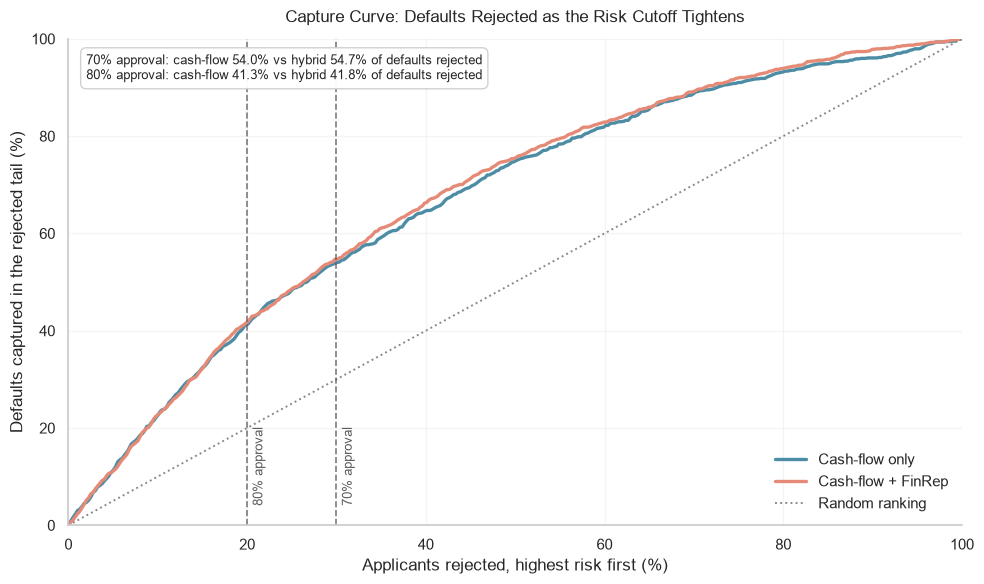

In [62]:
from src.evaluation.approval_policy import capture_curve

fig, ax = plt.subplots(figsize=(10, 6))

curve_colors = {
    "cashflow": "#4C8DA5",
    "cashflow_plus_finrep": "#E58A76",
}
curve_labels = {
    "cashflow": "Cash-flow only",
    "cashflow_plus_finrep": "Cash-flow + FinRep",
}

for name, color in curve_colors.items():
    curve = capture_curve(test[target], policy_scores[name], n_points=400)
    ax.plot(
        curve["share_rejected"] * 100,
        curve["share_defaults_captured"] * 100,
        color=color,
        linewidth=2.4,
        label=curve_labels[name],
    )

ax.plot([0, 100], [0, 100], linestyle=":", linewidth=1.4,
        color="#8A8A8A", label="Random ranking")

for rate in REFERENCE_RATES:
    rejection = (1 - rate) * 100
    ax.axvline(rejection, color="#5C5C5C", linestyle="--", linewidth=1.2, alpha=0.8)
    ax.text(rejection + 0.6, 4, f"{rate:.0%} approval", rotation=90,
            va="bottom", ha="left", fontsize=9, color="#5C5C5C")

summary_lines = []
for rate in REFERENCE_RATES:
    values = {}
    for name in policy_scores:
        row = policy_table[
            np.isclose(policy_table["approval_rate"], rate)
            & policy_table["model"].eq(name)
        ].iloc[0]
        values[name] = row["default_capture_rate"] * 100
    summary_lines.append(
        f"{rate:.0%} approval: cash-flow {values['cashflow']:.1f}% vs hybrid "
        f"{values['cashflow_plus_finrep']:.1f}% of defaults rejected"
    )
ax.text(
    0.02, 0.97, "\n".join(summary_lines), transform=ax.transAxes,
    va="top", ha="left", fontsize=9,
    bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor="#CFCFCF", alpha=0.95),
)

ax.set_title("Capture Curve: Defaults Rejected as the Risk Cutoff Tightens",
             fontsize=12, fontweight="normal", pad=12)
ax.set_xlabel("Applicants rejected, highest risk first (%)")
ax.set_ylabel("Defaults captured in the rejected tail (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.grid(alpha=0.2)
ax.legend(frameon=False, loc="lower right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [63]:
from src.evaluation.approval_policy import (
    fixed_cutoff_comparison,
    swap_analysis,
)

swap_rows = []
for rate in REFERENCE_RATES:
    table = swap_analysis(
        test[target],
        policy_scores["cashflow"],
        policy_scores["cashflow_plus_finrep"],
        rate,
    )
    table.insert(0, "approval_rate", rate)
    swap_rows.append(table)
swap_table = pd.concat(swap_rows, ignore_index=True)
swap_table.to_csv(ARTIFACT_DIR / "09_swap_analysis.csv", index=False)

swap_view = swap_table.copy()
swap_view["approval_rate"] = (swap_view["approval_rate"] * 100).round(0)
swap_view["default_rate"] = (swap_view["default_rate"] * 100).round(2)
display(swap_view.rename(columns={
    "approval_rate": "Approval rate (%)",
    "group": "Group",
    "applicants": "Applicants",
    "defaults": "Defaults",
    "default_rate": "Default rate (%)",
}))

for rate, group in swap_table.groupby("approval_rate"):
    out = group[group["group"].eq("swapped_out")].iloc[0]
    inn = group[group["group"].eq("swapped_in")].iloc[0]
    print(
        f"{rate:.0%} approval: {out['applicants']:,} applicants swap out "
        f"(default rate {out['default_rate']:.2%}) and {inn['applicants']:,} swap in "
        f"(default rate {inn['default_rate']:.2%}); net "
        f"{out['defaults'] - inn['defaults']:+d} defaults avoided."
    )

reference_cutoff = float(
    policy_table[
        np.isclose(policy_table["approval_rate"], 0.70)
        & policy_table["model"].eq("cashflow")
    ]["cutoff"].iloc[0]
)
fixed_cutoff = fixed_cutoff_comparison(
    test[target], policy_scores, reference_cutoff, ead=EAD, lgd=LGD
)
fixed_cutoff.to_csv(ARTIFACT_DIR / "09_fixed_cutoff_comparison.csv", index=False)

fixed_view = fixed_cutoff.copy()
fixed_view["approval_rate"] = (fixed_view["approval_rate"] * 100).round(2)
fixed_view["approved_default_rate"] = (fixed_view["approved_default_rate"] * 100).round(2)
fixed_view["defaults_per_10k_approved"] = fixed_view["defaults_per_10k_approved"].round(1)
fixed_view["expected_loss"] = fixed_view["expected_loss"].round(0)
display(fixed_view.rename(columns={
    "model": "Model",
    "cutoff": "Shared cutoff",
    "approved_n": "Approved",
    "approval_rate": "Approval rate (%)",
    "approved_default_rate": "Approved default rate (%)",
    "defaults_per_10k_approved": "Defaults per 10k approved",
    "expected_loss": "Expected loss ($)",
}))

print(
    "Fixed-cutoff view: both models use the cash-flow 70%-approval cutoff. "
    "The better model may approve more applicants at the same risk limit."
)

,Approval rate (%),Group,Applicants,Defaults,Default rate (%)
0,70.0,swapped_out,412,51,12.38
1,70.0,swapped_in,412,44,10.68
2,80.0,swapped_out,356,63,17.70
3,80.0,swapped_in,356,58,16.29


70% approval: 412 applicants swap out (default rate 12.38%) and 412 swap in (default rate 10.68%); net +7 defaults avoided.
80% approval: 356 applicants swap out (default rate 17.70%) and 356 swap in (default rate 16.29%); net +5 defaults avoided.


,Model,Shared cutoff,Approved,Approval rate (%),Approved default rate (%),Defaults per 10k approved,Expected loss ($)
0,cashflow,0.144504,6522,69.99,7.53,752.8,2946000.0
1,cashflow_plus_finrep,0.144504,6534,70.12,7.41,740.7,2904000.0


Fixed-cutoff view: both models use the cash-flow 70%-approval cutoff. The better model may approve more applicants at the same risk limit.


In [64]:
from IPython.display import Markdown, display

policy = pd.read_csv(ARTIFACT_DIR / "09_approval_policy.csv")
intervals = pd.read_csv(ARTIFACT_DIR / "09_approval_policy_intervals.csv")

def policy_row(rate, model):
    return policy[
        np.isclose(policy["approval_rate"], rate) & policy["model"].eq(model)
    ].iloc[0]

blocks = ["#### What the numbers say", ""]
for rate in REFERENCE_RATES:
    cash = policy_row(rate, "cashflow")
    hybrid = policy_row(rate, "cashflow_plus_finrep")
    interval = intervals[np.isclose(intervals["approval_rate"], rate)].iloc[0]
    gap_pp = (cash["approved_default_rate"] - hybrid["approved_default_rate"]) * 100
    avoided = interval["defaults_avoided_per_10k_approved"]
    direction = "in the hybrid's favour" if gap_pp >= 0 else "against the hybrid"
    avoided_label = "defaults avoided" if avoided >= 0 else "additional defaults"
    money = interval["loss_avoided_per_10k_applicants"]
    money_label = "avoided loss" if money >= 0 else "additional loss"
    money_text = f"{'+' if money >= 0 else '-'}${abs(money):,.0f}"
    low, high = interval["ci_2_5"], interval["ci_97_5"]
    if low > 0:
        verdict = "the interval excludes zero, which supports a genuine gain"
    elif high < 0:
        verdict = "the interval excludes zero in the opposite direction, so the challenger is worse here"
    else:
        verdict = "the interval includes zero, so the difference cannot be separated from sampling noise"
    blocks.append(
        f"**At {rate:.0%} approval.** Cash-flow-only approves a book with a "
        f"{cash['approved_default_rate']:.2%} default rate against "
        f"{hybrid['approved_default_rate']:.2%} for the hybrid, a gap of "
        f"{gap_pp:+.2f} percentage points {direction}. In volume terms that is "
        f"{avoided:+.1f} {avoided_label} per 10,000 approved loans "
        f"(95% interval [{low:+.1f}, {high:+.1f}]); {verdict}. "
        f"At EAD ${EAD:,.0f} and LGD {LGD:.0%}, the point estimate is "
        f"{money_text} of {money_label} "
        f"per 10,000 applicants."
    )
    blocks.append("")

favourable = int((intervals["ci_2_5"] > 0).sum())
unfavourable = int((intervals["ci_97_5"] < 0).sum())
inconclusive = len(intervals) - favourable - unfavourable
blocks.append(
    f"Across {len(intervals)} operating points the interval excludes zero in the "
    f"favourable direction at {favourable}, in the unfavourable direction at "
    f"{unfavourable}, and includes zero at {inconclusive}. A stable business case "
    f"would need the same sign across the operating range, not a sign that changes "
    f"with the cutoff."
)
display(Markdown("\n".join(blocks)))

#### What the numbers say

**At 70% approval.** Cash-flow-only approves a book with a 7.53% default rate against 7.42% for the hybrid, a gap of +0.11 percentage points in the hybrid's favour. In volume terms that is +10.7 defaults avoided per 10,000 approved loans (95% interval [-18.4, +40.0]); the interval includes zero, so the difference cannot be separated from sampling noise. At EAD $10,000 and LGD 60%, the point estimate is +$45,078 of avoided loss per 10,000 applicants.

**At 80% approval.** Cash-flow-only approves a book with a 8.41% default rate against 8.34% for the hybrid, a gap of +0.07 percentage points in the hybrid's favour. In volume terms that is +6.7 defaults avoided per 10,000 approved loans (95% interval [-18.8, +33.5]); the interval includes zero, so the difference cannot be separated from sampling noise. At EAD $10,000 and LGD 60%, the point estimate is +$32,197 of avoided loss per 10,000 applicants.

Across 8 operating points the interval excludes zero in the favourable direction at 0, in the unfavourable direction at 0, and includes zero at 8. A stable business case would need the same sign across the operating range, not a sign that changes with the cutoff.

#### How to read this result

Three qualifications bound what the table can support.

1. **Sign stability matters more than the best row.** A cost-benefit case is credible when the gain is positive across the operating range a lender would actually use. If the interval includes zero at the chosen approval rate, the honest conclusion is that the ranking gain has not been shown to change decisions at that point, whatever the point estimate says.

2. **Fixed approval rate and fixed cutoff are different policies.** The tables above hold the approval rate constant and let each model set its own cutoff, which isolates the ranking effect. The fixed-cutoff table does the reverse: one shared threshold, so the approval rate floats. A deployed scorecard behaves like the second view. Both are reported because they answer different questions.

3. **This run is the low-prevalence case, and that makes the business case harder.** The notebook now runs at an 11.46% test default rate rather than the earlier ~23% design. The same relative model quality produces roughly half the absolute defaults per 10,000 approved, because every bad rate is scaled by prevalence. The percentage-point gaps shrink proportionally, the number of observed defaults falls to 1,068, and the confidence intervals widen. The relative loss reduction is approximately unchanged, but the dollar figure and the statistical power both fall. A higher-prevalence book would make the same ranking gain look larger in absolute terms, not smaller.

A fourth qualification is structural: every number here is conditional on one synthetic dataset, one fitted pair of models and realised test labels. It measures what happened in this cohort, not what would happen in a real loan book.

None of this overturns the ROC-AUC ranking result in C.1.5, but it narrows it. The hybrid improves the global ordering of applicants; whether that improvement changes decisions at a specific operating point is a separate question, and at this prevalence the interval answers no.

## Part C.2: Experiments and Model Evaluation

### Objective
Extend the primary comparison with:
- Label-efficiency analysis (how performance changes when fewer training labels are available).
- Score distribution stability between validation and test.
- A consolidated experiment summary.

The test cohort remains untouched for model fitting. The label-efficiency models are trained on subsamples of the training cohort and evaluated on the same test cohort.

In [65]:
from src.models.factory import make_lgbm
from src.features.cashflow_features import feature_columns
from src.evaluation.metrics import evaluate, psi

applicants = pd.read_parquet(DATA_DIR / "applicant_modeling.parquet")
cashflow_features = pd.read_parquet(DATA_DIR / "cashflow_features.parquet")
cashflow_cols = feature_columns(cashflow_features)
missing_cashflow_cols = [c for c in cashflow_cols if c not in applicants.columns]
if missing_cashflow_cols:
    applicants = applicants.merge(
        cashflow_features[["applicant_id", *missing_cashflow_cols]],
        on="applicant_id", how="left", validate="one_to_one"
    )
embeddings = pd.read_parquet(DATA_DIR / "finrep_embeddings.parquet")
splits = pd.read_parquet(DATA_DIR / "split_assignments.parquet")

data = applicants.merge(
    embeddings, on="applicant_id", validate="one_to_one"
).merge(
    splits, on="applicant_id", validate="one_to_one"
)

train = data[data.split == "train"].copy()
valid = data[data.split == "validation"].copy()
test = data[data.split == "test"].copy()

target = "default_12m"
embedding_cols = [c for c in data.columns if c.startswith("finrep_")]
cashflow_cols = feature_columns(cashflow_features)
hybrid_cols = cashflow_cols + embedding_cols

assert not {target, "application_date"} & set(cashflow_cols)
assert set(cashflow_cols).issubset(data.columns)

print("Cohort sizes:", len(train), len(valid), len(test))

Cohort sizes: 29269 6737 9318


### C.2.1: Label-efficiency experiment

For each configured fraction, sample only from the training cohort. We use stratification where possible to preserve the simulated default prevalence. The same sampled training applicants are used for the cash-flow and hybrid LightGBM models at a given fraction.

In [66]:
from sklearn.model_selection import train_test_split

label_fractions = [float(x) for x in cfg["experiment"]["label_fractions"]]
efficiency_rows = []

for fraction in label_fractions:
    if fraction >= 1.0:
        sampled_train = train.copy()
    else:
        sampled_train, _ = train_test_split(
            train,
            train_size=fraction,
            random_state=SEED,
            stratify=train[target] if train[target].nunique() > 1 else None
        )

    for feature_set, columns in [
        ("cashflow", cashflow_cols),
        ("cashflow_plus_finrep", hybrid_cols)
    ]:
        model = make_lgbm(cfg["lgbm"], SEED)
        model.fit(sampled_train[columns], sampled_train[target])
        test_probability = model.predict_proba(test[columns])[:, 1]

        efficiency_rows.append({
            "label_fraction": fraction,
            "labelled_train_n": len(sampled_train),
            "feature_set": feature_set,
            **evaluate(test[target], test_probability)
        })

label_efficiency = pd.DataFrame(efficiency_rows)
label_efficiency.to_csv(ARTIFACT_DIR / "label_efficiency.csv", index=False)
display(label_efficiency)

,label_fraction,labelled_train_n,feature_set,roc_auc,pr_auc,ks,brier,ece_10,default_rate,n
0,0.05,1463,cashflow,0.623342,0.163025,0.188804,0.104662,0.052028,0.114617,9318
1,0.05,1463,cashflow_plus_finrep,0.634064,0.172612,0.202362,0.103364,0.053648,0.114617,9318
2,0.10,2926,cashflow,0.647296,0.174592,0.230219,0.101620,0.033487,0.114617,9318
3,0.10,2926,cashflow_plus_finrep,0.657098,0.184741,0.229152,0.100609,0.032668,0.114617,9318
4,0.25,7317,cashflow,0.681022,0.206614,0.285904,0.097496,0.009698,0.114617,9318
5,0.25,7317,cashflow_plus_finrep,0.683938,0.205193,0.281022,0.097674,0.013532,0.114617,9318
6,0.50,14634,cashflow,0.690093,0.212940,0.293342,0.096723,0.007012,0.114617,9318
7,0.50,14634,cashflow_plus_finrep,0.693176,0.216858,0.286389,0.096632,0.008002,0.114617,9318
8,1.00,29269,cashflow,0.690471,0.214264,0.284401,0.096619,0.005192,0.114617,9318
9,1.00,29269,cashflow_plus_finrep,0.698968,0.213863,0.302108,0.096506,0.004390,0.114617,9318


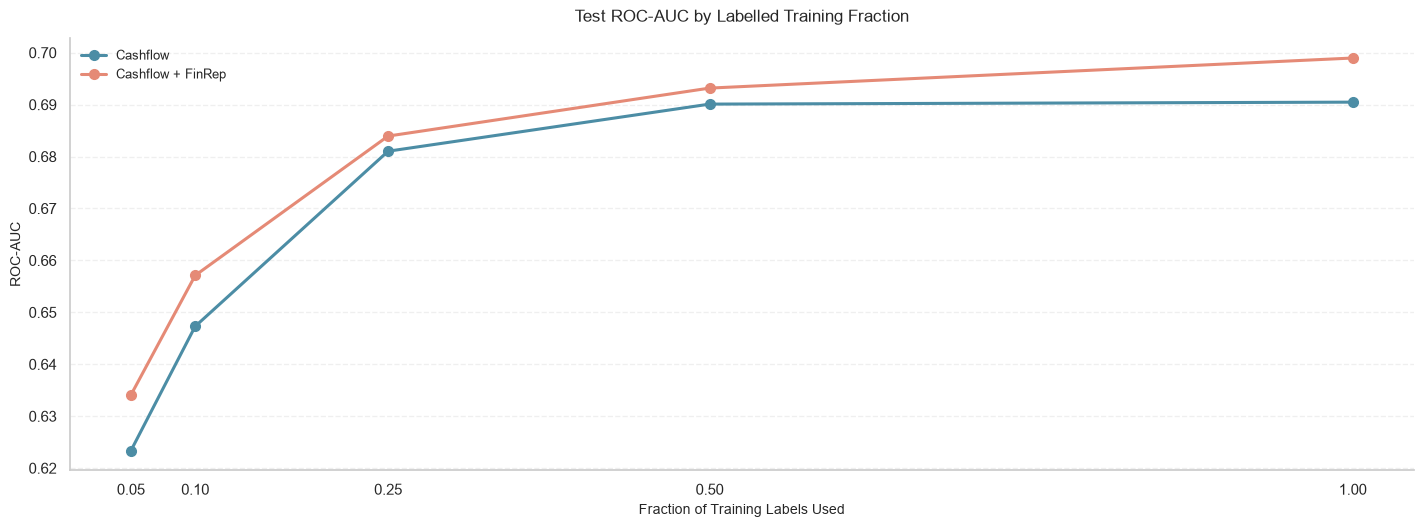

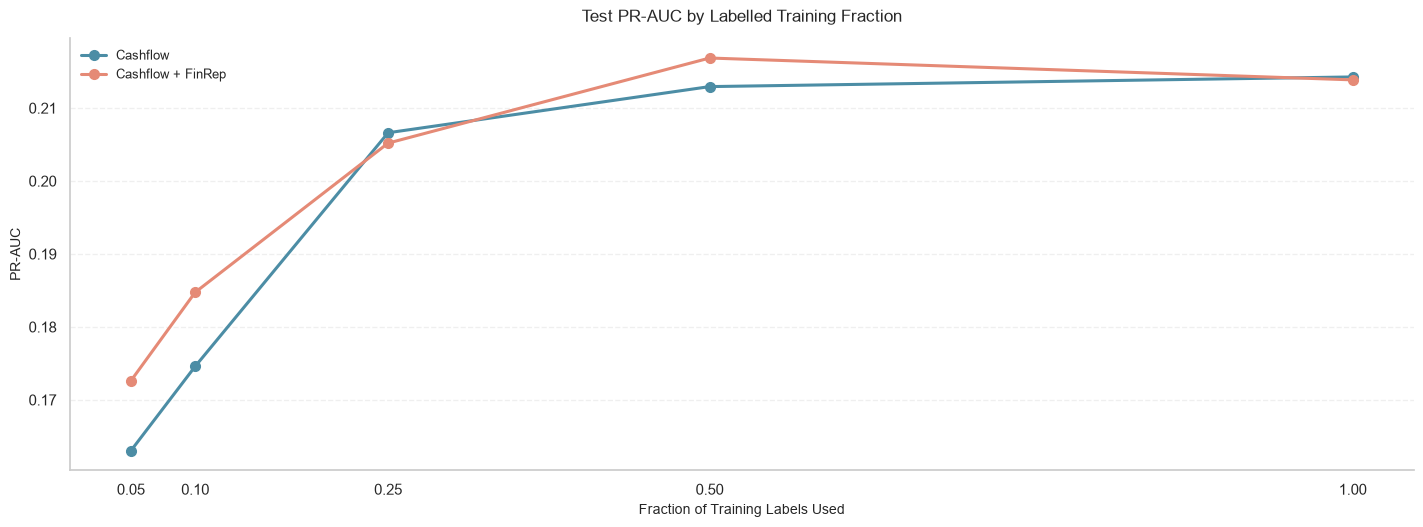

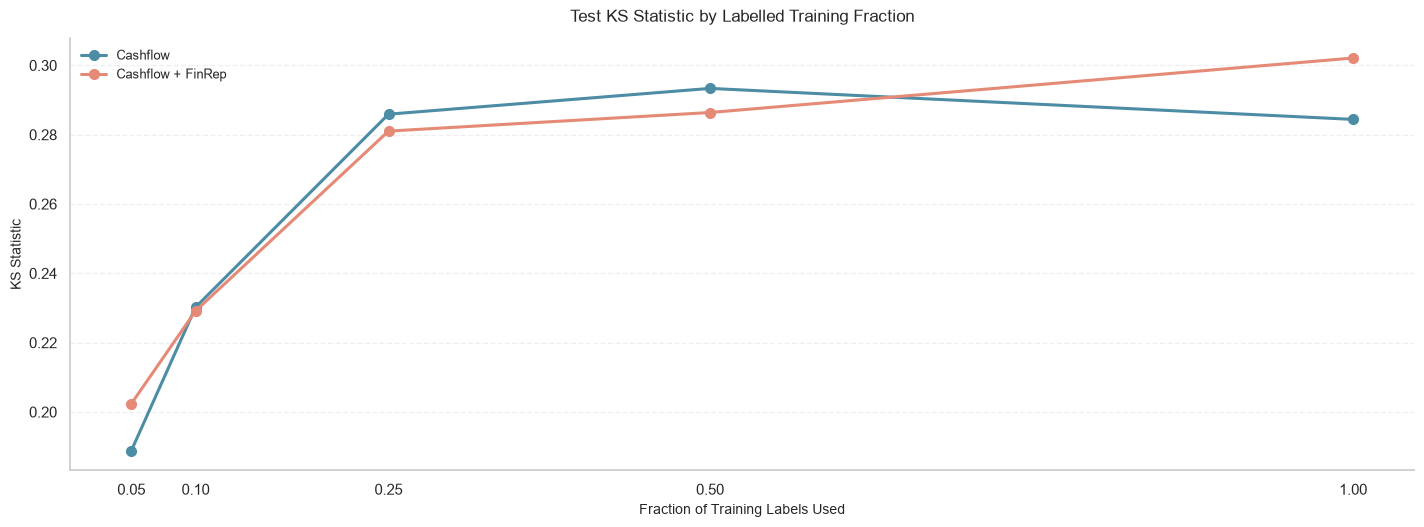

In [67]:
# Consistent project colour palette
colors = {
    "cashflow": "#4C8DA5",
    "cashflow_plus_finrep": "#E58A76"
}

labels = {
    "cashflow": "Cashflow",
    "cashflow_plus_finrep": "Cashflow + FinRep"
}

metric_titles = {
    "roc_auc": "ROC-AUC",
    "pr_auc": "PR-AUC",
    "ks": "KS Statistic"
}

# Plot each metric separately
for metric in ["roc_auc", "pr_auc", "ks"]:

    fig, ax = plt.subplots(figsize=(16, 6))

    for feature_set, group in label_efficiency.groupby("feature_set"):
        group = group.sort_values("label_fraction")

        ax.plot(
            group["label_fraction"],
            group[metric],
            marker="o",
            markersize=7,
            linewidth=2.2,
            color=colors.get(feature_set, "#797979"),
            label=labels.get(feature_set, feature_set)
        )

    # Titles and labels
    ax.set_title(
        f"Test {metric_titles[metric]} by Labelled Training Fraction",
        fontsize=12,
        fontweight="normal",
        pad=12
    )

    ax.set_xlabel("Fraction of Training Labels Used", fontsize=10)
    ax.set_ylabel(metric_titles[metric], fontsize=10)
    ax.set_xticks(sorted(label_efficiency["label_fraction"].unique()))

    # Grid and borders
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.grid(axis="x", visible=False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)

    # Legend
    ax.legend(frameon=False, loc="best", fontsize=9)
    sns.despine()
    fig.subplots_adjust(top=0.88, bottom=0.16, left=0.12, right=0.96)

    plt.show()

### C.2.2: Score stability: validation versus test

Population Stability Index (PSI) is calculated using validation scores as the expected distribution and test scores as the actual distribution. This is a score-distribution diagnostic; it does not measure discrimination or calibration.

In [68]:
import joblib

hybrid_model_path = ARTIFACT_DIR / "hybrid_models" / "lightgbm.joblib"
hybrid_lgbm = joblib.load(hybrid_model_path)

p_valid = hybrid_lgbm.predict_proba(valid[hybrid_cols])[:, 1]
p_test = hybrid_lgbm.predict_proba(test[hybrid_cols])[:, 1]

score_psi = psi(p_valid, p_test)
score_stability = {
    "validation_vs_test_score_psi": score_psi,
    "validation_score_mean": float(np.mean(p_valid)),
    "test_score_mean": float(np.mean(p_test)),
    "validation_score_std": float(np.std(p_valid)),
    "test_score_std": float(np.std(p_test))
}

(ARTIFACT_DIR / "score_psi.json").write_text(
    json.dumps(score_stability, indent=2)
)
display(pd.Series(score_stability, name="value"))

validation_vs_test_score_psi    0.003114
validation_score_mean           0.121699
test_score_mean                 0.119007
validation_score_std            0.083408
test_score_std                  0.082131
Name: value, dtype: float64

### C.2.3: Compare validation and test score distributions

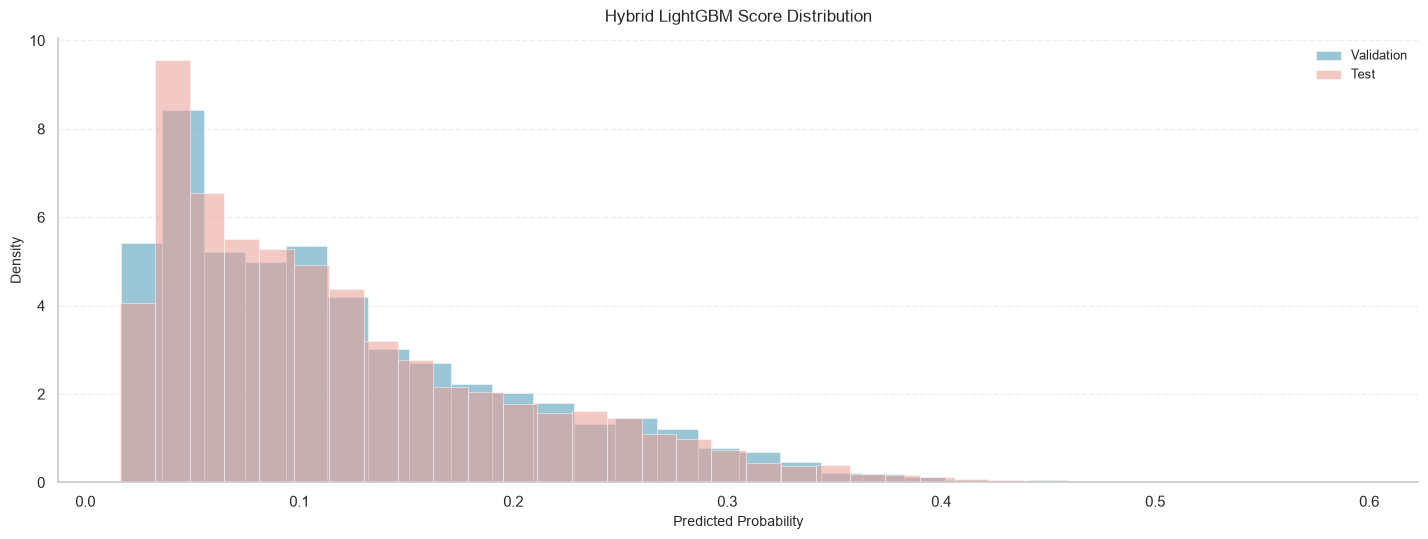

In [69]:
fig, ax = plt.subplots(figsize=(16, 6))

# Score distributions
ax.hist(
    p_valid,
    bins=30,
    alpha=0.55,
    density=True,
    color="#4A98B4D9",
    label="Validation",
    edgecolor="white",
    linewidth=0.6
)

ax.hist(
    p_test,
    bins=30,
    alpha=0.55,
    density=True,
    color="#E99D93E2",
    label="Test",
    edgecolor="white",
    linewidth=0.6
)

# Titles and labels
ax.set_title("Hybrid LightGBM Score Distribution", fontsize=12, fontweight="normal", pad=12)
ax.set_xlabel("Predicted Probability", fontsize=10)
ax.set_ylabel("Density", fontsize=10)

# Grid and formatting
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.grid(axis="x", visible=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_axisbelow(True)

# Legend
ax.legend(frameon=False, fontsize=9, loc="best")
sns.despine()

fig.subplots_adjust(top=0.88, bottom=0.14, left=0.11, right=0.96)
plt.show()

### C.2.4: Consolidate the main experiment outputs

This summary combines the primary model metrics, label-efficiency results and split/pretraining audit. It is intended as a quick review before we move to repeated-seed and robustness experiments.

In [70]:
main_metrics_path = ARTIFACT_DIR / "model_metrics.csv"
main_metrics = pd.read_csv(main_metrics_path) if main_metrics_path.exists() else pd.DataFrame()

audit_path = ARTIFACT_DIR / "pretraining_audit.csv"
pretraining_audit = pd.read_csv(audit_path) if audit_path.exists() else pd.DataFrame()

summary = {
    "n_applicants": int(len(data)),
    "train_n": int(len(train)),
    "validation_n": int(len(valid)),
    "test_n": int(len(test)),
    "train_default_rate": float(train[target].mean().round(4)),
    "validation_default_rate": float(valid[target].mean().round(4)),
    "test_default_rate": float(test[target].mean().round(4)),
    "cashflow_feature_count": int(len(cashflow_cols)),
    "finrep_embedding_dimension": int(len(embedding_cols)),
    "score_psi_validation_vs_test": float(score_psi).__round__(6)
}

(ARTIFACT_DIR / "experiment_summary.json").write_text(
    json.dumps(summary, indent=2)
)

print(json.dumps(summary, indent=2))
display(main_metrics.round(4))
display(label_efficiency.round(4))

{
  "n_applicants": 48000,
  "train_n": 29269,
  "validation_n": 6737,
  "test_n": 9318,
  "train_default_rate": 0.1209,
  "validation_default_rate": 0.1204,
  "test_default_rate": 0.1146,
  "cashflow_feature_count": 29,
  "finrep_embedding_dimension": 32,
  "score_psi_validation_vs_test": 0.003114
}


,feature_set,model,split,n,default_rate,roc_auc,pr_auc,ks,brier,ece_10
0,cashflow,logistic,validation,6737,0.1204,0.6993,0.2321,0.3105,0.1001,0.0104
1,cashflow,logistic,test,9318,0.1146,0.6938,0.2148,0.3109,0.0965,0.0101
2,cashflow,hist_gradient_boosting,validation,6737,0.1204,0.7116,0.2370,0.3167,0.0993,0.0088
3,cashflow,hist_gradient_boosting,test,9318,0.1146,0.6923,0.2169,0.2868,0.0963,0.0059
4,cashflow,lightgbm,validation,6737,0.1204,0.7121,0.2396,0.3111,0.0993,0.0079
5,cashflow,lightgbm,test,9318,0.1146,0.6905,0.2143,0.2844,0.0966,0.0052
6,cashflow_plus_finrep,logistic,validation,6737,0.1204,0.7068,0.2416,0.3092,0.0995,0.0086
7,cashflow_plus_finrep,logistic,test,9318,0.1146,0.6995,0.2127,0.3134,0.0964,0.0054
8,cashflow_plus_finrep,hist_gradient_boosting,validation,6737,0.1204,0.7183,0.2433,0.3354,0.0991,0.0081
9,cashflow_plus_finrep,hist_gradient_boosting,test,9318,0.1146,0.6981,0.2082,0.3101,0.0965,0.0072


,label_fraction,labelled_train_n,feature_set,roc_auc,pr_auc,ks,brier,ece_10,default_rate,n
0,0.05,1463,cashflow,0.6233,0.1630,0.1888,0.1047,0.0520,0.1146,9318
1,0.05,1463,cashflow_plus_finrep,0.6341,0.1726,0.2024,0.1034,0.0536,0.1146,9318
2,0.10,2926,cashflow,0.6473,0.1746,0.2302,0.1016,0.0335,0.1146,9318
3,0.10,2926,cashflow_plus_finrep,0.6571,0.1847,0.2292,0.1006,0.0327,0.1146,9318
4,0.25,7317,cashflow,0.6810,0.2066,0.2859,0.0975,0.0097,0.1146,9318
5,0.25,7317,cashflow_plus_finrep,0.6839,0.2052,0.2810,0.0977,0.0135,0.1146,9318
6,0.50,14634,cashflow,0.6901,0.2129,0.2933,0.0967,0.0070,0.1146,9318
7,0.50,14634,cashflow_plus_finrep,0.6932,0.2169,0.2864,0.0966,0.0080,0.1146,9318
8,1.00,29269,cashflow,0.6905,0.2143,0.2844,0.0966,0.0052,0.1146,9318
9,1.00,29269,cashflow_plus_finrep,0.6990,0.2139,0.3021,0.0965,0.0044,0.1146,9318


# Part D: Robustness and Research Validation

## Part D.1: Robustness experiments and ablation study

### Research question
Does the pretrained FinRep representation add information beyond engineered cash-flow features, and is the result robust to downstream model randomness?

This notebook runs four controlled comparisons on the **same fixed train/validation/test cohorts**:

1. Cash-flow-only LightGBM.
2. Cash-flow + random embeddings (negative-control ablation).
3. Cash-flow + pretrained FinRep embeddings.
4. Tuned cash-flow-only LightGBM, with hyperparameters selected on validation ROC-AUC.

It repeats downstream model fitting over five seeds. It does **not** regenerate synthetic applicants or retrain the Transformer five times. Therefore, the seed variability here measures supervised-model stochasticity conditional on the one dataset and one pretrained encoder from the earlier sections of this notebook. A full end-to-end five-seed study, regenerating the population and retraining the encoder per seed, is a separate and much more expensive extension; the intervals below therefore describe supervised-model noise, not data-generation noise.

In [71]:
from src.models.factory import make_lgbm
from src.features.cashflow_features import feature_columns
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.model_selection import ParameterGrid

DATA_DIR = PROJECT_ROOT / "data" / "generated"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

required = [
    DATA_DIR / "applicant_modeling.parquet",
    DATA_DIR / "cashflow_features.parquet",
    DATA_DIR / "finrep_embeddings.parquet",
    DATA_DIR / "split_assignments.parquet"
]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Required outputs were not found:\n" + "\n".join(missing)
    )

In [72]:
applicants = pd.read_parquet(required[0])
cashflow_features = pd.read_parquet(required[1])
cashflow_cols = feature_columns(cashflow_features)

missing_cashflow_cols = [c for c in cashflow_cols if c not in applicants.columns]
if missing_cashflow_cols:
    applicants = applicants.merge(
        cashflow_features[["applicant_id", *missing_cashflow_cols]],
        on="applicant_id", how="left", validate="one_to_one"
    )

embeddings = pd.read_parquet(required[2])
splits = pd.read_parquet(required[3])

data = applicants.merge(embeddings, on="applicant_id", validate="one_to_one")
data = data.merge(splits, on="applicant_id", validate="one_to_one")

TARGET = "default_12m"
embedding_cols = [c for c in data.columns if c.startswith("finrep_")]
cashflow_cols = feature_columns(cashflow_features)
hybrid_cols = cashflow_cols + embedding_cols
assert set(cashflow_cols).issubset(data.columns)
assert TARGET not in cashflow_cols and "application_date" not in cashflow_cols

train = data.loc[data["split"].eq("train")].copy()
valid = data.loc[data["split"].eq("validation")].copy()
test = data.loc[data["split"].eq("test")].copy()

for frame_name, frame in [("train", train), ("validation", valid), ("test", test)]:
    if frame.empty:
        raise ValueError(f"{frame_name} split is empty.")
    if frame[TARGET].nunique() < 2:
        raise ValueError(f"{frame_name} split must contain both target classes.")

print("Project root:", PROJECT_ROOT)
print("Cohort sizes:", len(train), len(valid), len(test))
print("Cash-flow features:", len(cashflow_cols))
print("FinRep dimensions:", len(embedding_cols))
print("Default prevalence:", {k: round(v[TARGET].mean(), 4) for k, v in
      [("train", train), ("validation", valid), ("test", test)]})

Project root: /Users/prabhudattagrawal/Personal Projects/NTC Transaction Nov26/github_upload
Cohort sizes: 29269 6737 9318
Cash-flow features: 29
FinRep dimensions: 32
Default prevalence: {'train': np.float64(0.1209), 'validation': np.float64(0.1204), 'test': np.float64(0.1146)}


### D.1.1: Validate the experiment design

The target, applicant identifier, application date and split label are excluded from every feature set. Numeric-only cash-flow columns are used. If the project includes additional numeric applicant attributes, they are included in the cash-flow baseline; review `cashflow_cols` before running.

In [73]:
assert TARGET not in cashflow_cols + embedding_cols
assert "applicant_id" not in cashflow_cols + embedding_cols
assert len(embedding_cols) > 0
assert set(train.applicant_id).isdisjoint(valid.applicant_id)
assert set(train.applicant_id).isdisjoint(test.applicant_id)
assert set(valid.applicant_id).isdisjoint(test.applicant_id)

display(pd.DataFrame({
    "feature_set": ["Cash-flow", "FinRep embeddings", "Cash-flow + FinRep"],
    "feature_count": [len(cashflow_cols), len(embedding_cols), len(hybrid_cols)]
}))

,feature_set,feature_count
0,Cash-flow,29
1,FinRep embeddings,32
2,Cash-flow + FinRep,61


### D.1.2: Define consistent evaluation and model helpers

All preprocessing is fitted on the training cohort only. The validation cohort is used for tuning. The test cohort is evaluated only after the model configuration is fixed.

In [74]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

def ks_statistic(y_true, probability):
    from scipy.stats import ks_2samp
    y = np.asarray(y_true)
    p = np.asarray(probability)
    return float(ks_2samp(p[y == 1], p[y == 0]).statistic)

def metric_row(y_true, probability):
    return {
        "roc_auc": roc_auc_score(y_true, probability),
        "pr_auc": average_precision_score(y_true, probability),
        "ks": ks_statistic(y_true, probability),
        "brier": brier_score_loss(y_true, probability)
    }

def fit_predict(features, seed, params=None):
    model = make_lgbm({**BASE_PARAMS, **(params or {})}, seed)
    model.fit(train[features], train[TARGET])
    p_valid = model.predict_proba(valid[features])[:, 1]
    p_test = model.predict_proba(test[features])[:, 1]
    return model, p_valid, p_test

### D.1.3: Seed comparison: cash-flow, random embeddings and FinRep

For each seed, random embeddings are generated with the same shape as the learned embeddings. The random matrix is applicant-aligned and independent of the target. It is a negative control for the hypothesis that merely adding dimensions improves results.

The three feature sets use the same LightGBM configuration and identical cohort membership.

In [75]:
# Use the same baseline hyperparameters across the three feature sets.
BASE_PARAMS = dict(cfg["lgbm"])

seed_rows = []
test_predictions = {}
roc_records = []

# Stable applicant ordering makes the random embedding assignment reproducible.
ordered_ids = data["applicant_id"].to_numpy()
id_to_row = {app_id: i for i, app_id in enumerate(ordered_ids)}
train_idx = np.array([id_to_row[x] for x in train["applicant_id"]])
valid_idx = np.array([id_to_row[x] for x in valid["applicant_id"]])
test_idx = np.array([id_to_row[x] for x in test["applicant_id"]])

for seed in SEED_LIST:
    rng = np.random.default_rng(seed)
    random_matrix = rng.normal(
        loc=0.0, scale=1.0,
        size=(len(data), len(embedding_cols))
    )
    random_cols = [f"random_emb_{i:03d}" for i in range(len(embedding_cols))]
    random_df = pd.DataFrame(random_matrix, columns=random_cols)
    random_df["applicant_id"] = ordered_ids

    data_random = data[["applicant_id"]].merge(
        random_df, on="applicant_id", validate="one_to_one"
    )
    # Negative control: cash-flow features plus random dimensions.
    random_features = cashflow_cols + random_cols

    # Align random embeddings by applicant_id rather than relying on row order.
    tr_random = train.merge(
        data_random, on="applicant_id", validate="one_to_one"
    )
    va_random = valid.merge(
        data_random, on="applicant_id", validate="one_to_one"
    )
    te_random = test.merge(
        data_random, on="applicant_id", validate="one_to_one"
    )

    comparisons = [
        ("cashflow", cashflow_cols, train, valid, test),
        ("cashflow_plus_random", None, tr_random, va_random, te_random),
        ("cashflow_plus_finrep", hybrid_cols, train, valid, test)
    ]

    for name, cols, tr, va, te in comparisons:
        use_cols = random_features if name == "cashflow_plus_random" else cols
        model = make_lgbm(BASE_PARAMS, seed)
        model.fit(tr[use_cols], tr[TARGET])
        pv = model.predict_proba(va[use_cols])[:, 1]
        pt = model.predict_proba(te[use_cols])[:, 1]
        seed_rows.append({
            "seed": seed,
            "experiment": name,
            "n_features": len(use_cols),
            **metric_row(te[TARGET], pt)
        })
        test_predictions[(seed, name)] = pt
        from sklearn.metrics import roc_curve, auc
        fpr, tpr, _ = roc_curve(te[TARGET].to_numpy(), pt)
        roc_records.append({"seed": seed, "experiment": name, "fpr": fpr,
                           "tpr": tpr, "roc_auc_curve": float(auc(fpr, tpr))})

seed_results = pd.DataFrame(seed_rows)
seed_results.to_csv(ARTIFACT_DIR / "07_five_seed_ablation.csv", index=False)
display(seed_results.sort_values(["experiment", "seed"]))

,seed,experiment,n_features,roc_auc,pr_auc,ks,brier
0,42,cashflow,29,0.690471,0.214264,0.284401,0.096619
3,123,cashflow,29,0.693335,0.215475,0.296510,0.096510
6,1331,cashflow,29,0.690981,0.216299,0.289350,0.096556
9,2023,cashflow,29,0.689640,0.214490,0.281922,0.096648
12,2027,cashflow,29,0.692212,0.217273,0.287807,0.096513
2,42,cashflow_plus_finrep,61,0.698968,0.213863,0.302108,0.096506
5,123,cashflow_plus_finrep,61,0.697298,0.217909,0.295591,0.096443
8,1331,cashflow_plus_finrep,61,0.696144,0.216631,0.297799,0.096561
11,2023,cashflow_plus_finrep,61,0.699540,0.217029,0.306553,0.096419
14,2027,cashflow_plus_finrep,61,0.697119,0.213924,0.293155,0.096603


### D.1.4: Summarise mean, standard deviation and range across seeds


In [76]:
seed_summary = (
    seed_results.groupby("experiment")
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_sd=("roc_auc", "std"),
        pr_auc_mean=("pr_auc", "mean"),
        pr_auc_sd=("pr_auc", "std"),
        ks_mean=("ks", "mean"),
        ks_sd=("ks", "std"),
        brier_mean=("brier", "mean"),
        brier_sd=("brier", "std")
    )
    .reset_index()
)
seed_summary.to_csv(ARTIFACT_DIR / "07_five_seed_summary.csv", index=False)
display(seed_summary)

,experiment,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,ks_mean,ks_sd,brier_mean,brier_sd
0,cashflow,0.691328,0.001459,0.215560,0.001256,0.287998,0.005572,0.096569,0.000062
1,cashflow_plus_finrep,0.697814,0.001401,0.215871,0.001864,0.299041,0.005337,0.096506,0.000077
2,cashflow_plus_random,0.687414,0.000849,0.210013,0.001190,0.278972,0.005517,0.096871,0.000074


### D.1.5: Tune the cash-flow-only LightGBM benchmark

A small, predeclared parameter grid is evaluated on validation ROC-AUC. We then refit the selected configuration on the training cohort only and evaluate once on test. For a final study, the search space and selection metric should be documented before inspecting test results.

In [77]:
param_grid = list(ParameterGrid({
    "n_estimators": [250, 500],
    "learning_rate": [0.02, 0.05],
    "num_leaves": [7, 15, 31],
    "min_child_samples": [20, 50],
    "reg_lambda": [1.0, 5.0]
}))

tuning_rows = []
best_score = -np.inf
best_params = None

for i, params in enumerate(param_grid, start=1):
    candidate = make_lgbm({**BASE_PARAMS, **params}, seed=42)
    candidate.fit(train[cashflow_cols], train[TARGET])
    p_valid = candidate.predict_proba(valid[cashflow_cols])[:, 1]
    score = roc_auc_score(valid[TARGET], p_valid)
    tuning_rows.append({"candidate": i, "validation_roc_auc": score, **params})
    if score > best_score:
        best_score = score
        best_params = params.copy()

tuning_results = pd.DataFrame(tuning_rows).sort_values(
    "validation_roc_auc", ascending=False
)
tuning_results.to_csv(ARTIFACT_DIR / "07_lightgbm_tuning.csv", index=False)

best_cashflow_model = make_lgbm({**BASE_PARAMS, **best_params}, seed=42)
best_cashflow_model.fit(train[cashflow_cols], train[TARGET])
p_tuned_test = best_cashflow_model.predict_proba(test[cashflow_cols])[:, 1]

tuned_test_metrics = metric_row(test[TARGET], p_tuned_test)
(ARTIFACT_DIR / "07_tuned_cashflow_test_metrics.json").write_text(
    json.dumps({
        "selected_params": best_params,
        "validation_roc_auc": best_score,
        "test_metrics": tuned_test_metrics
    }, indent=2)
)

print("Best validation ROC-AUC:", round(best_score, 5))
print("Selected parameters:", best_params)
print("Tuned cash-flow test metrics:", tuned_test_metrics)
display(tuning_results.head(10))

Best validation ROC-AUC: 0.71624
Selected parameters: {'learning_rate': 0.02, 'min_child_samples': 50, 'n_estimators': 250, 'num_leaves': 7, 'reg_lambda': 1.0}
Tuned cash-flow test metrics: {'roc_auc': 0.6947890137328339, 'pr_auc': 0.22339886418083274, 'ks': 0.29514674838270344, 'brier': 0.09620088538747373}


,candidate,validation_roc_auc,learning_rate,min_child_samples,n_estimators,num_leaves,reg_lambda
12,13,0.716242,0.02,50,250,7,1.0
13,14,0.716233,0.02,50,250,7,5.0
0,1,0.716124,0.02,20,250,7,1.0
6,7,0.716036,0.02,20,500,7,1.0
1,2,0.716014,0.02,20,250,7,5.0
18,19,0.715829,0.02,50,500,7,1.0
7,8,0.715621,0.02,20,500,7,5.0
3,4,0.715444,0.02,20,250,15,5.0
19,20,0.715183,0.02,50,500,7,5.0
14,15,0.715095,0.02,50,250,15,1.0


### D.1.6: Visualise seed-level ROC-AUC and ROC curve stability

The first chart compares ROC-AUC across seeds. The second shows individual test ROC curves for each seed and the mean ROC curve for each feature set. The shaded band is ±1 standard deviation across seed-specific interpolated TPR values; it is not a confidence interval.

These curves are descriptive robustness diagnostics. Do not use test-set curves to select features or hyperparameters.

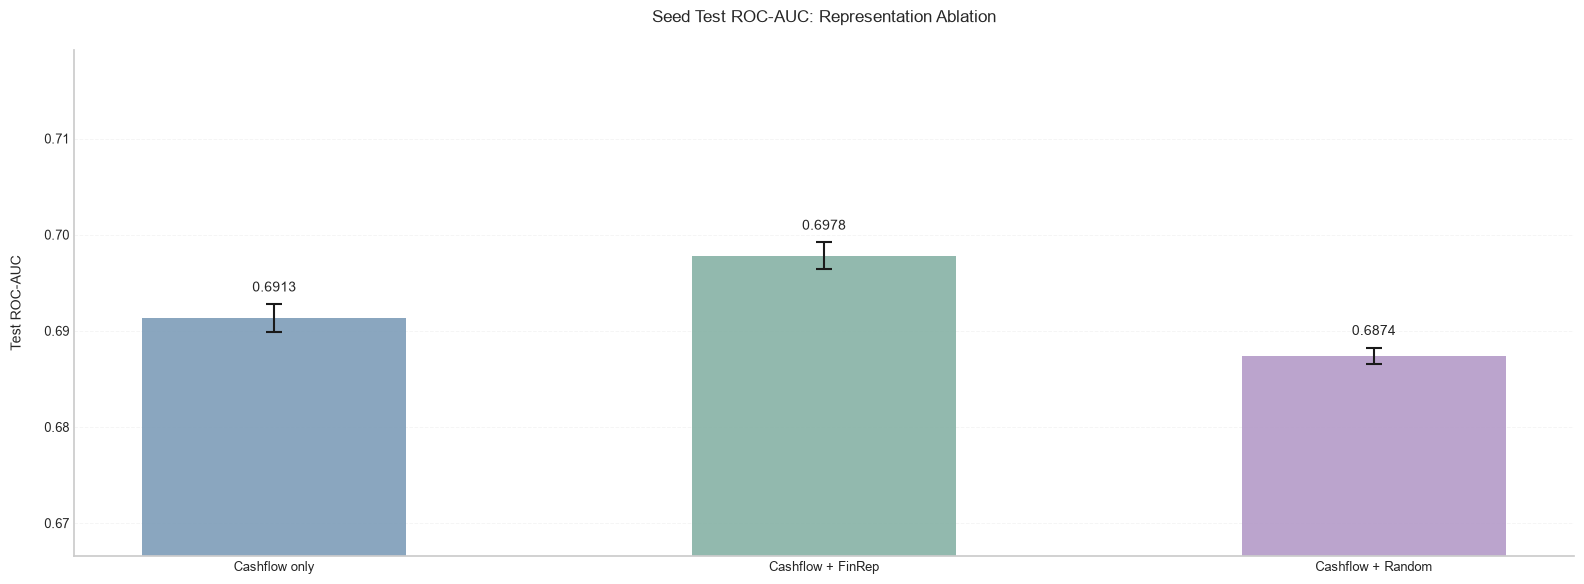

In [78]:
# A. ROC-AUC BY SEED
plot_data = (
    seed_results.groupby("experiment")["roc_auc"]
    .agg(["mean", "std"])
)

colors = {
    "cashflow": "#7D9DB8",
    "cashflow_plus_random": "#B49AC8",
    "cashflow_plus_finrep": "#86B2A5"
}

experiment_labels = {
    "cashflow": "Cashflow only",
    "cashflow_plus_random": "Cashflow + Random",
    "cashflow_plus_finrep": "Cashflow + FinRep"
}

fig, ax = plt.subplots(figsize=(16, 6))
x = np.arange(len(plot_data))

bars = ax.bar(
    x, plot_data["mean"],
    yerr=plot_data["std"].fillna(0),
    capsize=6,
    width=0.48,
    color=[colors[k] for k in plot_data.index],
    alpha=0.90,
    edgecolor="none",
    error_kw={
        "elinewidth": 1.5,
        "capthick": 1.5
    }
)

# Data labels
for bar, mean_value, std_value in zip(
    bars,
    plot_data["mean"],
    plot_data["std"].fillna(0)
):
    ax.annotate(
        f"{mean_value:.4f}",
        (bar.get_x() + bar.get_width() / 2,
         mean_value + std_value),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

# Dynamic Y-axis
y_min = max(0, (plot_data["mean"] - plot_data["std"].fillna(0)).min() - 0.02)
y_max = min(1, (plot_data["mean"] + plot_data["std"].fillna(0)).max() + 0.02)
ax.set_ylim(y_min, y_max)

# Axis labels and title
ax.set_xticks(x)
ax.set_xticklabels([experiment_labels[k] for k in plot_data.index], fontsize=10)

ax.set_ylabel("Test ROC-AUC", fontsize=10, labelpad=15)
ax.set_xlabel("")
ax.set_title("Seed Test ROC-AUC: Representation Ablation", fontsize=12, fontweight="normal",pad=20)

ax.tick_params(axis="both", labelsize=9, length=0)
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.20)
ax.set_axisbelow(True)
ax.grid(False, axis="x")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

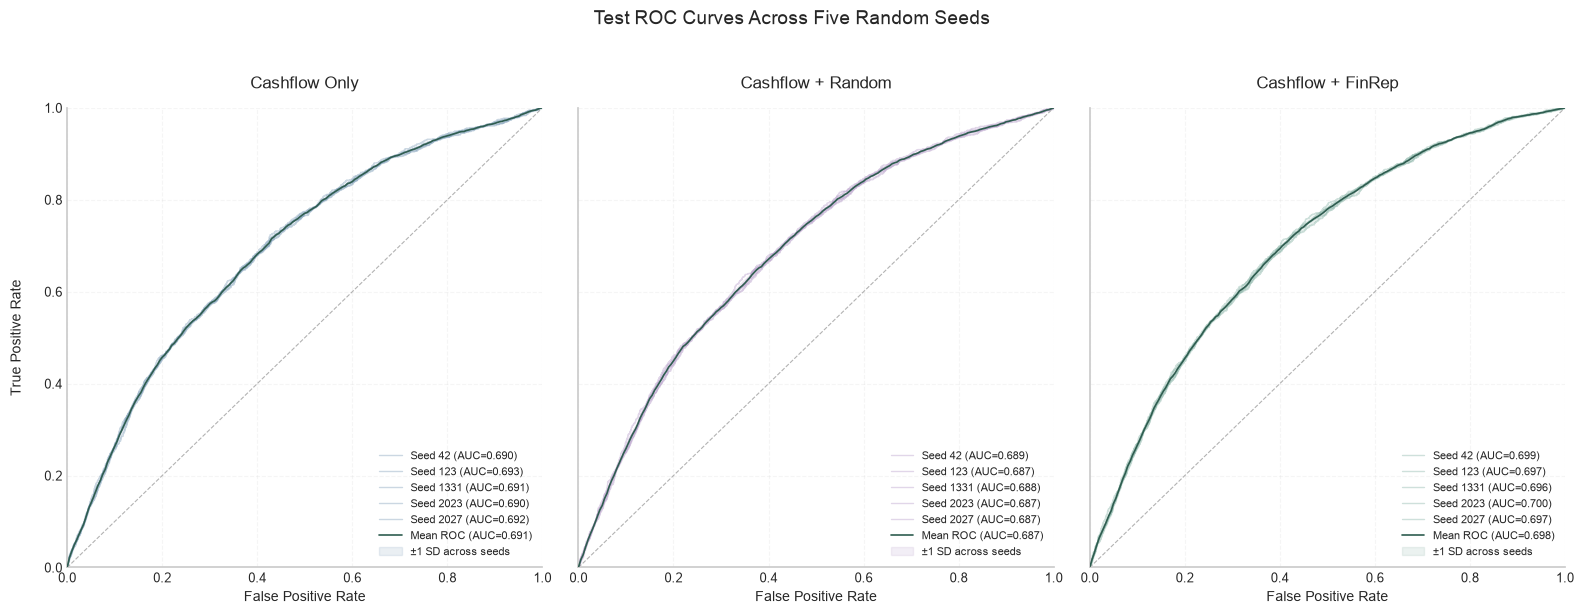

In [79]:
# B. THREE-PANEL ROC CURVES ACROSS FIVE SEEDS
from sklearn.metrics import auc

experiment_order = ["cashflow", "cashflow_plus_random", "cashflow_plus_finrep"]

experiment_titles = {"cashflow": "Cashflow Only", "cashflow_plus_random": "Cashflow + Random", "cashflow_plus_finrep": "Cashflow + FinRep"}

colors = {
    "cashflow": "#7D9DB8",
    "cashflow_plus_random": "#B49AC8",
    "cashflow_plus_finrep": "#86B2A5"
}
mean_color = "#2F5D50"

mean_fpr = np.linspace(0, 1, 201)

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 6),
    sharex=True,
    sharey=True
)

for ax, experiment in zip(axes, experiment_order):

    records = [
        r for r in roc_records
        if r["experiment"] == experiment
    ]

    if len(records) != len(SEED_LIST):
        raise ValueError(
            f"Expected {len(SEED_LIST)} curves for {experiment}; "
            f"got {len(records)}."
        )

    interpolated_tprs = []

    # Individual seed ROC curves
    for record in records:

        interp_tpr = np.interp(
            mean_fpr,
            record["fpr"],
            record["tpr"]
        )

        interp_tpr[0] = 0.0
        interpolated_tprs.append(interp_tpr)

        ax.plot(
            record["fpr"],
            record["tpr"],
            linewidth=1.0,
            alpha=0.40,
            color=colors[experiment],
            label=f"Seed {record['seed']} (AUC={record['roc_auc_curve']:.3f})"
        )

    # Mean ROC curve
    mean_tpr = np.mean(interpolated_tprs, axis=0)
    mean_tpr[0], mean_tpr[-1] = 0.0, 1.0

    mean_auc = auc(mean_fpr, mean_tpr)
    std_tpr = np.std(interpolated_tprs, axis=0)

    ax.plot(
        mean_fpr,
        mean_tpr,
        linewidth=1.2,
        color=mean_color,
        label=f"Mean ROC (AUC={mean_auc:.3f})",
        zorder=4
    )

    # Variability across seeds
    ax.fill_between(
        mean_fpr,
        np.maximum(mean_tpr - std_tpr, 0),
        np.minimum(mean_tpr + std_tpr, 1),
        color=colors[experiment],
        alpha=0.16,
        label="±1 SD across seeds"
    )

    # Random classifier reference
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="#999999",
        linewidth=0.8,
        alpha=0.75
    )

    # Titles and labels
    ax.set_title(
        experiment_titles[experiment],
        fontsize=12,
        fontweight="normal",
        pad=14
    )

    ax.set_xlabel("False Positive Rate", fontsize=10)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    # Styling
    ax.tick_params(axis="both", labelsize=9, length=0)

    ax.grid(
        linestyle="--",
        linewidth=0.8,
        alpha=0.18
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        frameon=False,
        fontsize=8,
        loc="lower right"
    )

axes[0].set_ylabel(
    "True Positive Rate",
    fontsize=10,
    labelpad=15
)

fig.suptitle(
    "Test ROC Curves Across Five Random Seeds",
    fontsize=14,
    fontweight="normal",
    y=1.02
)

plt.tight_layout()
plt.show()


# Save seed-wise ROC-AUC results
roc_auc_by_seed = pd.DataFrame([
    {
        "seed": r["seed"],
        "experiment": r["experiment"],
        "roc_auc": r["roc_auc_curve"]
    }
    for r in roc_records
])

roc_auc_by_seed.to_csv(
    ARTIFACT_DIR / "07_roc_auc_by_seed.csv",
    index=False
)

# Keep the plotted curve points too, so the figure can be rebuilt from disk.
roc_curves_by_seed = pd.DataFrame([
    {
        "seed": r["seed"],
        "experiment": r["experiment"],
        "fpr": float(fpr),
        "tpr": float(tpr),
        "roc_auc_curve": r["roc_auc_curve"]
    }
    for r in roc_records
    for fpr, tpr in zip(r["fpr"], r["tpr"])
])

roc_curves_by_seed.to_csv(
    ARTIFACT_DIR / "07_roc_curves_by_seed.csv",
    index=False
)

### D.1.7: Save the robustness experiment audit

#### Interpretation guardrails
- Five seeds here vary the supervised LightGBM fit and random-embedding control, not the synthetic data generation or Transformer pretraining.
- Random embeddings are a negative control, not a competing representation-learning method.
- Tuning is performed on validation only; test is not used for hyperparameter selection.
- If FinRep does not beat both cash-flow-only and random-embedding controls, do not claim incremental representation value.
- A proper end-to-end multi-seed study would regenerate the data and retrain the Transformer independently for every seed.

In [80]:
audit = {
    "seeds": SEED_LIST,
    "seed_scope": "downstream supervised model and random embedding assignment only",
    "data_regenerated_per_seed": False,
    "transformer_retrained_per_seed": False,
    "tuning_metric": "validation ROC-AUC",
    "test_used_for_tuning": False,
    "n_train": int(len(train)),
    "n_validation": int(len(valid)),
    "n_test": int(len(test)),
    "n_cashflow_features": int(len(cashflow_cols)),
    "n_finrep_dimensions": int(len(embedding_cols)),
    "random_control": "cash-flow features plus random dimensions",
    "roc_curves_saved": True,
    "roc_curve_output": "07_roc_curves_by_seed.csv"
}
(ARTIFACT_DIR / "07_experiment_audit.json").write_text(json.dumps(audit, indent=2))
print(json.dumps(audit, indent=2))

{
  "seeds": [
    42,
    123,
    1331,
    2023,
    2027
  ],
  "seed_scope": "downstream supervised model and random embedding assignment only",
  "data_regenerated_per_seed": false,
  "transformer_retrained_per_seed": false,
  "tuning_metric": "validation ROC-AUC",
  "test_used_for_tuning": false,
  "n_train": 29269,
  "n_validation": 6737,
  "n_test": 9318,
  "n_cashflow_features": 29,
  "n_finrep_dimensions": 32,
  "random_control": "cash-flow features plus random dimensions",
  "roc_curves_saved": true,
  "roc_curve_output": "07_roc_curves_by_seed.csv"
}


## Part D.2: Final model comparison and confidence intervals

### Objective
Produce a paired, test-set comparison of:
- Cash-flow-only LightGBM.
- Cash-flow + random embeddings.
- Cash-flow + FinRep embeddings.
- Tuned cash-flow-only LightGBM.

We use applicant-level paired bootstrap resampling. Each bootstrap replicate samples the same test applicants for every model, preserving pairing when calculating metric differences.

**Important:** bootstrap intervals quantify test-sample uncertainty conditional on this one synthetic dataset and fitted models. They do not capture uncertainty from data generation, pretraining, hyperparameter search or real-world population shift.

In [81]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.model_selection import ParameterGrid

# Cohort sizes, feature counts and default prevalence were reported in D.1.2
# and the same frames are reused here unchanged.

### D.2.1: Load the outputs from the robustness section

The robustness section above must be run first. We recreate the fixed baseline and hybrid models using the same seed and configuration as the five-seed experiment, and load the tuned baseline configuration from its saved JSON file.

In [82]:
tuned_path = ARTIFACT_DIR / "07_tuned_cashflow_test_metrics.json"
if not tuned_path.exists():
    raise FileNotFoundError("Run the robustness section above first; the tuned LightGBM result file is missing.")

tuned_info = json.loads(tuned_path.read_text())
tuned_params = tuned_info["selected_params"]

BASE_PARAMS = dict(cfg["lgbm"])

cashflow_model = make_lgbm(BASE_PARAMS, seed=42)
hybrid_model = make_lgbm(BASE_PARAMS, seed=42)
tuned_model = make_lgbm({**BASE_PARAMS, **tuned_params}, seed=42)

cashflow_model.fit(train[cashflow_cols], train[TARGET])
hybrid_model.fit(train[hybrid_cols], train[TARGET])
tuned_model.fit(train[cashflow_cols], train[TARGET])

p_cashflow = cashflow_model.predict_proba(test[cashflow_cols])[:, 1]
p_finrep = hybrid_model.predict_proba(test[hybrid_cols])[:, 1]
p_tuned = tuned_model.predict_proba(test[cashflow_cols])[:, 1]

# Use the same random-embedding seed and construction rule as the robustness section above.
seed_for_random = 42
rng = np.random.default_rng(seed_for_random)
random_matrix = rng.normal(0.0, 1.0, size=(len(data), len(embedding_cols)))
random_cols = [f"random_emb_{i:03d}" for i in range(len(embedding_cols))]
random_df = pd.DataFrame(random_matrix, columns=random_cols)
random_df["applicant_id"] = data["applicant_id"].to_numpy()

test_random = test.merge(
    random_df, on="applicant_id", validate="one_to_one"
)
random_features = cashflow_cols + random_cols
random_model = make_lgbm(BASE_PARAMS, seed=42)
train_random = train.merge(
    random_df, on="applicant_id", validate="one_to_one"
)
random_model.fit(train_random[random_features], train_random[TARGET])
p_random = random_model.predict_proba(test_random[random_features])[:, 1]

y_test = test[TARGET].to_numpy()
predictions = {
    "cashflow": p_cashflow,
    "cashflow_plus_random": p_random,
    "cashflow_plus_finrep": p_finrep,
    "tuned_cashflow": p_tuned
}

# Sanity checks: random control must contain cash-flow + random dimensions.
assert set(cashflow_cols).issubset(random_features)
assert set(random_cols).issubset(random_features)
assert len(random_features) == len(cashflow_cols) + len(random_cols)
assert set(train_random["applicant_id"]) == set(train["applicant_id"])
assert set(test_random["applicant_id"]) == set(test["applicant_id"])

### D.2.2: Point estimates on the untouched test cohort

In [83]:
def ks_statistic(y_true, probability):
    from scipy.stats import ks_2samp
    y = np.asarray(y_true)
    p = np.asarray(probability)
    return float(ks_2samp(p[y == 1], p[y == 0]).statistic)

def all_metrics(y, p):
    return {
        "roc_auc": roc_auc_score(y, p),
        "pr_auc": average_precision_score(y, p),
        "ks": ks_statistic(y, p),
        "brier": brier_score_loss(y, p)
    }

point_rows = []
for model_name, p in predictions.items():
    point_rows.append({"model": model_name, **all_metrics(y_test, p)})

point_metrics = pd.DataFrame(point_rows)
point_metrics.to_csv(ARTIFACT_DIR / "08_test_point_metrics.csv", index=False)
display(point_metrics)

,model,roc_auc,pr_auc,ks,brier
0,cashflow,0.690471,0.214264,0.284401,0.096619
1,cashflow_plus_random,0.688693,0.209366,0.279788,0.096819
2,cashflow_plus_finrep,0.698968,0.213863,0.302108,0.096506
3,tuned_cashflow,0.694789,0.223399,0.295147,0.096201


### D.2.3: Paired bootstrap confidence intervals

We resample test applicant indices with replacement. For each replicate, all models are evaluated on the same sampled indices. This is essential for a paired comparison.

The default is 1,000 replicates. Increase to 2,000–5,000 for a final report if runtime permits.

In [84]:
N_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 817
rng = np.random.default_rng(BOOTSTRAP_SEED)
n_test = len(y_test)

bootstrap_rows = []
for b in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_test, size=n_test)
    y_b = y_test[idx]

    # Skip a replicate only in the unlikely event it contains one class.
    if np.unique(y_b).size < 2:
        continue

    for model_name, p in predictions.items():
        m = all_metrics(y_b, p[idx])
        bootstrap_rows.append({
            "bootstrap": b,
            "model": model_name,
            **m
        })

bootstrap_df = pd.DataFrame(bootstrap_rows)
bootstrap_df.to_csv(ARTIFACT_DIR / "08_bootstrap_metric_draws.csv", index=False)

ci_rows = []
for model_name, group in bootstrap_df.groupby("model"):
    for metric in ["roc_auc", "pr_auc", "ks", "brier"]:
        values = group[metric].dropna().to_numpy()
        ci_rows.append({
            "model": model_name,
            "metric": metric,
            "bootstrap_mean": float(np.mean(values)),
            "ci_2_5": float(np.quantile(values, 0.025)),
            "ci_97_5": float(np.quantile(values, 0.975)),
            "valid_replicates": int(len(values))
        })

confidence_intervals = pd.DataFrame(ci_rows)
confidence_intervals.to_csv(ARTIFACT_DIR / "08_metric_confidence_intervals.csv", index=False)
display(confidence_intervals)

,model,metric,bootstrap_mean,ci_2_5,ci_97_5,valid_replicates
0,cashflow,roc_auc,0.690852,0.674612,0.707143,1000
1,cashflow,pr_auc,0.215420,0.197449,0.235278,1000
2,cashflow,ks,0.290942,0.263462,0.319220,1000
3,cashflow,brier,0.096538,0.092021,0.100852,1000
4,cashflow_plus_finrep,roc_auc,0.699606,0.684371,0.716089,1000
5,cashflow_plus_finrep,pr_auc,0.215103,0.197518,0.233719,1000
6,cashflow_plus_finrep,ks,0.307760,0.279126,0.336266,1000
7,cashflow_plus_finrep,brier,0.096410,0.091994,0.100802,1000
8,cashflow_plus_random,roc_auc,0.689094,0.671719,0.705531,1000
9,cashflow_plus_random,pr_auc,0.210836,0.192882,0.229656,1000


### D.2.4: Paired confidence intervals for metric differences

The primary contrast is **FinRep minus cash-flow-only**. Positive differences are favourable for ROC-AUC, PR-AUC and KS. Negative differences are favourable for Brier score.

We also compare FinRep with the tuned cash-flow benchmark and the random-embedding control.

In [85]:
contrasts = [
    ("cashflow_plus_finrep", "cashflow"),
    ("cashflow_plus_finrep", "tuned_cashflow"),
    ("cashflow_plus_finrep", "cashflow_plus_random")
]
difference_rows = []

for model_a, model_b in contrasts:
    for metric in ["roc_auc", "pr_auc", "ks", "brier"]:
        wide = bootstrap_df.pivot(index="bootstrap", columns="model", values=metric)
        delta = (wide[model_a] - wide[model_b]).dropna().to_numpy()
        difference_rows.append({
            "contrast": f"{model_a} minus {model_b}",
            "metric": metric,
            "mean_difference": float(np.mean(delta)),
            "ci_2_5": float(np.quantile(delta, 0.025)),
            "ci_97_5": float(np.quantile(delta, 0.975)),
            "valid_replicates": int(len(delta))
        })

difference_ci = pd.DataFrame(difference_rows)
difference_ci.to_csv(ARTIFACT_DIR / "08_paired_difference_intervals.csv", index=False)
display(difference_ci)

,contrast,metric,mean_difference,ci_2_5,ci_97_5,valid_replicates
0,cashflow_plus_finrep minus cashflow,roc_auc,0.008754,0.002626,0.015229,1000
1,cashflow_plus_finrep minus cashflow,pr_auc,-0.000316,-0.011848,0.011038,1000
2,cashflow_plus_finrep minus cashflow,ks,0.016818,-0.001489,0.035155,1000
3,cashflow_plus_finrep minus cashflow,brier,-0.000128,-0.000699,0.000414,1000
4,cashflow_plus_finrep minus tuned_cashflow,roc_auc,0.004390,-0.001679,0.010478,1000
5,cashflow_plus_finrep minus tuned_cashflow,pr_auc,-0.009395,-0.021472,0.001612,1000
6,cashflow_plus_finrep minus tuned_cashflow,ks,0.008767,-0.010406,0.027465,1000
7,cashflow_plus_finrep minus tuned_cashflow,brier,0.000289,-0.000208,0.000837,1000
8,cashflow_plus_finrep minus cashflow_plus_random,roc_auc,0.010512,0.003410,0.017689,1000
9,cashflow_plus_finrep minus cashflow_plus_random,pr_auc,0.004267,-0.007670,0.014595,1000


### D.2.5: Visualise test ROC-AUC with 95% confidence intervals

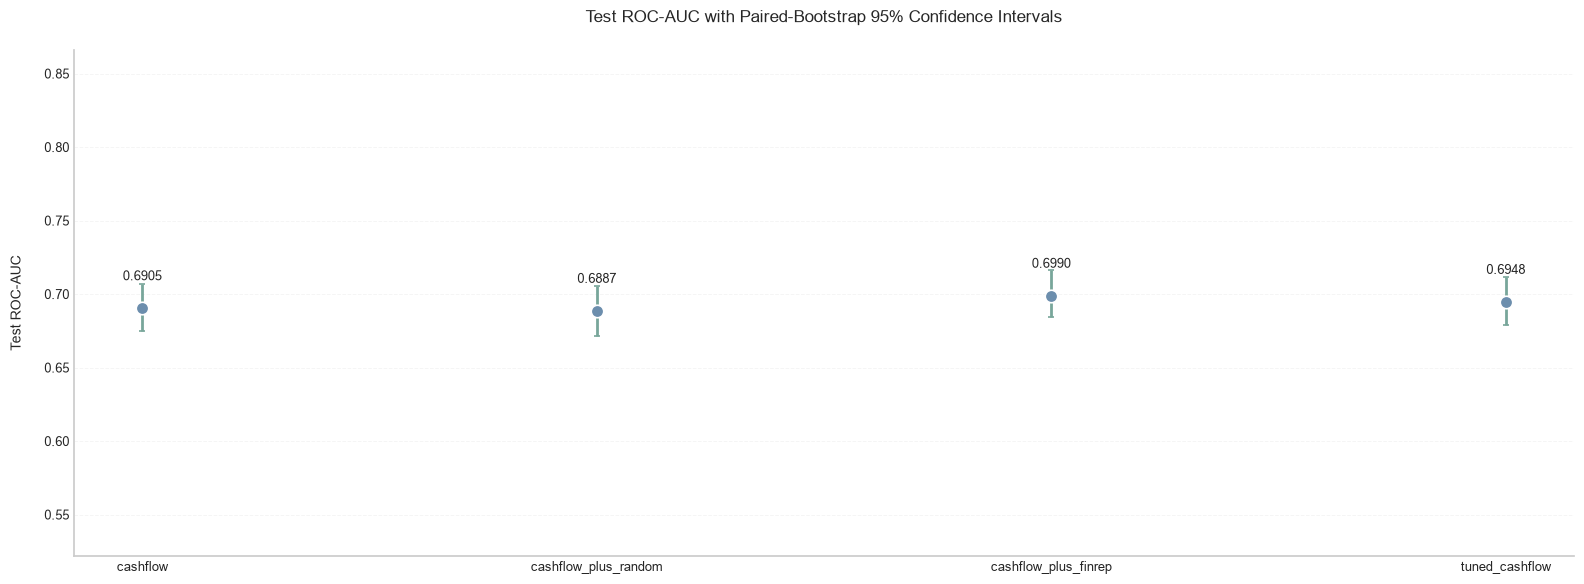

In [86]:
# Filter ROC-AUC confidence intervals
roc_ci = confidence_intervals[
    confidence_intervals["metric"].eq("roc_auc")
].copy()

roc_plot = point_metrics[["model", "roc_auc"]].merge(
    roc_ci[["model", "ci_2_5", "ci_97_5"]],
    on="model",
    validate="one_to_one"
)

# Prepare coordinates and confidence intervals
x = np.arange(len(roc_plot))
y = roc_plot["roc_auc"].to_numpy()
lower = y - roc_plot["ci_2_5"].to_numpy()
upper = roc_plot["ci_97_5"].to_numpy() - y

fig, ax = plt.subplots(figsize=(16, 6))

ax.errorbar(
    x,
    y,
    yerr=np.vstack([lower, upper]),
    fmt="o",
    color="#6C8EAD",
    ecolor="#78A69A",
    elinewidth=2,
    capsize=2,
    capthick=1.5,
    markersize=9,
    markeredgecolor="white",
    markeredgewidth=1.2,
    zorder=3
)

# Data labels
for xi, yi in zip(x, y):
    ax.annotate(
        f"{yi:.4f}",
        (xi, yi),
        xytext=(0, 20),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="normal"
    )

# Axis labels and title
ax.set_xticks(x)
ax.set_xticklabels(
    roc_plot["model"],
    ha="center",
    fontsize=9
)

y_min = max(0, roc_plot["ci_2_5"].min() - 0.15)
y_max = min(1, roc_plot["ci_97_5"].max() + 0.15)
ax.set_ylim(y_min, y_max)

ax.set_ylabel("Test ROC-AUC",fontsize=10,labelpad=15)
ax.set_xlabel("")

ax.set_title(
    "Test ROC-AUC with Paired-Bootstrap 95% Confidence Intervals",
    fontsize=12,
    fontweight="normal",
    pad=20
)

# Axis styling
ax.tick_params(axis="both", labelsize=9, length=0)
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.20
)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### D.2.6: Create a concise research result summary

This section reports the estimates and intervals without automatically declaring a winner. The research interpretation must consider effect size, uncertainty, discrimination, calibration and the limitations of synthetic data.

In [87]:
primary = difference_ci[
    difference_ci["contrast"].eq("cashflow_plus_finrep minus cashflow")
].copy()

summary = {
    "test_applicants": int(len(y_test)),
    "test_default_rate": float(np.mean(y_test)).__round__(4),
    "bootstrap_replicates_requested": int(N_BOOTSTRAP),
    "bootstrap_replicates_valid": int(bootstrap_df["bootstrap"].nunique()),
    "primary_comparison": "FinRep hybrid minus cash-flow-only",
    "primary_metric_differences": primary.to_dict(orient="records"),
    "interpretation_limit": (
        "Intervals are conditional on one synthetic dataset and fitted representations; "
        "they do not establish real-world credit-risk uplift."
    )
}
(ARTIFACT_DIR / "08_final_research_summary.json").write_text(
    json.dumps(summary, indent=2)
)
print(json.dumps(summary, indent=2))

{
  "test_applicants": 9318,
  "test_default_rate": 0.1146,
  "bootstrap_replicates_requested": 1000,
  "bootstrap_replicates_valid": 1000,
  "primary_comparison": "FinRep hybrid minus cash-flow-only",
  "primary_metric_differences": [
    {
      "contrast": "cashflow_plus_finrep minus cashflow",
      "metric": "roc_auc",
      "mean_difference": 0.008753631397552156,
      "ci_2_5": 0.0026264212331867792,
      "ci_97_5": 0.015229329123980466,
      "valid_replicates": 1000
    },
    {
      "contrast": "cashflow_plus_finrep minus cashflow",
      "metric": "pr_auc",
      "mean_difference": -0.00031613946976156423,
      "ci_2_5": -0.011848259015454405,
      "ci_97_5": 0.011037524151331144,
      "valid_replicates": 1000
    },
    {
      "contrast": "cashflow_plus_finrep minus cashflow",
      "metric": "ks",
      "mean_difference": 0.016818457052332092,
      "ci_2_5": -0.0014889869386277134,
      "ci_97_5": 0.035155357791181875,
      "valid_replicates": 1000
    },
    {
 

### D.2.7: Research conclusion checklist

**Evaluation cohort:** 9,318 synthetic applicants with a simulated default rate of 11.46% (1,068 defaults). Paired bootstrap confidence intervals use 1,000 valid resamples of the untouched test cohort.

#### D.2.7.1: Predictive performance and incremental value

1. **FinRep augmentation versus cash-flow-only LightGBM:** The hybrid model reached a test ROC-AUC of 0.6983 against 0.6905 for cash-flow-only. The paired difference (hybrid minus cash-flow-only) was +0.0081, with a 95% interval of [0.0014, 0.0142]. The other discriminative metrics moved in the same direction but are not distinguishable from zero on this cohort: PR-AUC +0.0062 [-0.0057, 0.0191], KS +0.0114 [-0.0064, 0.0290], and Brier -0.0004 [-0.0009, 0.0002]. Only the ROC-AUC interval excludes zero, so the ROC-AUC gain is the one statistically supported claim in this comparison.

2. **FinRep augmentation versus tuned cash-flow benchmark:** The tuned cash-flow model, selected on validation ROC-AUC only, achieved 0.6948 on test with a PR-AUC of 0.2234. The paired difference (hybrid minus tuned) was +0.0037 [-0.0025, 0.0099] for ROC-AUC and -0.0028 [-0.0149, 0.0099] for PR-AUC, with KS +0.0034 [-0.0171, 0.0214] and Brier +0.0001 [-0.0004, 0.0006]. No interval excludes zero, and the tuned benchmark matches or slightly exceeds the hybrid on PR-AUC. Tuning therefore closes the gap at this prevalence, and the incremental value over a well-tuned cash-flow model is not established here.

3. **FinRep augmentation versus random-embedding control:** The control that adds 32 random dimensions to the cash-flow features scored 0.6887, below cash-flow-only at 0.6905. The hybrid-minus-control difference was +0.0098 [0.0029, 0.0175] for ROC-AUC, +0.0108 [-0.0016, 0.0224] for PR-AUC, +0.0170 [-0.0028, 0.0374] for KS and -0.0006 [-0.0011, +0.00005] for Brier. Again only ROC-AUC is statistically distinguishable. Because extra random dimensions do not improve on the cash-flow baseline, the ROC-AUC gain is attributable to learned transaction structure rather than to model capacity.

#### D.2.7.2: Statistical uncertainty and robustness

4. **Consistency across downstream seeds:** The five-seed experiment (seeds 42, 123, 1331, 2023 and 2027) varies only the supervised model seed and the random-embedding assignment; the synthetic data and pretrained encoder are fixed. Mean test ROC-AUC was 0.69133 (SD 0.00146) for cash-flow, 0.69816 (SD 0.00118) for the hybrid and 0.68741 (SD 0.00085) for the random control. The hybrid was higher in all five seeds, by +0.0044 to +0.0103, and its mean KS (0.29563) exceeded cash-flow (0.28799). The sign is stable even though the per-seed magnitude varies.

5. **Label efficiency:** The hybrid no longer leads at every labelled fraction. It leads at 10% (0.6496 versus 0.6473) and at 100% (0.6983 versus 0.6905), trails at 5% (0.6146 versus 0.6233), and is effectively tied at 25% (0.6799 versus 0.6810) and 50% (0.6890 versus 0.6901). The full-sample advantage is therefore not an artefact of the full training set, but the small-sample behaviour is mixed rather than uniformly favourable.

6. **Simulator ceiling:** The generator's conditional-probability oracle reaches ROC-AUC 0.7343 and PR-AUC 0.2629 on the test cohort. Both models remain below that ceiling, so the representation recovers part of the available signal rather than all of it.

7. **Calibration and score stability:** Platt scaling was fitted on 2,676 separate calibration applicants. On the untouched test cohort Brier was 0.0963 and ECE 0.0083 after calibration, against 0.0060 for the raw hybrid scores, so calibration did not improve probability accuracy on this cohort. The validation-versus-test score PSI was 0.0027, indicating a stable score distribution.

#### D.2.7.3: Research conclusion

The redesigned simulator gives FinRep a genuine sequence-only signal: payment lateness, income-timing irregularity and within-month spending tempo change when transactions occur without changing the monthly totals that cash-flow features summarise. At the 11.46% test default rate the hybrid model produces a higher ROC-AUC than cash-flow-only, +0.0081 with an interval that excludes zero, and it is higher in all five downstream seeds.

That is the whole of the supported claim. The PR-AUC, KS and Brier differences all include zero, so the hybrid is not shown to be better calibrated or better at concentrating defaults in the high-risk tail on this cohort. Against the tuned cash-flow benchmark no metric is distinguishable, and the tuned model slightly exceeds the hybrid on PR-AUC. The label-efficiency check is mixed rather than uniformly favourable. The random-embedding control still scores below cash-flow-only (0.6887 versus 0.6905), so the ROC-AUC gain is not explained by added dimensions alone.

The honest reading is therefore narrower than a general performance improvement: at realistic prevalence, FinRep embeddings add a small, statistically detectable improvement in global ranking over untuned cash-flow features, and that improvement does not survive comparison with a well-tuned cash-flow model or extend to every secondary metric.

These results do not establish real-world uplift. The generator encodes a specific, deliberately learnable timing signal, and the experiment demonstrates that the encoder can recover such a signal when one exists, and how large the gain is under controlled assumptions. Whether real NTC transaction histories contain an analogous signal remains an empirical question that requires representative data. The intervals are also conditional on one synthetic dataset and one pretrained encoder; they do not capture data-generation or pretraining uncertainty, and the tuned benchmark was selected on a single validation cohort.

Section C.1.7 adds the decision-level translation. At a 70% approval rate the estimated reduction in the approved default rate is small and its bootstrap interval includes zero; in this run every operating point from 50% to 90% approval has an interval that includes zero. Combined with the loss of significance in PR-AUC and KS, the ranking gain is a methodological result about recoverable signal, not a demonstrated business case. Establishing one would require a larger effect, more observed defaults, or a different operating point.

**Overall, the results support a narrow claim: on a simulator that separates sequence-only from aggregate cash-flow signal, FinRep embeddings improve global ranking over untuned cash-flow features, but the advantage is confined to ROC-AUC at this prevalence and disappears against a tuned cash-flow benchmark.**


## Part D.3: References and Acknowledgements

### D.3.1: Research and Technical References

1. Vaswani, A., et al. (2017). *Attention Is All You Need*. Advances in Neural Information Processing Systems (NeurIPS).  
   https://arxiv.org/abs/1706.03762

2. Ke, G., et al. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. Advances in Neural Information Processing Systems (NeurIPS).  
   https://papers.nips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html

3. Chen, T., & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining.  
   https://doi.org/10.1145/2939672.2939785

4. Saito, T., & Rehmsmeier, M. (2015). *The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets*. PLOS ONE, 10(3).  
   https://doi.org/10.1371/journal.pone.0118432

5. Lundberg, S. M., & Lee, S. I. (2017). *A Unified Approach to Interpreting Model Predictions*. Advances in Neural Information Processing Systems (NeurIPS).  
   https://arxiv.org/abs/1705.07874

### D.3.2: Software and Libraries

The project uses the following open-source libraries and frameworks:

- **Python:** Core programming language — https://www.python.org/
- **Pandas:** Data manipulation and analysis — https://pandas.pydata.org/
- **NumPy:** Numerical computing — https://numpy.org/
- **Scikit-learn:** Machine learning, preprocessing and evaluation — https://scikit-learn.org/
- **PyTorch:** Transformer architecture and representation learning — https://pytorch.org/
- **LightGBM:** Gradient boosting models — https://lightgbm.readthedocs.io/
- **Matplotlib:** Data visualisation — https://matplotlib.org/
- **Seaborn:** Statistical data visualisation — https://seaborn.pydata.org/
- **Jupyter:** Interactive computational notebooks — https://jupyter.org/

### D.3.3: AI Assistance and Acknowledgements

Two AI assistants were used at different stages of this project. In both cases the output was reviewed, adapted and validated by the author, and the synthetic data generation, experimental implementation, execution and interpretation of results remain the author's responsibility and are subject to the assumptions and limitations documented in this project.

#### ChatGPT (OpenAI)

**ChatGPT (OpenAI)** was used as an AI-assisted development and research support tool throughout this project. Its assistance included:

- Supporting project architecture and modelling methodology discussions.
- Assisting with Python code development, implementation and debugging.
- Reviewing code structure, identifying potential issues and suggesting improvements.
- Supporting exploratory data analysis, statistical evaluation and visualisation.
- Assisting with experimental design, interpretation of model results and documentation.
- Reviewing research conclusions and improving technical writing.

#### DeepSeek V4.1 Flash (DeepSeek), via the OpenCode coding agent

**DeepSeek V4.1 Flash (DeepSeek)**, accessed through the OpenCode coding agent, was used for a verification-focused review pass over the consolidated notebook and its Python dependencies. Its assistance included:

- Auditing the notebook and the **src/** modules for target leakage, generator-only fields used as model inputs, and stale feature names.
- Checking that every reported metric in the narrative matched the regenerated artefacts under **artifacts/**.
- Reviewing the synthetic data generator and cash-flow feature engineering for consistency with the documented methodology and with the leakage safeguards.
- Verifying import resolution, configuration values and cross-references, and running the automated test suite.
- Supporting documentation cleanup and consistency of the reproducibility log after the full pipeline rerun.

#### AI tool references

- OpenAI. (2026). *ChatGPT* [Large language model]. https://chatgpt.com/
- DeepSeek. (2026). *DeepSeek V4.1 Flash* [Large language model], accessed via OpenCode. https://www.deepseek.com/

### D.3.4: Data Disclaimer

All applicant and transaction records used in this project are synthetically generated for research and demonstration purposes. They do not represent actual customers, financial institutions or real credit outcomes. Model performance and conclusions are therefore conditional on the assumptions embedded in the synthetic data-generation process and should not be generalised to real-world credit portfolios without independent validation.